# 레고랜드 사태 전후 우량 회사채 신용스프레드 + 단기자금시장(CD·CP) (v5)
이 파일 하나를 Google Colab에 업로드한 후 **런타임 → 모두 실행**을 선택하세요. 무료 CPU 런타임으로 충분합니다.

- **기본 분석**(API 키 불필요): e-나라지표 HTML을 크롤링해 국고채·회사채 AA-·CD(91일) 월별 금리를 분석합니다.
- **확장 분석**(선택, ECOS API 키 필요): 한국은행 ECOS Open API에서 CP·CD·기준금리·회사채 AA-/BBB-·국고채 **일별** 금리를 받아 충격 전파 순서와 등급별 차이를 분석합니다. 키가 없으면 이 부분만 건너뜁니다(노트북만 올린 경우 저장된 ECOS 원본이 없기 때문).

### ECOS API 키를 비밀로 등록하는 방법 (코드에 직접 쓰지 마세요)
1. https://ecos.bok.or.kr/api/ 에서 회원가입 후 인증키를 발급받습니다(무료).
2. Colab 왼쪽 사이드바의 **🔑(보안 비밀)** 아이콘 → **새 보안 비밀 추가**
3. 이름 `ECOS_API_KEY`, 값에 인증키를 붙여넣고 **노트북 액세스**를 켭니다.

공개 월별·일별 값의 비교이며 레고랜드 단독 인과효과 추정은 아닙니다.


In [1]:
# 1. 필요한 라이브러리와 한글 폰트 설치
# Colab에서만 설치합니다. 내 PC에서는 터미널에서 python -m pip install -r requirements.txt 로 설치하세요.
import sys
import subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'requests>=2.31,<3', 'beautifulsoup4>=4.12,<5',
                    'pandas>=2.2,<4', 'matplotlib>=3.8,<4'], check=True)
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'fonts-nanum'], check=True)
    print('설치 완료. 다음 셀부터 순서대로 실행하세요.')
else:
    print('Colab이 아니므로 설치를 건너뜁니다(requirements.txt로 설치된 환경 가정).')


Colab이 아니므로 설치를 건너뜁니다(requirements.txt로 설치된 환경 가정).


## 2. 분석 함수 정의
아래 셀에 requests 요청, BeautifulSoup 추출(국고채·회사채·CD), ECOS API 수집(CP·CD·기준금리·회사채 AA-/BBB-), pandas 전처리, CSV·SQLite 저장, 시각화·보고서 생성 코드가 모두 포함되어 있습니다. 이 셀은 함수를 정의만 하고, 다음 셀에서 실제 수집을 시작합니다.

In [2]:
"""공식 HTML 수집 → BeautifulSoup 추출 → pandas 분석 → CSV/SQLite/그림/보고서.

python legoland_analysis.py           # 네트워크에서 새로 수집
python legoland_analysis.py --offline # 저장한 원본으로 재현
python legoland_analysis.py --offline --check-robots  # 원본은 그대로 두고 robots.txt 판정만 새로 기록

v3 (2026-09-27, 최종): robots 판정 기록·노트북 실행 결과·발표 자료 추가.
v2 (2026-09-27): 계기판 기준을 표본 밖(2019–21) 자료로 산출, 6개월 초과수익 근사 검증,
코로나 비교, 일간 급변 점검, 복귀일 5영업일 연속 기준, raw_date 두 자리 월 저장, robots 판정 분리 기록.

확장(선택): 한국은행 ECOS Open API 일별 금리. 비밀키는 환경변수 또는 Colab 보안 비밀 ECOS_API_KEY로만 넣는다.
  PowerShell:  $env:ECOS_API_KEY = "발급받은키"; python source/legoland_analysis.py
  키가 없으면 ECOS 확장만 건너뛰고 나머지는 그대로 실행된다.
"""
from pathlib import Path
import sys
_HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
# source/ 안에서 실행해도 프로젝트 루트를 기준으로 경로를 잡는다.
ROOT = _HERE.parent if _HERE.name == 'source' else _HERE
if (ROOT / '.python_packages').exists():
    sys.path.insert(0, str(ROOT / '.python_packages'))

import argparse
import hashlib
import html
import urllib.robotparser
import json
import os
import re
import sqlite3
import time
from datetime import datetime, timezone
import importlib.metadata
import requests
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

URL = 'https://www.index.go.kr/unity/potal/main/EachDtlPageDetail.do?idx_cd=1073'
ROBOTS_URL = 'https://www.index.go.kr/robots.txt'
BOK = 'https://www.bok.or.kr/portal/bbs/B0000347/view.do?menuNo=201106&nttId=10075147'
DATA = ROOT / 'data'      # 원본·정제 데이터
RAW = DATA / 'raw'        # 수집 원본 스냅샷
DB = ROOT / 'db'          # SQLite DB
OUT = ROOT / 'output'     # 그래프·통계·보고서
FIG = OUT
BASE_END = '2022-01-01'   # 2019.01–2021.12 = 계기판 기준값·장기 비교에 쓰는 '평소' 기준기간
LABELS = ['상반기\n2022.01–06', '사건 전\n2022.07–09', '경색기\n2022.10–12', '회복기\n2023.01–06']


def save_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')


HEADERS = {
    'User-Agent': 'LegolandCreditSpreadResearch/1.0 (educational, single-page fetch)',
    'Accept-Language': 'ko-KR,ko;q=0.9',
}
ROBOTS_CHECK = RAW / 'robots_check.json'   # 원본을 다시 받지 않고 robots.txt 판정만 기록하는 파일


def check_robots():
    """robots.txt를 받아 대상 페이지 허용 여부를 판정하고 data/raw/robots_check.json에 기록한다.
    404 등으로 robots.txt가 없으면 '판단 보류(None)'로 남긴다. 차단이면 PermissionError."""
    robots = {'url': ROBOTS_URL, 'target_url': URL, 'user_agent': HEADERS['User-Agent'],
              'checked_at_utc': datetime.now(timezone.utc).isoformat(),
              'method': 'check_robots() — requests로 robots.txt 요청 후 urllib.robotparser로 판정'}
    try:
        rb = requests.get(ROBOTS_URL, headers=HEADERS, timeout=(10, 30))
        robots['http_status'] = rb.status_code
        if rb.ok:
            (RAW / 'robots.txt').write_text(rb.text, encoding='utf-8')
            parser = urllib.robotparser.RobotFileParser()
            parser.parse(rb.text.splitlines())
            robots['allowed_for_target'] = parser.can_fetch(HEADERS['User-Agent'], URL)
        else:
            robots['allowed_for_target'] = None   # robots.txt가 없거나 받을 수 없음 → 판단 보류로 기록
    except requests.RequestException as e:
        robots['error'] = type(e).__name__
    save_json(ROBOTS_CHECK, robots)
    if robots.get('allowed_for_target') is False:
        raise PermissionError('robots.txt가 대상 페이지 수집을 허용하지 않습니다. 수집을 중단합니다.')
    return robots


def load_robots_record(meta):
    """수집 메타데이터 안의 판정 → 별도 판정 파일 순서로 찾는다. 없으면 None."""
    if meta.get('robots'):
        return meta['robots']
    if ROBOTS_CHECK.exists():
        return json.loads(ROBOTS_CHECK.read_text(encoding='utf-8'))
    return None


def collect(offline):
    snapshot = RAW / 'index_1073.html'
    meta_path = RAW / 'collection_metadata.json'
    if offline:
        body = snapshot.read_bytes()
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        if hashlib.sha256(body).hexdigest() != meta['sha256']:
            raise ValueError('저장된 원본 HTML 해시가 수집 당시와 다릅니다.')
        return body, meta
    headers = HEADERS
    # 수집 허용 여부 확인: robots.txt를 먼저 받아 대상 페이지가 차단되어 있으면 수집하지 않는다.
    robots = check_robots()
    response = requests.get(URL, headers=headers, timeout=(10, 45))
    response.raise_for_status()
    if 'html' not in response.headers.get('Content-Type', '').lower():
        raise ValueError('HTML 응답이 아닙니다.')
    body = response.content
    meta = {
        'source_url': URL, 'final_url': response.url,
        'retrieved_at_utc': datetime.now(timezone.utc).isoformat(),
        'http_status': response.status_code,
        'content_type': response.headers.get('Content-Type'),
        'sha256': hashlib.sha256(body).hexdigest(),
        'bytes': len(body),
        'robots': robots,
        'request_policy': '대상 페이지 1회 요청, 이후 분석은 저장 원본(--offline)으로 재사용',
        'versions': {p: importlib.metadata.version(p) for p in
                     ['requests', 'beautifulsoup4', 'pandas', 'matplotlib']},
    }
    snapshot.write_bytes(body)
    save_json(meta_path, meta)
    return body, meta


def extract(body, meta):
    soup = BeautifulSoup(body, 'html.parser')
    candidates = [n for n in soup.select('div.conBody span.img_box')
                  if all(k in n.get_text() for k in ('국고채(3년) 금리 추이', '회사채(3년, AA-)', 'CD(91일)'))]
    if len(candidates) != 1:
        raise ValueError(f'지표해석 본문 1개가 필요합니다. 발견: {len(candidates)}. 사이트 구조를 재확인하세요.')
    node = candidates[0]
    text = node.get_text(' ', strip=True)
    (RAW / 'extracted_section.txt').write_text(text, encoding='utf-8')
    (RAW / 'extracted_section.html').write_text(str(node), encoding='utf-8')
    series = [
        ('treasury_3y_pct', '국고채(3년) 금리 추이', '회사채(3년, AA-) 금리 추이'),
        ('corp_aa_minus_3y_pct', '회사채(3년, AA-) 금리 추이', 'CD(91일)'),
        # CD(91일)는 본문의 마지막 시계열이므로 끝 표지가 없다(None = 본문 끝까지).
        ('cd_91d_pct', 'CD(91일)', None),
    ]
    rows = []
    pattern = re.compile(r"\(['’]?(\d{2})\.(\d{1,2})월\)\s*([0-9]+(?:\.[0-9]+)?)")
    for name, start, end in series:
        section = text.split(start, 1)[1]
        if end:
            section = section.split(end, 1)[0]
        for m in pattern.finditer(section):
            yy, mm, value = m.groups()
            # 월을 두 자리로 저장한다('19.1'과 '19.10'이 CSV를 다시 읽을 때 같은 숫자 19.1로 바뀌는 것을 막음).
            rows.append({'series': name, 'raw_date': f'{yy}.{int(mm):02d}',
                         'raw_value': value, 'raw_token': m.group(0),
                         'source_url': URL, 'retrieved_at_utc': meta['retrieved_at_utc']})
    raw = pd.DataFrame(rows)
    if raw.empty:
        raise ValueError('월별 데이터가 추출되지 않았습니다.')
    counts = raw['series'].value_counts()
    if len(counts) != len(series) or counts.nunique() != 1:
        raise ValueError(f'시계열별 관측 수가 다릅니다: {counts.to_dict()}. 원본을 확인하세요.')
    raw.to_csv(DATA / 'extracted_raw.csv', index=False, encoding='utf-8-sig')
    save_json(OUT / 'page_structure.json', {
        'title': soup.title.get_text(strip=True) if soup.title else None,
        'parser': 'html.parser', 'detected_encoding': soup.original_encoding,
        'css_selector': 'div.conBody span.img_box',
        'candidate_count': len(candidates), 'data_container': str(node)[:450],
        'table_count': len(soup.select('table')), 'iframe_count': len(soup.select('iframe')),
        'extraction': '지표해석 span 선택 → 국고채/회사채/CD(91일) 구간 분리 → 날짜·수익률 토큰 추출',
        'series_counts': raw['series'].value_counts().to_dict(),
        'regex': pattern.pattern, 'extracted_rows': len(raw),
        # 이용 조건 표시 확인: 원본 HTML 전체에서 공공누리·저작권·이용약관 문구를 검색한 결과
        'license_marks_found': sorted({w for w in ('공공누리', '저작권', '이용약관', 'KOGL')
                                       if w in soup.get_text()}),
        'note': '이 수치는 HTML table이 아닌 span 내부 텍스트와 br 요소에 있습니다. 동적 통계표는 사용하지 않았습니다.'
    })
    return raw


def prepare(raw):
    work = raw.copy()
    work['date'] = pd.to_datetime('20' + work['raw_date'], format='%Y.%m', errors='raise')
    work['value_pct'] = pd.to_numeric(work['raw_value'], errors='raise')
    if work[['date', 'value_pct']].isna().any().any():
        raise ValueError('결측치 발견: 임의 대체하지 않고 수집 자료를 확인합니다.')
    duplicates = int(work.duplicated(['date', 'series']).sum())
    if duplicates:
        raise ValueError('날짜·지표 중복 발견: 원본을 확인합니다.')
    df = work.pivot(index='date', columns='series', values='value_pct').sort_index()
    df.columns.name = None
    if df.isna().any().any():
        raise ValueError('세 금리(국고채·회사채·CD)의 기준 월이 일치하지 않습니다.')
    # 수집 전체 기간(분석 구간만이 아니라)의 월 연속성 검사
    full_expected = pd.date_range(df.index.min(), df.index.max(), freq='MS')
    gaps = len(full_expected) - len(df)
    if gaps:
        raise ValueError(f'수집 기간 중 누락 월 {gaps}개: 원본을 확인합니다.')
    df['spread_bp'] = ((df['corp_aa_minus_3y_pct'] - df['treasury_3y_pct']) * 100).round(6)
    # CD(91일) - 국고채(3년): 양수면 단기 조달금리가 3년 국채보다 높은 '역전' 상태
    df['cd_minus_treasury_bp'] = ((df['cd_91d_pct'] - df['treasury_3y_pct']) * 100).round(6)
    # 전월 대비 변화(bp). 전체 수집기간에서 계산해 선후행 상관 분석에 사용한다.
    for col, new in [('cd_91d_pct', 'cd_change_bp'), ('corp_aa_minus_3y_pct', 'corp_change_bp'),
                     ('treasury_3y_pct', 'treasury_change_bp')]:
        df[new] = (df[col].diff() * 100).round(6)
    df['source_url'] = URL
    df['frequency'] = 'monthly_published_rounded'
    df['retrieved_at_utc'] = raw['retrieved_at_utc'].iloc[0]
    df = df.reset_index()
    focus = df[df['date'].between('2022-01-01', '2023-06-01')].copy()
    expected = pd.date_range('2022-01-01', '2023-06-01', freq='MS')
    if list(focus['date']) != list(expected):
        raise ValueError('분석 기간 18개월 중 누락·중복 월이 있습니다.')
    focus['period'] = focus['date'].map(lambda d: '2022_H1' if d < pd.Timestamp('2022-07-01')
        else 'pre' if d < pd.Timestamp('2022-10-01')
        else 'stress' if d < pd.Timestamp('2023-01-01') else 'recovery')
    focus['spread_change_bp'] = focus['spread_bp'].diff()
    # 첫 관측월의 전월 대비 변화는 분석 구간 밖 자료를 사용하지 않아 결측으로 둡니다.
    quality = {'extracted_rows': len(raw), 'clean_months': len(df),
               'analysis_months': len(focus), 'duplicate_keys': duplicates,
               'missing_rates': int(df[['treasury_3y_pct','corp_aa_minus_3y_pct','cd_91d_pct']].isna().sum().sum()),
               'series': ['treasury_3y_pct', 'corp_aa_minus_3y_pct', 'cd_91d_pct'],
               'expected_analysis_months': 18, 'missing_months': 0,
               'full_period': f"{df['date'].min():%Y-%m}~{df['date'].max():%Y-%m}", 'full_period_missing_months': 0,
               'initial_change_missing_intentionally': True,
               'imputation': 'none', 'outlier_removal': 'none',
               'rounding': '수익률 원문 소수 2자리. 스프레드 정밀도 약 1bp이며 과도한 자릿수 해석 금지.'}
    save_json(OUT / 'quality_checks.json', quality)
    return df, focus, quality


def money_market(df, focus):
    """CD(91일) 확장 분석: 단기자금시장 금리와 회사채 금리·스프레드의 시차 관계."""
    # 1) 사건 전후 월별 변화표 (2022.07–2023.03)
    window = focus[focus.date.between('2022-07-01', '2023-03-01')][[
        'date', 'cd_91d_pct', 'treasury_3y_pct', 'corp_aa_minus_3y_pct', 'spread_bp',
        'cd_change_bp', 'corp_change_bp', 'treasury_change_bp', 'spread_change_bp',
        'cd_minus_treasury_bp']].copy()
    # 2) 선후행 상관: corr(CD 변화_t, 대상 변화_{t+k}). k>0이면 CD가 k개월 먼저 움직인 관계.
    full = df.dropna(subset=['cd_change_bp']).set_index('date')
    full['spread_change_full_bp'] = full['spread_bp'].diff()
    rows = []
    for k in range(-2, 3):
        rows.append({'lag_months_k': k,
                     'meaning': 'CD가 %d개월 선행' % k if k > 0 else ('동월' if k == 0 else 'CD가 %d개월 후행' % -k),
                     'corr_cd_vs_corp_yield_change': full['cd_change_bp'].corr(full['corp_change_bp'].shift(-k)),
                     'corr_cd_vs_spread_change': full['cd_change_bp'].corr(full['spread_change_full_bp'].shift(-k)),
                     'n_pairs': int(pd.concat([full['cd_change_bp'], full['corp_change_bp'].shift(-k)], axis=1).dropna().shape[0])})
    lead_lag = pd.DataFrame(rows)
    sel = focus.set_index('date')
    def mean(col, a, b):
        return float(focus.loc[focus.date.between(a, b), col].mean())
    after = focus[focus.date >= '2022-07-01']
    cd_peak = after.loc[after['cd_91d_pct'].idxmax()]
    corp_peak = after.loc[after['corp_aa_minus_3y_pct'].idxmax()]
    inverted = after[after['cd_minus_treasury_bp'] > 0]
    best = lead_lag.loc[lead_lag['corr_cd_vs_corp_yield_change'].idxmax()]
    best_s = lead_lag.loc[lead_lag['corr_cd_vs_spread_change'].idxmax()]
    mm = {
        'cd_pre_mean_pct': mean('cd_91d_pct', '2022-07-01', '2022-09-01'),
        'cd_stress_mean_pct': mean('cd_91d_pct', '2022-10-01', '2022-12-01'),
        'cd_sep_oct_change_bp': float(round((sel.loc['2022-10-01'].cd_91d_pct - sel.loc['2022-09-01'].cd_91d_pct) * 100, 6)),
        'corp_sep_oct_change_bp': float(round((sel.loc['2022-10-01'].corp_aa_minus_3y_pct - sel.loc['2022-09-01'].corp_aa_minus_3y_pct) * 100, 6)),
        'cd_oct_dec_change_bp': float(round((sel.loc['2022-12-01'].cd_91d_pct - sel.loc['2022-10-01'].cd_91d_pct) * 100, 6)),
        'cd_peak_month': cd_peak.date.strftime('%Y-%m'), 'cd_peak_pct': float(cd_peak.cd_91d_pct),
        'corp_yield_peak_month': corp_peak.date.strftime('%Y-%m'), 'corp_yield_peak_pct': float(corp_peak.corp_aa_minus_3y_pct),
        'first_cd_above_treasury_month': inverted.iloc[0].date.strftime('%Y-%m') if len(inverted) else None,
        'cd_minus_treasury_2022_09_bp': float(sel.loc['2022-09-01'].cd_minus_treasury_bp),
        'cd_minus_treasury_2022_12_bp': float(sel.loc['2022-12-01'].cd_minus_treasury_bp),
        'lead_lag_best_k': int(best.lag_months_k),
        'lead_lag_best_corr': float(best.corr_cd_vs_corp_yield_change),
        'lead_lag_spread_best_k': int(best_s.lag_months_k),
        'lead_lag_spread_best_corr': float(best_s.corr_cd_vs_spread_change),
        'lead_lag_spread_k1_corr': float(lead_lag.loc[lead_lag.lag_months_k == 1, 'corr_cd_vs_spread_change'].iloc[0]),
        'lead_lag_sample_months': int(lead_lag.loc[lead_lag.lag_months_k == 0, 'n_pairs'].iloc[0]),
    }
    return window, lead_lag, mm


def analyze(df, focus):
    summary = focus.groupby('period', sort=False)['spread_bp'].agg(
        months='count', mean_bp='mean', median_bp='median', min_bp='min', max_bp='max', std_bp='std').reset_index()
    def mean(a, b):
        return float(focus.loc[focus.date.between(a, b), 'spread_bp'].mean())
    pre = mean('2022-07-01', '2022-09-01')
    stress = mean('2022-10-01', '2022-12-01')
    recovery = mean('2023-01-01', '2023-06-01')
    peak = focus.loc[focus['spread_bp'].idxmax()]
    after = focus[(focus.date > peak.date) & (focus.spread_bp <= pre)]
    sensitivity = pd.DataFrame([
        {'baseline': '2022.07–09 (3개월)', 'baseline_mean_bp': pre, 'stress_mean_bp': stress},
        {'baseline': '2022.06–08 (9월 제외, 3개월)', 'baseline_mean_bp': mean('2022-06-01','2022-08-01'), 'stress_mean_bp': stress},
        {'baseline': '2022.01–06 (6개월)', 'baseline_mean_bp': mean('2022-01-01','2022-06-01'), 'stress_mean_bp': stress},
    ])
    sensitivity['change_bp'] = sensitivity.stress_mean_bp - sensitivity.baseline_mean_bp
    selected = focus.set_index('date')
    oct_, dec_ = selected.loc['2022-10-01'], selected.loc['2022-12-01']
    def ymean(a, b):
        return float(focus.loc[focus.date.between(a, b), 'corp_aa_minus_3y_pct'].mean())
    corp_pre, corp_stress = ymean('2022-07-01', '2022-09-01'), ymean('2022-10-01', '2022-12-01')
    metrics = {'pre_mean_bp': pre, 'stress_mean_bp': stress, 'increase_bp': stress-pre,
        'corp_pre_mean_pct': corp_pre, 'corp_stress_mean_pct': corp_stress,
        'corp_change_pctpt': corp_stress - corp_pre, 'corp_change_pct': (corp_stress/corp_pre-1)*100,
        'increase_pct': (stress/pre-1)*100, 'recovery_mean_bp': recovery,
        'peak_month': peak.date.strftime('%Y-%m'), 'peak_bp': float(peak.spread_bp),
        'first_below_baseline_month': after.iloc[0].date.strftime('%Y-%m') if len(after) else None,
        'oct_dec_corp_change_bp': float(round((dec_.corp_aa_minus_3y_pct-oct_.corp_aa_minus_3y_pct)*100, 6)),
        'oct_dec_treasury_change_bp': float(round((dec_.treasury_3y_pct-oct_.treasury_3y_pct)*100, 6)),
        'oct_dec_spread_change_bp': float(dec_.spread_bp-oct_.spread_bp),
        'extra_annual_interest_100bn_krw': (stress-pre)/10000*100_000_000_000}
    # 장기 비교(v2): 이미 수집한 2019–21년을 '평소' 기준으로 삼아 레고랜드 충격 크기를 코로나와 비교한다.
    base = df[df.date < BASE_END]
    covid = df[df.date.between('2020-01-01', '2020-12-01')]
    covid_peak = covid.loc[covid.spread_bp.idxmax()]
    h2_2023 = df[df.date.between('2023-07-01', '2023-12-01')]
    metrics.update({
        'base_period': f"{base.date.min():%Y.%m}–{base.date.max():%Y.%m}",
        'base_mean_bp': float(base.spread_bp.mean()), 'base_std_bp': float(base.spread_bp.std()),
        'base_months': int(len(base)),
        'covid_peak_month': covid_peak.date.strftime('%Y-%m'), 'covid_peak_bp': float(covid_peak.spread_bp),
        'legoland_to_covid_peak_ratio': float(peak.spread_bp / covid_peak.spread_bp),
        'h2_2023_mean_bp': float(h2_2023.spread_bp.mean()),
        'h2_2023_to_base_ratio': float(h2_2023.spread_bp.mean() / base.spread_bp.mean()),
        'recovery_to_base_ratio': float(recovery / base.spread_bp.mean()),
    })
    window, lead_lag, mm = money_market(df, focus)
    metrics.update(mm)
    save_json(OUT / 'metrics.json', metrics)
    return summary, sensitivity, metrics, window, lead_lag


def persist(df, focus, summary, sensitivity, window, lead_lag):
    tables = {'monthly_all': df, 'analysis_monthly': focus,
              'period_summary': summary, 'sensitivity': sensitivity,
              'money_market_window': window, 'cd_lead_lag': lead_lag}
    with sqlite3.connect(DB / 'legoland.sqlite') as db:
        for name, frame in tables.items():
            frame.to_csv((DATA if name in ('monthly_all', 'analysis_monthly') else OUT) / f'{name}.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
            out = frame.copy()
            if 'date' in out and pd.api.types.is_datetime64_any_dtype(out['date']):
                out['date'] = out['date'].dt.strftime('%Y-%m-%d')   # v4: CSV와 같은 날짜 문자열
            out.to_sql(name, db, if_exists='replace', index=False)
        db.execute('CREATE UNIQUE INDEX idx_monthly_date ON monthly_all(date)')
        db.execute('CREATE UNIQUE INDEX idx_analysis_date ON analysis_monthly(date)')
        assert db.execute('SELECT COUNT(*) FROM analysis_monthly').fetchone()[0] == 18
        assert db.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'


def visualize(focus, summary, metrics, window):
    fonts = [Path('/usr/share/fonts/truetype/nanum/NanumGothic.ttf'),              # Colab·Linux (fonts-nanum)
             Path('C:/Windows/Fonts/malgun.ttf'),                                   # Windows 맑은 고딕
             Path('/System/Library/Fonts/Supplemental/AppleGothic.ttf'),            # macOS
             Path('/Library/Fonts/AppleGothic.ttf'),                                # macOS (이전 버전)
             Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')]
    for font in fonts:
        if font.exists():
            font_manager.fontManager.addfont(str(font))
            plt.rcParams['font.family'] = [font_manager.FontProperties(fname=str(font)).get_name(), 'DejaVu Sans']  # 한글 폰트에 없는 기호(−)는 DejaVu Sans로 대체
            break
    else:
        # 위 경로에 없으면 설치된 글꼴 목록에서 한글 글꼴 이름으로 찾는다
        korean = ['Malgun Gothic', 'AppleGothic', 'Apple SD Gothic Neo', 'NanumGothic', 'Noto Sans KR', 'Noto Sans CJK KR']
        installed = {f.name for f in font_manager.fontManager.ttflist}
        name = next((k for k in korean if k in installed), None)
        if name is None:
            raise RuntimeError('한글 폰트가 없습니다. Colab에서는 apt-get install -y fonts-nanum 실행 후 다시 실행하세요.')
        plt.rcParams['font.family'] = [name, 'DejaVu Sans']
    plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 10,
                         'axes.spines.top': False, 'axes.spines.right': False})
    fig, axes = plt.subplots(3, 2, figsize=(15, 15), layout='constrained')
    navy, blue, red = '#153954', '#2476ae', '#c95341'
    teal = '#319786'
    dates = focus.date
    ax = axes[0,0]
    ax.plot(dates, focus.corp_aa_minus_3y_pct, label='회사채 AA- · 3년', color=red, lw=2.5)
    ax.plot(dates, focus.treasury_3y_pct, label='국고채 · 3년', color=blue, lw=2.5)
    ax.set(title='① 같은 만기 수익률 비교', ylabel='수익률 (%)')
    ax.legend(loc='upper left', fontsize=9)
    ax = axes[0,1]
    ax.plot(dates, focus.spread_bp, color=navy, lw=2.5, marker='o', ms=4)
    ax.axhline(metrics['pre_mean_bp'], color='#777777', linestyle=':', label='2022.07–09 평균')
    peak_date = pd.Timestamp(metrics['peak_month'])
    ax.annotate(f"정점 {metrics['peak_bp']:.0f}bp", (peak_date,metrics['peak_bp']),
                xytext=(15,-20), textcoords='offset points', color=red, weight='bold')
    ax.set(title='② 신용스프레드 확대와 축소', ylabel='회사채 - 국고채 (bp)', ylim=(0,195))
    ax.legend(loc='upper left', fontsize=9)
    ax = axes[2,0]
    ax.plot(dates, focus.corp_aa_minus_3y_pct, label='회사채 AA- · 3년', color=red, lw=2.2)
    ax.plot(dates, focus.treasury_3y_pct, label='국고채 · 3년', color=blue, lw=2.2)
    ax.plot(dates, focus.cd_91d_pct, label='CD · 91일', color=teal, lw=2.6, marker='o', ms=3.5)
    if metrics['first_cd_above_treasury_month']:
        inv = pd.Timestamp(metrics['first_cd_above_treasury_month'])
        ax.annotate('CD > 국고채 3년 (역전)', (inv, float(focus.set_index('date').loc[inv, 'cd_91d_pct'])),
                    xytext=(15, 45), textcoords='offset points', color=teal, weight='bold',
                    arrowprops={'arrowstyle': '->', 'color': teal})
    ax.set(title='⑤ 단기자금시장(CD 91일)과 채권금리', ylabel='금리 (%)')
    ax.legend(loc='upper left', fontsize=9)
    for ax in (axes[0,0], axes[0,1], axes[2,0]):
        ax.axvspan(pd.Timestamp('2022-10-01'), pd.Timestamp('2022-12-31'), alpha=.08, color=red)
        ax.axvline(pd.Timestamp('2022-09-28'), color='#777777', linestyle='--', lw=1)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.grid(axis='y', alpha=.15)
    ax = axes[1,0]
    ax.bar(LABELS, summary.mean_bp, color=[blue, navy, red, '#319786'], width=.58)
    for i, row in summary.iterrows():
        ax.text(i, row.mean_bp+4, f'{row.mean_bp:.1f}bp', ha='center', weight='bold')
    ax.set(title='③ 구간별 평균 비교 (월별 동일 가중)', ylabel='평균 스프레드 (bp)', ylim=(0,185))
    ax.grid(axis='y', alpha=.15)
    ax = axes[1,1]
    vals = [metrics['oct_dec_corp_change_bp'], metrics['oct_dec_treasury_change_bp'], metrics['oct_dec_spread_change_bp']]
    ax.bar(['회사채 금리 변화', '국고채 금리 변화', '스프레드 변화'], vals, color=[red, blue, navy], width=.55)
    for i, v in enumerate(vals):
        ax.text(i, v+(3 if v>=0 else -3), f'{v:+.0f}bp', ha='center', va='bottom' if v>=0 else 'top', weight='bold')
    ax.axhline(0, color='#777777', lw=.8)
    ax.text(0.98, 0.95, f"스프레드 변화 = 회사채 변화 − 국고채 변화\n{vals[2]:+.0f} = ({vals[0]:+.0f}) − ({vals[1]:+.0f})",
            transform=ax.transAxes, ha='right', va='top', fontsize=10, color=navy,
            bbox={'facecolor': 'white', 'edgecolor': '#dddddd', 'pad': 4})
    ax.set(title='④ 2022.10 → 12월: 금리는 내렸지만 스프레드는 확대', ylabel='변화 (bp)', ylim=(-80,80))
    ax.grid(axis='y', alpha=.15)
    ax = axes[2,1]
    w = window.reset_index(drop=True)
    x = range(len(w))
    ax.bar([i - .2 for i in x], w.cd_change_bp, width=.4, color=teal, label='CD 91일 금리 변화')
    ax.bar([i + .2 for i in x], w.corp_change_bp, width=.4, color=red, label='회사채 AA- 금리 변화')
    ax.axhline(0, color='#777777', lw=.8)
    ax.set_xticks(list(x), [d.strftime('%y.%m') for d in w.date])
    ax.set(title='⑥ 전월 대비 금리 변화: CD vs 회사채', ylabel='변화 (bp)')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(axis='y', alpha=.15)
    fig.suptitle('레고랜드 사태 전후 우량 회사채 신용스프레드와 단기자금시장\n2022.01–2023.06 · e-나라지표 HTML 공개 월별 수치', fontsize=18, color=navy)
    fig.supxlabel('출처: e-나라지표 시장금리 추이 (1073) | 수익률 소수 2자리 | 점선: 2022.09.28 사건 기준일 | 음영: 2022.10–12\n월별 공개값의 기술통계이며 레고랜드 단독 인과효과 추정이 아님', fontsize=9)
    fig.savefig(FIG / 'dashboard.png', dpi=170, facecolor='white')
    fig.savefig(FIG / 'dashboard.svg', facecolor='white')
    plt.close(fig)


# ─────────────────────────────────────────────────────────────────────────────
# 제안: 회사채 스프레드 계기판 (평온·긴장·경색) — v2
#   기준값은 분석·검증 기간과 겹치지 않는 표본 밖 자료(2019.01–2021.12, 36개월)로만 정한다.
#     평온 상한 = 기준기간 평균 + 2σ  (일별 분석의 '사건 직전 범위'와 계산 규칙만 같고 기준 기간은 다름)
#     경색 하한 = 기준기간 평균 + 4σ  (평온 폭의 두 배 바깥)
#   검증 기간 2022.01–2023.12(24개월)에 적용하고 σ 배수를 3·4·5로 바꿔 결론이 유지되는지 본다.
#   투자 관점 점검: 매수 시점 구간별 AA− 회사채의 국고채 대비 6개월 초과수익(근사)
#     초과수익(bp) ≈ 스프레드 × 0.5년 − 수정듀레이션 × (6개월 뒤 스프레드 − 매수 시 스프레드)
#     3년 만기 수정듀레이션 2.8 가정. 롤다운·볼록성·부도 손실·거래비용은 반영하지 않는다.
#     v4: 월평균 판정은 월말에야 알 수 있으므로 '판정 다음 달 매수'(excess_next_6m_bp)도 함께 계산한다.
# ─────────────────────────────────────────────────────────────────────────────
GAUGE_CALM_K, GAUGE_STRESS_K, GAUGE_MAX = 2, 4, 180
GAUGE_DURATION, GAUGE_HOLD_M = 2.8, 6
GAUGE_TEST = ('2022-01-01', '2023-12-01')
GAUGE_ZONES = ['평온', '긴장', '경색']
GAUGE_ON = ['#1d9e3f', '#f2a900', '#d33b3b']      # 해당 구간 강조색
GAUGE_OFF = ['#b2dfbb', '#fae3a6', '#f0bcbc']     # 나머지 구간 연한 색


def gauge_thresholds(df, k_calm=GAUGE_CALM_K, k_stress=GAUGE_STRESS_K):
    base = df[df.date < BASE_END].spread_bp
    mu, sd = base.mean(), base.std()
    return mu + k_calm * sd, mu + k_stress * sd


def gauge_zone(v, calm, stress):
    return 0 if v <= calm else 2 if v > stress else 1


def first_run(flags, n=5):
    """조건이 n개 관측(영업일) 연속 참인 첫 구간의 시작일. 하루짜리 흔들림을 무시하기 위한 규칙."""
    r = flags.astype(int).rolling(n).sum()
    hit = r[r == n]
    if hit.empty:
        return None
    return flags.index[flags.index.get_loc(hit.index[0]) - n + 1]


def fmt(v, nd=1):
    return '-' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{v:,.{nd}f}'


def gauge(df, summary, daily=None):
    base = df[df.date < BASE_END]
    mu, sd = base.spread_bp.mean(), base.spread_bp.std()
    calm, stress = gauge_thresholds(df)
    test = df[df.date.between(*GAUGE_TEST)][['date', 'spread_bp']].copy().reset_index(drop=True)
    test['zone'] = test.spread_bp.map(lambda v: GAUGE_ZONES[gauge_zone(v, calm, stress)])
    fwd = test.spread_bp.shift(-GAUGE_HOLD_M)
    test['spread_6m_later_bp'] = fwd
    test['excess_6m_bp'] = test.spread_bp * GAUGE_HOLD_M / 12 - GAUGE_DURATION * (fwd - test.spread_bp)
    # v4: 그 달의 판정(월평균)은 월말에 확정되므로 실제로는 다음 달에 산다고 보고 한 달 뒤 매수 결과를 붙인다.
    test['excess_next_6m_bp'] = test['excess_6m_bp'].shift(-1)
    red = test[test.zone == '경색']
    red_start, red_end = red.date.min(), red.date.max()
    back = test[(test.date > red_end) & (test.zone == '평온')].date.min()
    months = (back.year - red_start.year) * 12 + back.month - red_start.month if pd.notna(back) else None
    ex = test.dropna(subset=['excess_6m_bp']).groupby('zone')['excess_6m_bp'].agg(['count', 'mean', 'min', 'max'])
    exn = test.dropna(subset=['excess_next_6m_bp']).groupby('zone')['excess_next_6m_bp'].agg(['count', 'mean', 'min', 'max'])
    covid = df[df.date.between('2020-01-01', '2020-12-01')]
    covid_peak = covid.loc[covid.spread_bp.idxmax()]
    m = {'gauge_base_period': f"{base.date.min():%Y.%m}–{base.date.max():%Y.%m}",
         'gauge_base_mean_bp': float(mu), 'gauge_base_std_bp': float(sd),
         'gauge_calm_max_bp': float(calm), 'gauge_stress_min_bp': float(stress),
         'gauge_test_months': int(len(test)),
         'gauge_zone_counts': {z: int((test.zone == z).sum()) for z in GAUGE_ZONES},
         'gauge_covid_peak_zone': GAUGE_ZONES[gauge_zone(covid_peak.spread_bp, calm, stress)],
         'gauge_stress_start': red_start.strftime('%Y-%m'), 'gauge_stress_end': red_end.strftime('%Y-%m'),
         'gauge_stress_months': int(len(red)),
         'gauge_calm_back': back.strftime('%Y-%m') if pd.notna(back) else None,
         'gauge_months_to_calm': int(months) if months is not None else None,
         'gauge_zone_mean_bp': {z: float(test.loc[test.zone == z, 'spread_bp'].mean()) for z in GAUGE_ZONES},
         'gauge_excess_6m_mean_bp': {z: float(ex.loc[z, 'mean']) for z in ex.index},
         'gauge_excess_6m_n': {z: int(ex.loc[z, 'count']) for z in ex.index},
         'gauge_excess_next_6m_mean_bp': {z: float(exn.loc[z, 'mean']) for z in exn.index},
         'gauge_excess_next_6m_n': {z: int(exn.loc[z, 'count']) for z in exn.index},
         'gauge_duration_assumed': GAUGE_DURATION}
    # σ 배수 민감도: 경색 하한을 바꿔도 결론(경색 시기, 경색 매수 초과수익 부호)이 유지되는가
    sens = []
    for k in (3, 4, 5):
        thr = mu + k * sd
        hit = test[test.spread_bp > thr]
        exk = hit.excess_6m_bp.dropna()
        exk_next = hit.excess_next_6m_bp.dropna()
        sens.append({'stress_k_sigma': k, 'stress_threshold_bp': thr, 'stress_months': len(hit),
                     'stress_first': hit.date.min().strftime('%Y-%m') if len(hit) else None,
                     'stress_last': hit.date.max().strftime('%Y-%m') if len(hit) else None,
                     'stress_buy_excess_6m_mean_bp': float(exk.mean()) if len(exk) else None,
                     'stress_buy_n': int(len(exk)),
                     'stress_buy_next_month_excess_6m_mean_bp': float(exk_next.mean()) if len(exk_next) else None})
    sens = pd.DataFrame(sens)
    if daily is not None:   # 같은 기준을 ECOS 일별 AA− 스프레드에 적용(진입·복귀 모두 5영업일 연속 기준)
        d = daily.set_index('date')['spread_aa_bp']
        enter = first_run(d > stress)
        last_red = d[d > stress].index.max()
        calm_back = first_run(d.loc[last_red:] <= calm)
        m.update({'gauge_daily_stress_first': enter.strftime('%Y-%m-%d') if enter is not None else None,
                  'gauge_daily_calm_back': calm_back.strftime('%Y-%m-%d') if calm_back is not None else None,
                  'gauge_daily_days_to_calm': int((calm_back - enter).days) if enter is not None and calm_back is not None else None,
                  'gauge_daily_stress_days': int((d > stress).sum())})
    zc = m['gauge_zone_counts']
    rows = [
        ('기준기간', m['gauge_base_period'], f'{len(base)}개월. 분석·검증 기간과 겹치지 않는 표본 밖 자료'),
        ('기준기간 평균 / 표준편차', f'{fmt(mu)} / {fmt(sd)}bp', '2019–21년 AA− 스프레드'),
        ('평온 상한 (평균 + 2σ)', f'{fmt(calm)}bp', '이하 평온. 7-2장 사건 직전 범위와 계산 규칙(평균+2σ)만 같고 기준 기간은 다름'),
        ('경색 하한 (평균 + 4σ)', f'{fmt(stress)}bp', '초과 경색. 평온 폭의 두 배 바깥'),
        ('코로나 정점 판정', f"{covid_peak.spread_bp:.0f}bp ({covid_peak.date:%Y-%m})", f"{m['gauge_covid_peak_zone']} (기준기간 안의 값)"),
        ('검증 기간 구간 분포', f"{GAUGE_TEST[0][:7]}~{GAUGE_TEST[1][:7]}", f"평온 {zc['평온']} · 긴장 {zc['긴장']} · 경색 {zc['경색']}개월"),
        ('경색 구간', f"{m['gauge_stress_start']} → {m['gauge_stress_end']}", f"{m['gauge_stress_months']}개월 연속"),
        ('평온 복귀', m['gauge_calm_back'] or '미복귀', f"경색 시작부터 {m['gauge_months_to_calm']}개월" if m['gauge_months_to_calm'] is not None else ''),
    ]
    if daily is not None:
        rows += [('[일별] 경색 진입 (5영업일 연속)', m['gauge_daily_stress_first'] or '-',
                  '같은 기준을 ECOS 일별 AA− 스프레드에 적용' + (' — 발표일(09-28) 전에 이미 진입: 계기판은 원인을 구분하지 못하는 수준 지표'
                                                          if enter is not None and enter < ECOS_EVENT else '')),
                 ('[일별] 평온 복귀 (5영업일 연속)', m['gauge_daily_calm_back'] or '미복귀',
                  f"진입부터 {m['gauge_daily_days_to_calm']}일" if m['gauge_daily_days_to_calm'] is not None else '')]
    for z in GAUGE_ZONES:
        if z in ex.index:
            rows.append((f'6개월 초과수익 근사: {z}에 매수', f"평균 {ex.loc[z, 'mean']:+.1f}bp",
                         f"{int(ex.loc[z, 'count'])}회, 범위 {ex.loc[z, 'min']:+.1f}~{ex.loc[z, 'max']:+.1f}bp (국고채 대비)"))
    for z in GAUGE_ZONES:
        if z in exn.index:
            rows.append((f'[판정 다음 달 매수] {z}', f"평균 {exn.loc[z, 'mean']:+.1f}bp",
                         f"{int(exn.loc[z, 'count'])}회. 월평균 판정이 월말에 확정되는 점을 반영한 민감도"))
    validation = pd.DataFrame(rows, columns=['항목', '값', '설명'])
    test.to_csv(OUT / 'gauge_zones_monthly.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
    validation.to_csv(OUT / 'gauge_validation.csv', index=False, encoding='utf-8-sig')
    sens.to_csv(OUT / 'gauge_sensitivity.csv', index=False, encoding='utf-8-sig')
    with sqlite3.connect(DB / 'legoland.sqlite') as db:
        test.assign(date=test.date.dt.strftime('%Y-%m-%d')).to_sql('gauge_zones_monthly', db, if_exists='replace', index=False)
        validation.to_sql('gauge_validation', db, if_exists='replace', index=False)
        sens.to_sql('gauge_sensitivity', db, if_exists='replace', index=False)
        assert db.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'

    # 계기판 5개: 평소(기준기간) → 코로나 정점 → 사건 전 → 경색기 → 회복기
    means = summary.set_index('period')['mean_bp']
    panels = [('평소(기준기간)', m['gauge_base_period'], float(mu)),
              ('코로나 정점', covid_peak.date.strftime('%Y.%m'), float(covid_peak.spread_bp)),
              ('사건 전', '2022.07–09', float(means['pre'])),
              ('경색기', '2022.10–12', float(means['stress'])),
              ('회복기', '2023.01–06', float(means['recovery']))]
    values = [v for *_, v in panels]
    edges = [0, calm, stress, GAUGE_MAX]
    from matplotlib.patches import Wedge, Circle

    def ang(v):
        return 180 - min(max(v, 0), GAUGE_MAX) / GAUGE_MAX * 180

    def draw(shown):
        fig, axes = plt.subplots(1, len(panels), figsize=(22, 4.84))
        for ax, v, (name, span, final) in zip(axes, shown, panels):
            z = gauge_zone(final, calm, stress)
            for i in range(3):
                a1, a2 = ang(edges[i + 1]), ang(edges[i])
                ax.add_patch(Wedge((0, 0), 1, a1 + .5, a2 - .5, width=.3,
                                   color=GAUGE_ON[i] if i == z else GAUGE_OFF[i]))
                mid = np.radians((a1 + a2) / 2)
                ax.text(.85 * np.cos(mid), .85 * np.sin(mid), GAUGE_ZONES[i], ha='center', va='center',
                        fontsize=12, color='white' if i == z else '#555555', weight='bold' if i == z else 'normal')
            for b in edges:
                r = np.radians(ang(b))
                ax.text(1.14 * np.cos(r), 1.14 * np.sin(r), f'{b:.0f}' if float(b).is_integer() else f'{b:.1f}',
                        ha='center', va='center', fontsize=9, color='#777777')
            r = np.radians(ang(v))
            ax.plot([0, .66 * np.cos(r)], [0, .66 * np.sin(r)], color='#222b36', lw=4.5, solid_capstyle='round')
            ax.add_patch(Circle((0, 0), .07, color='#222b36'))
            ax.text(0, -.33, f'{v:.0f}bp', ha='center', fontsize=26, weight='bold', color='#222b36')
            ax.text(0, -.58, GAUGE_ZONES[z], ha='center', fontsize=13, weight='bold', color=GAUGE_ON[z])
            ax.text(0, -.8, f'{name}  ({span})', ha='center', fontsize=12, color='#444444')
            ax.set_xlim(-1.25, 1.25); ax.set_ylim(-.92, 1.2); ax.set_aspect('equal'); ax.axis('off')
        fig.suptitle('회사채 AA− 신용스프레드 계기판 — 기준값은 2019–21년 자료로만 산출(표본 밖 기준)',
                     fontsize=16, weight='bold', y=.99)
        fig.text(.5, .015, f'평온 {calm:.1f}bp 이하(평균+2σ) · 긴장 · 경색 {stress:.1f}bp 초과(평균+4σ) | '
                 f'기준기간 {m["gauge_base_period"]} 평균 {mu:.1f}bp · σ {sd:.1f}bp | '
                 '출처: e-나라지표 시장금리(국고채·회사채 3년, 월평균) | 판정 틀(제안)',
                 ha='center', fontsize=10, color='#666666')
        fig.subplots_adjust(left=.01, right=.99, top=.9, bottom=.06, wspace=.05)
        return fig

    fig = draw(values)
    fig.savefig(OUT / 'spread_gauge.png', dpi=150, facecolor='white')
    fig.savefig(OUT / 'spread_gauge.svg', facecolor='white')
    plt.close(fig)
    # 발표용 GIF: 바늘이 0에서 구간 값까지 올라간 뒤 마지막 장면에서 4초 멈춘다.
    from PIL import Image
    frames = []
    for t in np.linspace(0, 1, 30):
        ease = 1 - (1 - t) ** 3
        fig = draw([v * ease for v in values])
        fig.set_dpi(80)
        fig.canvas.draw()
        frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3]).convert('P', palette=Image.ADAPTIVE))
        plt.close(fig)
    frames[0].save(OUT / 'spread_gauge.gif', save_all=True, append_images=frames[1:],
                   duration=[40] * (len(frames) - 1) + [4000], loop=0)
    return test, validation, sens, m, covid_peak, calm, stress


def history_chart(df, test, calm, stress, m, covid_peak):
    """5년 추이 위에 계기판 구간을 겹치고, 아래에 매수 시점별 6개월 초과수익(근사)을 그린다."""
    navy, grey = '#153954', '#777777'
    fig, axes = plt.subplots(2, 1, figsize=(15, 10), layout='constrained', height_ratios=[1.25, 1])
    ax = axes[0]
    ax.axhspan(0, calm, color=GAUGE_OFF[0], alpha=.45, lw=0)
    ax.axhspan(calm, stress, color=GAUGE_OFF[1], alpha=.45, lw=0)
    ax.axhspan(stress, 190, color=GAUGE_OFF[2], alpha=.45, lw=0)
    for y, z in [(calm / 2, '평온'), ((calm + stress) / 2, '긴장'), ((stress + 190) / 2, '경색')]:
        ax.text(df.date.max() + pd.Timedelta(days=25), y, z, va='center', fontsize=11, color='#444444')
    ax.axvspan(df.date.min() - pd.Timedelta(days=15), pd.Timestamp(BASE_END) - pd.Timedelta(days=15),
               color='#c9d3dc', alpha=.35, lw=0)
    ax.text(pd.Timestamp('2020-07-01'), 178, '기준기간 2019–21 (기준값 산출에만 사용)', ha='center', fontsize=10, color='#444444')
    ax.plot(df.date, df.spread_bp, color=navy, lw=2.2, marker='o', ms=3.5)
    ax.axvline(pd.Timestamp('2022-09-28'), color=grey, ls='--', lw=1)
    ax.text(pd.Timestamp('2022-09-20'), 8, '레고랜드 발표 9/28', ha='right', fontsize=9, color=grey)
    peak = df.loc[df.spread_bp.idxmax()]
    ax.annotate(f"코로나 정점 {covid_peak.spread_bp:.0f}bp", (covid_peak.date, covid_peak.spread_bp),
                xytext=(0, 34), textcoords='offset points', ha='center', weight='bold', color=navy,
                arrowprops={'arrowstyle': '->', 'color': navy})
    ax.annotate(f"레고랜드 정점 {peak.spread_bp:.0f}bp\n(코로나 정점의 {peak.spread_bp / covid_peak.spread_bp:.1f}배)",
                (peak.date, peak.spread_bp), xytext=(45, -12), textcoords='offset points', weight='bold', color='#b3372b',
                arrowprops={'arrowstyle': '->', 'color': '#b3372b'})
    ax.text(pd.Timestamp('2023-09-15'), m['h2_2023_mean_bp'] + 16,
            f"2023 하반기 평균 {m['h2_2023_mean_bp']:.0f}bp\n= 기준기간 평균의 {m['h2_2023_to_base_ratio']:.1f}배",
            ha='center', fontsize=10, color=navy)
    ax.set(title=f'⑪ AA− 신용스프레드 5년 추이와 계기판 구간 (평온 ≤ {calm:.1f}bp < 긴장 ≤ {stress:.1f}bp < 경색)',
           ylabel='회사채 AA− − 국고채 3년 (bp)', ylim=(0, 190))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.grid(axis='y', alpha=.15)
    ax = axes[1]
    t = test.dropna(subset=['excess_6m_bp'])
    colors = [GAUGE_ON[GAUGE_ZONES.index(z)] for z in t.zone]
    labels = t.date.dt.strftime('%y.%m')
    ax.bar(labels, t.excess_6m_bp, color=colors, width=.7)
    ax.axhline(0, color=grey, lw=.8)
    for x, v in zip(labels, t.excess_6m_bp):
        if abs(v) >= 150:
            ax.text(x, v + (8 if v > 0 else -8), f'{v:+.0f}', ha='center', va='bottom' if v > 0 else 'top',
                    fontsize=9, weight='bold')
    from matplotlib.patches import Patch
    ex = m['gauge_excess_6m_mean_bp']
    ax.legend(handles=[Patch(color=GAUGE_ON[i], label=f"{z}에 매수 (평균 {ex.get(z, float('nan')):+.0f}bp)")
                       for i, z in enumerate(GAUGE_ZONES)], loc='upper left', fontsize=10)
    ax.set(title=f'⑫ 매수 시점 구간별 6개월 초과수익 근사: AA− 회사채 − 국고채 (수정듀레이션 {GAUGE_DURATION} 가정)',
           ylabel='국고채 대비 초과수익 (bp)', xlabel='매수 월 (6개월 보유)', ylim=(-260, 380))
    ax.grid(axis='y', alpha=.15)
    fig.supxlabel('초과수익 ≈ 스프레드 × 0.5년 − 듀레이션 × 6개월 스프레드 변화. 월평균 지표로 계산한 근사치이며 롤다운·부도손실·거래비용 미반영.\n'
                  f"판정 다음 달에 산다고 보면 경색 {m['gauge_excess_next_6m_mean_bp'].get('경색', float('nan')):+.0f}bp · 평온 {m['gauge_excess_next_6m_mean_bp'].get('평온', float('nan')):+.0f}bp. "
                  '경색 매수 사례는 한 번의 위기에서 나온 서로 겹치는 기간이라 일반화하지 않음. 출처: e-나라지표 시장금리 추이(1073)', fontsize=9)
    fig.savefig(OUT / 'spread_history.png', dpi=160, facecolor='white')
    fig.savefig(OUT / 'spread_history.svg', facecolor='white')
    plt.close(fig)


def report(focus, summary, sensitivity, metrics, quality, meta, window, lead_lag, ecos=(None, None, None, None),
           gauge_validation=None, gauge_sens=None):
    m = metrics
    has_ecos = ecos[0] is not None
    zc = m['gauge_zone_counts']
    exm = m['gauge_excess_6m_mean_bp']
    exn = m['gauge_excess_6m_n']
    exnx = m['gauge_excess_next_6m_mean_bp']
    exnxn = m['gauge_excess_next_6m_n']
    checklist = [
        ('금융·비즈니스 주제', '레고랜드 사태 전후 AA- 회사채 3년물 신용스프레드와 단기자금시장'),
        ('웹페이지 구조 분석', 'output/page_structure.json(선택자·table/iframe 수·인코딩·이용조건 문구 검색) 및 data/raw/extracted_section.html'),
        ('수집 허용 확인', 'check_robots(): 온라인 수집 시 robots.txt 판정·기록(data/raw/robots_check.json), 차단 시 수집 중단. 제출 원본의 판정 시점·방법은 3장 기록 참조. 대상 페이지 1회 요청, ECOS 호출 간 0.5초 간격'),
        ('requests 요청', 'collect(): HTTP 상태·Content-Type 검사, timeout 지정, 원본·수집시각·SHA256 저장'),
        ('BeautifulSoup 수집', 'extract(): div.conBody span.img_box에서 국고채·회사채·CD 3개 시계열 추출'),
        ('pandas 정리·전처리', 'prepare(): 날짜·숫자 변환, 중복·결측·전체 60개월 연속성 검사, pivot, 스프레드 계산 / check_monthly_basis(): 월평균 여부 판별'),
        ('CSV 또는 SQLite 저장', 'UTF-8 BOM CSV와 db/legoland.sqlite(표 12개) 모두 저장'),
        ('분석 질문(4개)', '1장 Q1~Q4, 각 답은 6·7·8장'),
        ('시각화', 'dashboard(6개), ecos_dashboard(4개), spread_history(2개), spread_gauge(계기판 5개·GIF)'),
        ('금융 비즈니스 인사이트', '9장: 조달비용·차환·투자(6개월 초과수익 근사)·단기자금·정책·보조지표'),
    ]

    def table_md(frame):
        x = frame.copy()
        for c in x.columns:
            if x[c].dtype.kind == 'f':
                x[c] = x[c].map(lambda v: '-' if pd.isna(v) else f'{v:.2f}')
            else:
                x[c] = x[c].map(lambda v: '-' if v is None or (isinstance(v, float) and pd.isna(v)) else v)
        return '| ' + ' | '.join(x.columns) + ' |\n|' + '|'.join(['---']*len(x.columns)) + '|\n' + '\n'.join('| ' + ' | '.join(map(str,row)) + ' |' for row in x.values)
    ecos_md = ecos_report_md(ecos[0], ecos[1], ecos[2], ecos[3], table_md)

    rb = load_robots_record(meta)
    if rb and 'allowed_for_target' in rb:
        state = {True: '허용', False: '차단', None: '판단 보류(robots.txt 없음)'}[rb['allowed_for_target']]
        when = '수집 직전' if meta.get('robots') else '원본 수집 이후 별도 점검으로'
        robots_md = (f"{when} {rb['url']} 를 확인해 대상 페이지에 대한 허용 여부를 판정했다. 결과: {state} "
                     f"(HTTP {rb.get('http_status')}, 확인 {rb['checked_at_utc'][:19]} UTC, 방법: {rb.get('method', 'check_robots()')}). "
                     + ('원문은 data/raw/robots.txt에 저장했다.' if rb.get('http_status') == 200 else
                        'robots.txt가 없다는 것은 수집 금지 표시가 없다는 뜻일 뿐 허용을 뜻하지 않으므로 아래 요청 원칙을 지켰다.'))
    elif rb:
        robots_md = f"robots.txt 요청이 실패했다({rb.get('error')}). 허용 여부를 확인하지 못했으므로 재수집 시 다시 확인해야 한다."
    else:
        robots_md = ('robots.txt 판정 기록이 아직 없다(저장 원본은 판정 기능을 넣기 전에 수집). '
                     '`python source/legoland_analysis.py --offline --check-robots`를 한 번 실행하면 원본을 다시 받지 않고 '
                     '판정만 data/raw/robots_check.json에 남기고 이 문단이 판정 결과로 바뀐다.')
    ps = json.loads((OUT / 'page_structure.json').read_text(encoding='utf-8'))
    marks = ps.get('license_marks_found') or []
    license_md = (f"이용 조건: 저장 원본 HTML 전체에서 '공공누리·저작권·이용약관·KOGL' 문구를 코드로 검색한 결과 "
                  + (', '.join(marks) + ' 표시가 있어 해당 조건을 따른다.' if marks else
                     '표시를 찾지 못했다. 이용 조건이 명시되지 않았으므로 출처를 표시하고 비상업 교육 목적으로만 사용한다.'))

    period_table = pd.DataFrame([
        ('기준기간(평소)', '-', '2019.01–2021.12 (36개월)', '-', '계기판 기준값 산출·장기 비교에만 사용'),
        ('2022 상반기', '2022_H1', '2022.01–06 (6개월)', '2022.01.01–06.30', ''),
        ('사건 전', 'pre', '2022.07–09 (3개월, 9월 전체 포함)', '2022.07.01–09.27', '평상시 아님 — 계기판 기준 긴장(9월 경색)'),
        ('경색기', 'stress', '2022.10–12 (3개월)', '2022.09.28–12.31 (발표일부터)', ''),
        ('회복기', 'recovery', '2023.01–06 (6개월)', '2023.01.01–06.30', ''),
        ('계기판 검증기간', '-', '2022.01–2023.12 (24개월)', '2022.01–2023.06', '기준기간과 겹치지 않음'),
    ], columns=['구간', '코드', '월별 자료(e-나라지표)', '일별 자료(ECOS)', '비고'])

    if has_ecos:
        q3 = (f"Q3 답: 단기자금시장은 회사채보다 늦게 벌어졌지만 더 크게, 더 오래 흔들렸다. "
              f"AA− 스프레드는 발표 {m['ecos_aa_days_to_breach']}일({m['ecos_aa_bizdays_to_breach']}영업일) 뒤({m['ecos_aa_breach_date']}) 사건 직전 범위를 벗어났고 "
              f"CP − CD는 {m['ecos_cpcd_days_to_breach']}일({m['ecos_cpcd_bizdays_to_breach']}영업일) 뒤({m['ecos_cpcd_breach_date']}) 벗어났다. "
              f"대신 CP − CD는 사건 전 대비 {m['ecos_cpcd_change_bp']:+.0f}bp 확대되어 AA− 스프레드(+{m['ecos_aa_change_bp']:.0f}bp)보다 폭이 컸고 "
              f"정점 {m['ecos_cpcd_peak_bp']:.0f}bp를 찍은 뒤 {m['ecos_cpcd_back_date']}에야 사건 직전 범위로 돌아왔다(5영업일 연속 기준, AA− 복귀 {m['ecos_aa_back_date']}). "
              f"CP 91일 금리는 {m['ecos_cp_longest_rise_start']}부터 {m['ecos_cp_longest_rise_end']}까지 {m['ecos_cp_longest_rise_days']}영업일 연속 상승했다.\n\n"
              f"추세 점검: 사건 전(2022.07–09) AA− 스프레드는 하루 평균 {m['ecos_aa_pre_change_mean_bp']:+.2f}bp(표준편차 {m['ecos_aa_pre_change_std_bp']:.2f}bp)씩 오르는 추세였다. "
              f"그런데 발표 다음 날인 {m['ecos_aa_jump_date']}에는 하루에 {m['ecos_aa_jump_bp']:+.1f}bp가 올랐다. 사건 전 일간 변화 분포에서 {m['ecos_aa_jump_z']:.0f}표준편차 떨어진 값이고, "
              f"기존 추세 속도라면 약 {m['ecos_aa_days_by_trend']:.0f}영업일이 걸릴 폭이다. 따라서 9월 29일의 이탈은 이미 있던 상승 추세만으로는 설명되지 않는 급변이다. "
              f"CP − CD의 첫 급변일은 {m['ecos_cpcd_jump_date']}({m['ecos_cpcd_jump_bp']:+.0f}bp)로 수준 기준 이탈일과 같다.\n\n"
              "발표 당일 먼저 벗어난 CP·CD − 기준금리는 10.12 기준금리 인상 기대가 섞인 지표라서 '단기자금시장이 먼저 흔들렸다'는 근거로 쓰지 않는다. "
              "기준금리 인상이 예상되면 은행(CD)과 기업(CP)의 91일 금리가 함께 미리 오르므로 두 금리의 차이(CP − CD)를 봐야 신용 불안만 남는다.")
        key_money = (f"단기자금시장(CP − CD)은 회사채보다 3주가량 늦게 벌어졌지만 확대 폭({m['ecos_cpcd_change_bp']:+.0f}bp)이 더 컸고 "
                     f"회복은 {m['ecos_cpcd_back_date'][:7]}로 가장 늦었다. 50조원+α 대책 발표 직후 5영업일에도 CP − CD는 오히려 {m['ecos_event_package_cpcd_change_bp']:+.0f}bp 더 벌어졌다.")
        daily_line = (f" 같은 기준을 ECOS 일별 AA− 스프레드에 5영업일 연속 규칙으로 적용하면 경색 진입 {m['gauge_daily_stress_first']}, "
                      f"평온 복귀 {m['gauge_daily_calm_back']}({m['gauge_daily_days_to_calm']}일)이다. 일별 경색 진입일은 발표일(2022-09-28) 전이다.")
        basis_md = (f"e-나라지표 월별 값은 월평균이다. ECOS 일별 값으로 같은 {quality['monthly_basis_months_compared']}개월을 계산해 비교하면 "
                    f"월평균과의 차이는 최대 {quality['monthly_vs_ecos_mean_max_diff_pctpt']:.2f}%p(반올림 수준)인 반면 월말값과의 차이는 최대 "
                    f"{quality['monthly_vs_ecos_month_end_max_diff_pctpt']:.2f}%p다(check_monthly_basis). 월평균은 한 달 안의 급등락을 평평하게 만들므로 "
                    "월별 정점(167bp)은 일별 정점보다 낮게, 사건 반응은 한 달 늦게 보일 수 있다. 그래서 날짜 단위 판단(이탈일·급변일·복귀일)은 일별 ECOS 자료로 했다.")
    else:
        q3 = 'Q3 답: ECOS 일별 자료가 없어 월별 CD 자료로만 점검했다(7-1).'
        daily_line, key_money = '', ''
        basis_md = 'ECOS 일별 자료가 없어 월별 값이 월평균인지 월말값인지 판별하지 못했다.'

    gv = table_md(gauge_validation) if gauge_validation is not None else ''
    gs = ''
    if gauge_sens is not None:
        gs = table_md(gauge_sens.rename(columns={
            'stress_k_sigma': '경색 기준(σ 배수)', 'stress_threshold_bp': '경색 하한 bp', 'stress_months': '경색 개월 수',
            'stress_first': '첫 경색 월', 'stress_last': '마지막 경색 월',
            'stress_buy_excess_6m_mean_bp': '경색 매수 6개월 초과수익 평균 bp', 'stress_buy_n': '매수 횟수',
            'stress_buy_next_month_excess_6m_mean_bp': '판정 다음 달 매수 시 평균 bp'}))
    calm, stress = m['gauge_calm_max_bp'], m['gauge_stress_min_bp']
    intro = f'''# 레고랜드 사태 전후 우량 회사채 신용스프레드 변화 (v5)

분석 기간 2022.01–2023.06(계기판 검증은 2023.12까지, 장기 비교는 2019.01부터). 월별 수치 수집일(UTC) {meta['retrieved_at_utc'][:10]}. 발표 자료는 presentation 폴더에 별도로 둔다.

## 핵심 결과

AA− 회사채 신용스프레드는 사건 전(2022.07–09) 평균 {m['pre_mean_bp']:.0f}bp에서 경색기(2022.10–12) 평균 {m['stress_mean_bp']:.0f}bp로 {m['increase_bp']:.0f}bp({m['increase_pct']:.0f}%) 커졌고 {m['peak_month']}에 {m['peak_bp']:.0f}bp로 정점을 찍었다. 이는 코로나 충격 때 정점({m['covid_peak_month']}, {m['covid_peak_bp']:.0f}bp)의 {m['legoland_to_covid_peak_ratio']:.1f}배다. 같은 기간 회사채 금리 자체는 {m['corp_pre_mean_pct']:.2f}%에서 {m['corp_stress_mean_pct']:.2f}%로 {m['corp_change_pctpt']*100:.0f}bp({m['corp_change_pct']:.0f}%) 올랐다. 즉 조달 금리 전체가 1.5배가 된 것이 아니라 그 안의 신용 프리미엄이 1.5배로 커졌다.

2022.10→12월에는 회사채 금리가 {abs(m['oct_dec_corp_change_bp']):.0f}bp 내렸지만 국고채가 {abs(m['oct_dec_treasury_change_bp']):.0f}bp로 더 크게 내려 스프레드는 {m['oct_dec_spread_change_bp']:.0f}bp 확대되었다. {key_money}

스프레드 계기판의 기준값은 분석 기간과 겹치지 않는 2019–21년 자료로만 정했다(평온 {calm:.1f}bp 이하 = 평균+2σ, 경색 {stress:.1f}bp 초과 = 평균+4σ). 이 기준을 2022–23년에 적용하면 경색은 {m['gauge_stress_start']}부터 {m['gauge_stress_end']}까지 {m['gauge_stress_months']}개월이었고 평온 복귀는 {m['gauge_calm_back']}이다. 경색 구간에 AA− 회사채를 사서 6개월 보유했다면 국고채보다 평균 {exm.get('경색', float('nan')):+.0f}bp 더 벌었고(근사, {exn.get('경색', 0)}회), 평온 구간 매수는 평균 {exm.get('평온', float('nan')):+.0f}bp였다. 판정이 확정되는 다음 달에 산다고 해도 경색 {exnx.get('경색', float('nan')):+.0f}bp, 평온 {exnx.get('평온', float('nan')):+.0f}bp로 방향은 같다. 한 번의 위기에서 나온 결과라 일반화하지 않으며, 계기판은 투자·조달 판단의 보조지표로 제안한다.

회복기라고 불러도 완전히 돌아온 것은 아니다. 2023년 하반기 평균 스프레드는 {m['h2_2023_mean_bp']:.0f}bp로 2019–21년 평균({m['base_mean_bp']:.0f}bp)의 {m['h2_2023_to_base_ratio']:.1f}배에 머물렀다.

![분석 그래프](dashboard.png)

## 1. 주제 선정 이유와 분석 질문

주제 선정 이유는 세 가지다. 첫째, 레고랜드 사태는 지자체가 보증한 채무가 흔들리면서 우량 기업의 자금 조달까지 막힌 사건이라 신용 위험이 시장 전체로 번지는 과정을 관찰하기 좋다. 둘째, 국고채·회사채·CD 금리가 공공 웹페이지와 한국은행 공개 API에 있어 수집 과정을 투명하게 재현할 수 있다. 셋째, 신용스프레드는 증권사 WM의 채권 투자 안내와 기업 재무팀의 조달 시점 판단에 바로 쓰이는 지표다.

Q1. 사태 전후 우량 회사채(AA−) 신용스프레드는 얼마나 벌어졌고(평소·코로나 충격과 비교해) 언제 회복되었나? → 6장

Q2. 시장금리가 내려갈 때 신용스프레드도 함께 줄었나? → 6장

Q3. 단기자금시장(CD·CP)은 회사채 시장과 비교해 언제, 얼마나, 얼마나 오래 흔들렸나? → 7장

Q4. 과거(2019–21) 기준으로 스프레드를 평온·긴장·경색으로 나누면 투자·조달 판단의 보조지표로 쓸 수 있나? → 8장

## 2. 데이터와 수집 대상

국고채 3년물과 회사채 3년·AA− 수익률을 같은 월로 맞춰 비교했다. AA−는 이번 프로젝트에서 우량 회사채의 대용지표이며 전체 우량 회사채의 실거래 가중평균이나 AAA 회사채와 같지 않다. 같은 만기로 금리 수준 차이를 줄이고 스프레드에 나타나는 신용·유동성·수급 위험을 관찰한다.

정의: spread_bp = (corp_aa_minus_3y_pct − treasury_3y_pct) × 100. 금리는 4.90 같은 % 단위 숫자로 저장한다. 1%p = 100bp다.

대상: [e-나라지표 시장금리 추이]({URL}). 담당은 금융위원회, 자료 출처는 한국은행 금융시장동향, 공표 주기는 매월이다. 실제 수치는 table이 아니라 div.conBody 안의 span.img_box(지표해석) 텍스트에 있고 br 태그가 연도별 행을 나눈다(페이지의 table {ps.get('table_count')}개는 수치를 담고 있지 않다). BeautifulSoup의 select로 해당 span을 찾고 국고채·회사채·CD 제목을 모두 가진 요소가 정확히 1개인지 확인한 뒤 get_text로 텍스트를 꺼낸다. 제목으로 구간을 나누고 정규식으로 ('22.10월) 4.24 같은 토큰을 추출했다. 세 시계열에서 {quality['extracted_rows']}개 관측을 수집했고 결합 결과는 {quality['clean_months']}개월({quality['full_period']})이다.

{basis_md}

## 3. 수집 허용 근거와 요청 방식

{robots_md}

{license_md}

요청 방식: 대상 페이지는 한 번만 요청하고 User-Agent에 교육용 단일 요청임을 밝혔다. 받은 원문 바이트와 SHA256, HTTP 상태, 수집 시각, 패키지 버전을 저장하고 이후 분석은 --offline으로 저장 원본을 재사용해 같은 사이트에 반복 요청하지 않는다. 연결·응답 timeout, raise_for_status(), Content-Type 검사를 적용했고 구조가 바뀌거나 월이 누락되면 임의 값을 넣지 않고 멈춘다. ECOS는 한국은행이 발급한 인증키로 호출하는 공식 Open API이며 지표 6개를 0.5초 간격으로 한 번씩 요청한다. 인증키는 코드·파일·오류 메시지 어디에도 남기지 않는다.

공개 페이지라는 사실만으로 이용이 허용된다고 보지 않는다. 결과물에는 출처를 표시했고 수치는 교육 목적 분석에만 사용한다.

## 4. 정리·전처리 및 품질

pandas로 2자리 연도를 20YY로 바꾸고 월을 datetime(월초 대표 날짜)으로 파싱했다. 월초 날짜는 관측일이 아니라 해당 월의 식별자다. 원자료 CSV(extracted_raw.csv)의 raw_date는 '19.01'처럼 두 자리 월로 저장해 다시 읽어도 1월과 10월이 섞이지 않게 했다. 수익률을 숫자로 바꾸고 날짜·지표 중복을 검사한 뒤 pivot으로 월별 결합하고 스프레드를 계산했다. 숫자 변환 실패·중복·결측·누락 월(수집 전체 {quality['full_period']}과 분석기간 모두)은 오류로 처리한다. 확인 결과 중복 {quality['duplicate_keys']}개, 결측 {quality['missing_rates']}개, 누락 월 {quality['full_period_missing_months']}개였다.

보간·전방채움·극단값 제거는 하지 않았다. 위기의 급등 자체가 분석 대상이기 때문이다. spread_change_bp 첫 행은 직전 월이 분석 표본에 없어 비워 둔 의도된 결측이다. 원문 수익률이 소수 둘째 자리라 개별 스프레드에는 약 1bp의 반올림 불확실성이 있다. ECOS 일별 자료는 기준금리만 다음 변경 전까지 같은 값을 이어 붙였고 시장금리는 대체하지 않았다.

## 5. 구간 정의 (월별·일별)

월별 자료는 달 단위라 9월 전체를 사건 전에 넣었고 일별 자료는 발표일(2022.09.28)을 경계로 나눴다. 두 자료의 구간 평균은 경계가 다르므로 수치가 조금 다를 수 있다. 9월 포함 여부의 영향은 6장 민감도 표에서 따로 확인했다. 계기판 기준값을 정한 기준기간과 계기판을 적용한 검증기간은 겹치지 않는다.

주의: '사건 전(2022.07–09)'은 평상시가 아니다. 이 시기 AA− 스프레드(월평균 89~100bp)는 2019–21년 기준으로 이미 긴장 구간(9월은 경색)이었다. 급격한 금리 인상으로 시장이 먼저 흔들리고 있었기 때문이다. 따라서 이 보고서의 '사건 전 대비' 수치는 사건 직전과의 비교이고, 평상시와의 비교는 2019–21년 평균(45.9bp)을 기준으로 6장 장기 비교와 8장 계기판에서 따로 했다.

{table_md(period_table)}

## 6. 분석 결과 — Q1·Q2

{table_md(summary)}

std_bp는 구간 안 월별 스프레드 수준의 표본 표준편차이며 투자위험 추정치가 아니다.

Q1 답: 스프레드는 사건 전 {m['pre_mean_bp']:.0f}bp에서 경색기 {m['stress_mean_bp']:.0f}bp로 {m['increase_bp']:.0f}bp 커졌고 {m['peak_month']} {m['peak_bp']:.0f}bp로 정점을 찍었다. 정점 이후 처음 사건 전 평균 이하로 내려온 달은 {m['first_below_baseline_month']}다. 이 확대 폭은 회사채 금리 전체 상승({m['corp_change_pctpt']*100:.0f}bp)의 절반 이상에 해당한다.

장기 비교: 이미 수집한 2019–21년 36개월의 평균 스프레드는 {m['base_mean_bp']:.1f}bp(표준편차 {m['base_std_bp']:.1f}bp)였고 코로나 충격 때도 정점은 {m['covid_peak_month']} {m['covid_peak_bp']:.0f}bp였다. 레고랜드 정점 {m['peak_bp']:.0f}bp는 그 {m['legoland_to_covid_peak_ratio']:.1f}배다. 회복기(2023.01–06) 평균 {m['recovery_mean_bp']:.0f}bp와 2023년 하반기 평균 {m['h2_2023_mean_bp']:.0f}bp는 여전히 2019–21년 평균의 {m['recovery_to_base_ratio']:.1f}배, {m['h2_2023_to_base_ratio']:.1f}배다. 다만 2023년은 국고채 금리 수준 자체가 2019–21년보다 2%p 안팎 높아 같은 신용위험이라도 bp 스프레드가 커질 수 있으므로 '위기 전 수준으로 완전히 돌아오지 않았다'까지만 해석한다.

![스프레드 5년 추이와 계기판 구간](spread_history.png)

Q2 답: 아니다. 2022.10→12월 회사채 수익률은 {m['oct_dec_corp_change_bp']:+.0f}bp, 국고채 수익률은 {m['oct_dec_treasury_change_bp']:+.0f}bp 변해 스프레드는 {m['oct_dec_corp_change_bp']:+.0f} − ({m['oct_dec_treasury_change_bp']:+.0f}) = {m['oct_dec_spread_change_bp']:+.0f}bp 커졌다. 시장금리가 내려도 기업이 더 내야 하는 위험 프리미엄은 오히려 늘었다.

{table_md(sensitivity)}

기준기간을 바꾸어도 확대 방향은 같다. 다만 사건 전부터 상승 추세가 있었고 구간마다 금리·수급 환경이 달라 확대 폭 전체를 레고랜드의 효과로 해석하지 않는다. 표본이 작고 시계열 자기상관이 있어 통계적 유의성은 주장하지 않았다.

## 7. 분석 결과 — Q3 단기자금시장

{q3}

## 7-1. 월별 CD(91일)

같은 지표해석 본문의 세 번째 시계열인 CD(91일) 금리를 같은 정규식으로 추출했다. CD는 기준금리를 가장 직접적으로 따라가므로 CD 상승분 전체를 신용경색으로 볼 수 없다.

2022.09→10월 CD는 {m['cd_sep_oct_change_bp']:+.0f}bp, 회사채 AA− 금리는 {m['corp_sep_oct_change_bp']:+.0f}bp 변했다. CD − 국고채 3년 차이는 2022.09 {m['cd_minus_treasury_2022_09_bp']:+.0f}bp에서 2022.12 {m['cd_minus_treasury_2022_12_bp']:+.0f}bp가 되었고 CD가 처음 국고채 3년을 웃돈 달은 {m['first_cd_above_treasury_month']}다. 단기 조달금리가 3년 국채보다 높아진 역전은 연말 단기자금 경색과 부합한다.

{table_md(window.assign(date=window.date.dt.strftime('%Y-%m')))}

선후행 점검: 전체 수집기간 {m['lead_lag_sample_months']}개월의 전월 대비 변화로 corr(CD 변화_t, 회사채 변화_t+k)를 계산했다(k>0이면 CD가 먼저 움직인 관계). 회사채 금리 변화와는 k={m['lead_lag_best_k']}(r={m['lead_lag_best_corr']:.2f}), 스프레드 변화와는 k={m['lead_lag_spread_best_k']}(r={m['lead_lag_spread_best_corr']:.2f})에서 상관이 가장 컸다. 월별 자료로는 CD가 회사채를 앞섰다고 볼 수 없으며 공통 요인(기준금리 인상)이 섞인 방향성 점검으로만 해석한다.

{table_md(lead_lag)}

{ecos_md}

## 8. 제안 — 스프레드 계기판 (Q4)

기준값 산출: 2019–21년 36개월 AA− 스프레드의 평균({m['gauge_base_mean_bp']:.1f}bp)과 표준편차({m['gauge_base_std_bp']:.1f}bp)로 평온 상한 = 평균 + 2σ = {calm:.1f}bp, 경색 하한 = 평균 + 4σ = {stress:.1f}bp로 정했다. 2σ는 7-2장 일별 분석의 '사건 직전 범위'와 계산 규칙만 같다. 사건 직전 범위는 2022.07.01–09.27을, 계기판은 2019–21년을 기준으로 삼으므로 같은 날의 스프레드가 두 기준에서 다르게 판정될 수 있다(예: 사건 직전 평균 95bp는 계기판 기준으로 '긴장'). 4σ는 평온 폭의 두 배 바깥이다. 기준값을 정한 기간(2019–21)과 적용·검증한 기간(2022.01–2023.12)이 겹치지 않으므로 v1의 '같은 18개월로 기준을 정하고 검증했다'는 순환 문제를 없앴다. 이 기준으로 코로나 정점({m['covid_peak_bp']:.0f}bp)은 '{m['gauge_covid_peak_zone']}'으로 판정된다.

![스프레드 계기판](spread_gauge.png)

{gv}

σ 배수 민감도: 경색 하한을 평균+3σ·4σ·5σ로 바꿔도 경색 시기는 2022년 하반기~2023년 1월로 유지되고, 경색 구간 매수의 6개월 초과수익은 모두 양(+)이다.

{gs}

투자 관점 점검(6개월 초과수익 근사): 매월 AA− 회사채를 사서 6개월 보유했을 때 국고채 대비 초과수익을 '스프레드 × 0.5년 − 수정듀레이션({m['gauge_duration_assumed']}) × 6개월 스프레드 변화'로 근사했다. 매수 시점 구간별 평균은 경색 {exm.get('경색', float('nan')):+.0f}bp({exn.get('경색', 0)}회), 긴장 {exm.get('긴장', float('nan')):+.0f}bp({exn.get('긴장', 0)}회), 평온 {exm.get('평온', float('nan')):+.0f}bp({exn.get('평온', 0)}회)였다. 스프레드가 가장 높을 때 사면 이후 스프레드 축소로 가격 이익까지 얻었기 때문이다. 월평균 지수로 계산한 근사치이며 롤다운·볼록성·부도손실·거래비용을 넣지 않았고, 경색 매수 사례는 한 번의 위기에서 나온 서로 겹치는 6개월 구간이다.

미래 정보 점검(v4): 그 달의 월평균 스프레드는 월말에야 확정되므로 같은 달 월평균 값에 샀다고 보는 계산은 판정보다 먼저 사는 셈이다. 판정 다음 달에 산다고 다시 계산하면 경색 {exnx.get('경색', float('nan')):+.0f}bp({exnxn.get('경색', 0)}회), 긴장 {exnx.get('긴장', float('nan')):+.0f}bp({exnxn.get('긴장', 0)}회), 평온 {exnx.get('평온', float('nan')):+.0f}bp({exnxn.get('평온', 0)}회)로 경색 매수가 가장 높다는 결론은 유지된다(output/gauge_zones_monthly.csv의 excess_next_6m_bp).

Q4 답: 사후 판정 틀로는 쓸 수 있다, 다만 '보조지표'로만. 표본 밖 기준으로도 경색 판정은 레고랜드 전후({m['gauge_stress_start']}~{m['gauge_stress_end']})에 모였고 평온 복귀 시점은 {m['gauge_calm_back']}이다.{daily_line} 경색 판정 구간의 매수는 사후적으로 국고채보다 높은 초과수익을 냈다. 그러나 경색 판정이 9월(발표 전)에 먼저 켜진 것은 당시 금리 급등 등 다른 요인도 스프레드를 밀어 올렸다는 뜻이므로 계기판은 원인을 구분하지 못한다.

사용 절차: 새 AA− 스프레드 값이 들어오면 {calm:.1f}bp·{stress:.1f}bp 기준에 대입해 평온·긴장·경색을 판정한다. 경색이면 (1) 발행사 신용등급·전망 변화가 없는지 먼저 확인하고 (2) 문제가 없으면 우량 회사채를 검토 대상에 올리되 한 번의 위기에서 나온 결과임을 감안해 분할·소액으로 접근하며 (3) 기업은 회사채 발행 시점을 재검토하는 보조 판단 근거로 쓴다. 기준값은 금리 수준과 시장 구조가 바뀌면 최근 3년 자료로 다시 계산한다.

## 9. 금융 비즈니스 관점의 인사이트

1. 기업 재무: 관측된 스프레드 확대 폭을 신규·차환 조달 1,000억원에 단순 적용하면 연간 약 {m['extra_annual_interest_100bn_krw']/100_000_000:.1f}억원의 추가 이자다(1,000억원 × {m['increase_bp']:.0f}/10,000). 무위험금리·만기 등 다른 조건을 고정한 시나리오이며 이미 발행한 고정금리 채권의 이자가 늘어나는 것은 아니다.
2. 차환 관리: 코로나 때보다 {m['legoland_to_covid_peak_ratio']:.1f}배 큰 스프레드 충격이 AA− 우량 등급에서 나왔다. 등급이 높다고 조달이 안전한 것이 아니므로 만기 분산, 선제 조달, 약정 유동성 한도 확보가 필요하다.
3. 채권 투자(WM): 금리만 보면 2022.10–12월을 안정기로 오해할 수 있다. 금리와 스프레드를 함께 봐야 한다. 이번 표본에서는 경색 판정 구간에 산 우량 회사채가 6개월 동안 국고채보다 평균 {exm.get('경색', float('nan')):+.0f}bp(근사) 더 벌었다. 다만 스프레드는 신용위험뿐 아니라 유동성·수급도 반영하므로 이 분석만으로 부도확률이나 적정가격을 계산할 수 없고, 등급 하락 위험을 확인하는 절차가 먼저다.
4. 단기자금 관리: CP − CD는 늦게 벌어졌지만 더 크게, 더 오래 흔들렸다. CP·전자단기사채로 차환하는 기업은 채권 스프레드가 정상화된 뒤에도 단기 조달 비용이 한동안 높게 남을 수 있음을 대비해야 한다.
5. 정책 효과의 시차: 50조원+α 대책 직후 5영업일에도 CP − CD는 {m.get('ecos_event_package_cpcd_change_bp', float('nan')):+.0f}bp 더 벌어졌고 흥국생명 콜옵션 미행사 발표(11.1) 뒤에도 {m.get('ecos_event_heungkuk_cpcd_change_bp', float('nan')):+.0f}bp 변했다. 대책 직후에도 단기 시장의 확대는 이어졌다(같은 시기 기준금리 인상 등이 겹쳐 대책 효과를 따로 식별하지 않았다). 한국은행은 시장안정 대책과 글로벌 금리 기대 변화가 함께 회복에 작용했다고 평가한다([한국은행 사후 평가]({BOK})). 본 표본의 패턴은 그 설명과 부합하지만 정책 효과를 따로 식별하지는 않았다.
6. 새로운 평소 수준: 2023년 하반기 스프레드는 2019–21년 평균의 {m['h2_2023_to_base_ratio']:.1f}배였다. 투자 안내나 조달 계획에서 '평소 스프레드'를 코로나 이전 값으로 두면 비용을 과소평가할 수 있다.

## 10. 한계와 다음 분석

인과관계가 아니다. 같은 시기에 기준금리 인상(10.12, 11.24), 흥국생명 콜옵션 미행사(11.1), 글로벌 긴축이 겹쳐 레고랜드만의 효과를 분리하지 않았다. 월별 자료는 월평균이라 날짜 단위 판단은 일별 자료로 했다. 월별·단일 등급 집계라 업종별·개별 기업별 차이를 보여주지 못한다.

BBB− 금리는 2022년 내내 AA−와의 차이가 평균 {m.get('ecos_bbb_minus_aa_2022_mean_bp', float('nan')):.0f}bp(변동 폭 {m.get('ecos_bbb_minus_aa_2022_range_bp', float('nan')):.0f}bp)로 거의 고정되었다가 2023년 2분기 {m.get('ecos_bbb_minus_aa_2023q2_mean_bp', float('nan')):.0f}bp로 계단식으로 올랐다. 거래가 드문 비우량 채권의 평가금리가 AA− 금리에 등급 간 가산폭을 더하고 그 가산폭을 가끔 조정하는 방식으로 매겨지는 것과 부합하는 모양이라, 일별 등급 간 전이(비우량이 먼저·더 크게 흔들렸나)는 분석하지 않았다.

계기판은 한 번의 큰 위기만 포함한 5년 자료로 만들었다. bp 스프레드는 금리 수준이 높을수록 커지는 경향이 있어 금리 환경이 크게 바뀌면 기준값을 다시 계산해야 한다. 6개월 초과수익은 근사식이며 실제 개별 채권 수익률과 다를 수 있다. 다음 단계로 개별 회사채 금리를 수집해 회사별 계기판을 만들고 2024년 이후 자료로 적중 여부를 확인할 수 있다.

## 11. 필수 조건 대응

{table_md(pd.DataFrame(checklist, columns=['필수 조건','구현·증거']))}

## 12. 관련 사이트

- [e-나라지표 시장금리 추이]({URL}): 월별 수치 수집원(BeautifulSoup).
- [한국은행 ECOS](https://ecos.bok.or.kr/): 일별 확장 분석 수집원(Open API).
- [한국은행 시장 회복 평가]({BOK}): 사건과 회복 배경.
- [금융위원회](https://www.fsc.go.kr/): 시장안정 정책 자료.

## 13. 데이터 사전과 저장 구조

- date: 해당 월을 월초로 표기한 식별자(월별, 값은 월평균), 채권시장 영업일(일별).
- raw_date: 원문 표기 'YY.MM'(두 자리 월). raw_value·raw_token: 가공 전 문자열.
- treasury_3y_pct / corp_aa_minus_3y_pct / cd_91d_pct: 국고채 3년 / AA− 회사채 3년 / CD 91일 금리, 단위 %.
- spread_bp: 회사채 AA− − 국고채 3년, 단위 bp. spread_change_bp: 전월 대비 스프레드 변화.
- cd_minus_treasury_bp: CD − 국고채 3년. 양수면 단기금리가 3년 국채보다 높은 역전.
- cd_change_bp / corp_change_bp / treasury_change_bp: 전월 대비 금리 변화, 단위 bp.
- period: 2022_H1 / pre / stress / recovery (5장 정의).
- zone: 계기판 구간(평온·긴장·경색). spread_6m_later_bp: 6개월 뒤 스프레드. excess_6m_bp: 6개월 보유 시 국고채 대비 초과수익 근사(bp). excess_next_6m_bp: 판정 다음 달에 샀을 때의 같은 값. output/gauge_zones_monthly.csv(24개월).
- gauge_sensitivity: 경색 하한 σ 배수(3·4·5)별 결과.
- days_event_to_breach / bizdays_event_to_breach: 발표일부터 사건 직전 범위 이탈까지 달력일 / 영업일.
- first_jump_date / first_jump_z: 사건 전 일간 변화의 평균+3표준편차를 처음 넘은 날과 그 크기(표준편차 단위), output/ecos_indicator_summary.csv.
- data/extracted_raw.csv → data/monthly_all.csv → data/analysis_monthly.csv: 원자료 → 정제 60개월 → 분석 18개월.
- data/ecos_daily_raw.csv → data/ecos_daily.csv: ECOS 원자료 → 정제 일별 370영업일.
- db/legoland.sqlite: 위 데이터와 분석 결과 표 12개.
- data/raw/: 원본 HTML, 추출 부분, 수집 메타데이터, robots 판정 기록(robots_check.json, 점검 실행 시), ECOS 원본 JSON.

## 14. v2 변경 사항 (2026-09-27)

- 계기판 기준값을 표본 밖 자료(2019–21)의 평균+2σ·+4σ로 산출하고 2022–23년 24개월에 적용해 검증(v1: 같은 18개월로 90·135bp를 정하고 검증). σ 배수 민감도 표 추가.
- 투자 관점 점검: 매수 시점 구간별 6개월 초과수익 근사(spread_history.png ⑫).
- 장기 비교: 코로나 정점·2019–21 평균·2023 하반기 수준 비교(spread_history.png ⑪).
- 추세 점검: 사건 전 일간 변화 분포 대비 급변일(first_jump) 추가.
- 복귀일 정의: 하루 → 5영업일 연속 평소 범위 안.
- 사건일 추가: 흥국생명 콜옵션 미행사(11.1), 기준금리 +0.25%p(11.24). 대책 직후 CP − CD 확대 해석 추가.
- 월별 값이 월평균임을 ECOS로 판별(check_monthly_basis).
- raw_date를 두 자리 월로 저장, 수집 전체 60개월 연속성 검사, robots 판정 분리 기록(--check-robots), 이용 조건 문구 검색, ECOS 호출 간격 0.5초.
- 표의 nan을 '-'·'미복귀'로 표기, ecos_dashboard ⑦의 사건일 글자 겹침 해소.

## 15. v3 변경 사항 (최종 제출본)

- robots.txt 판정 기록(data/raw/robots_check.json) 추가, 판정 방법을 기록에 명시.
- 노트북을 실행 결과가 저장된 상태로 교체(저장 원본이 있으면 자동 --offline, Colab 전용 설치·다운로드 셀은 Colab에서만 동작).
- 발표 자료(presentation/미니프로젝트_발표자료.pptx) 추가.

## 16. v4 변경 사항

- 계기판 초과수익에 '판정 다음 달 매수'(excess_next_6m_bp) 민감도 추가: 월평균 판정이 월말에 확정되는 점(미래 정보 사용)을 반영.
- 일별 이탈 기준의 이름을 '평소 범위' → '사건 직전 범위'(2022.07.01–09.27 평균+2σ)로 바꿔 계기판의 2019–21년 기준과 구분.
- 이탈까지 걸린 기간을 달력일과 영업일로 함께 표기(bizdays_event_to_breach).
- 일별 계기판 경색 진입이 발표일 전(09-27)이라는 점을 검증표에 명시.
- SQLite의 date 열을 CSV와 같은 'YYYY-MM-DD' 문자열로 통일.
- 발표 자료·대본의 robots.txt 서술을 기록(원본 수집 후 별도 점검)에 맞게 정정.

## 17. v5 변경 사항

- '사건 전(2022.07–09)'이 평상시가 아니라 이미 긴장 구간(9월은 경색)이었음을 5장 본문과 구간 정의 표 비고에 명시. 수치는 바꾸지 않았다.

원본 SHA256: {meta['sha256']}
'''
    (OUT / 'REPORT.md').write_text(intro, encoding='utf-8')
    # 외부 CDN 없이 열리는 보고서. HTML에서는 본문을 읽기 편한 단락으로 변환한다.
    blocks = []
    for block in intro.split('\n\n'):
        if block.startswith('!['):
            src = re.search(r'\]\(([^)]+)\)', block).group(1)
            blocks.append(f'<img src="{html.escape(src)}" alt="분석 그래프">')
        elif block.startswith('# '):
            blocks.append('<h1>'+html.escape(block[2:])+'</h1>')
        elif block.startswith('## '):
            blocks.append('<h2>'+html.escape(block[3:])+'</h2>')
        elif block.startswith('| '):
            lines = block.splitlines()
            headers = [v.strip() for v in lines[0].strip('|').split('|')]
            data = [[v.strip() for v in line.strip('|').split('|')] for line in lines[2:]]
            blocks.append(pd.DataFrame(data,columns=headers).to_html(index=False,escape=True,border=0))
        else:
            escaped = html.escape(block).replace('\n','<br>')
            escaped = re.sub(r'\[([^\]]+)\]\((https://[^)]+)\)', r'<a href="\2">\1</a>', escaped)
            blocks.append('<p>'+escaped+'</p>')
    page = '''<!doctype html><html lang="ko"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>레고랜드 신용스프레드 분석</title><style>body{margin:0;background:#eef3f7;color:#213547;font-family:"Malgun Gothic",sans-serif;line-height:1.85}main{max-width:1080px;margin:35px auto;padding:45px;background:white;border-top:7px solid #153954}h1{font-size:29px}h2{font-size:21px;margin-top:36px;color:#153954}p{font-size:15px}img{width:100%;height:auto}table{border-collapse:collapse;width:100%;font-size:13px;display:block;overflow-x:auto}th,td{padding:10px;border-bottom:1px solid #dae3eb;text-align:left}th{background:#e9f0f5}a{color:#176b9b}@media(max-width:700px){main{margin:0;padding:20px}}@media print{main{margin:0;padding:0}h2{break-after:avoid}img{break-inside:avoid}}</style><main>'''+''.join(blocks)+'</main></html>'
    (OUT / 'REPORT.html').write_text(page, encoding='utf-8')


# ─────────────────────────────────────────────────────────────────────────────
# 확장 2: 한국은행 ECOS Open API 일별 금리 (CP·CD·기준금리·회사채 AA-/BBB-·국고채)
#   - API 키는 코드·파일에 절대 쓰지 않는다. 환경변수 또는 Colab 보안 비밀(Secrets)의
#     ECOS_API_KEY 에서만 읽는다. 키가 없으면 이 확장만 건너뛰고 나머지 분석은 그대로 실행된다.
#   - 원본 JSON 응답은 data/raw/ecos/ 에 저장한다(응답 본문에는 키가 포함되지 않는다).
# ─────────────────────────────────────────────────────────────────────────────
ECOS_BASE = 'https://ecos.bok.or.kr/api/StatisticSearch'
ECOS_START, ECOS_END = '20220101', '20230630'
ECOS_RAW = RAW / 'ecos'
# (컬럼명, 통계표코드, 항목코드, 이름) — 817Y002 = 1.3.2.1 시장금리(일별), 722Y001 = 한국은행 기준금리
ECOS_SERIES = [
    ('treasury_3y_pct',       '817Y002', '010200000', '국고채(3년)'),
    ('corp_aa_minus_3y_pct',  '817Y002', '010300000', '회사채(3년, AA-)'),
    ('corp_bbb_minus_3y_pct', '817Y002', '010320000', '회사채(3년, BBB-)'),
    ('cd_91d_pct',            '817Y002', '010502000', 'CD(91일)'),
    ('cp_91d_pct',            '817Y002', '010503000', 'CP(91일)'),
    ('base_rate_pct',         '722Y001', '0101000',   '한국은행 기준금리'),
]
ECOS_EVENT = pd.Timestamp('2022-09-28')   # 강원중도개발공사 회생신청 발표일
ECOS_EVENTS = [('2022-09-28', '회생신청 발표'),
               ('2022-10-12', '기준금리 +0.50%p'),
               ('2022-10-23', '50조원+α 대책'),
               ('2022-11-01', '흥국생명 콜옵션 미행사'),
               ('2022-11-24', '기준금리 +0.25%p')]
# 지표: (컬럼, 이름) — 사건 전 대비 얼마나, 언제 벌어졌는지 비교할 대상
ECOS_INDICATORS = [
    ('cp_minus_cd_bp',    'CP − CD'),
    ('cp_minus_base_bp',  'CP − 기준금리'),
    ('cd_minus_base_bp',  'CD − 기준금리'),
    ('spread_aa_bp',      '회사채 AA− 스프레드'),
    ('spread_bbb_bp',     '회사채 BBB− 스프레드'),
]


def get_ecos_key():
    """비밀키 조회 순서: 환경변수 ECOS_API_KEY → Colab 보안 비밀 ECOS_API_KEY."""
    key = os.environ.get('ECOS_API_KEY', '').strip()
    if not key:
        try:
            from google.colab import userdata   # Colab에서만 존재
            key = (userdata.get('ECOS_API_KEY') or '').strip()
        except Exception:
            key = ''
    return key or None


def ecos_fetch(key, stat, item):
    url = f'{ECOS_BASE}/{key}/json/kr/1/10000/{stat}/D/{ECOS_START}/{ECOS_END}/{item}'
    try:
        r = requests.get(url, timeout=(10, 45))
        r.raise_for_status()
        js = r.json()
    except (requests.RequestException, ValueError) as e:
        # 오류 메시지에 URL(=키)이 섞여 나오지 않도록 가린다.
        raise RuntimeError(f'ECOS 요청 실패(stat={stat}, item={item}): {str(e).replace(key, "***")}') from None
    if 'StatisticSearch' not in js:
        res = js.get('RESULT', {})
        raise RuntimeError(f"ECOS 오류 {res.get('CODE')}: {res.get('MESSAGE')} (stat={stat}, item={item}). "
                           '인증키·통계코드를 확인하세요.')
    return js


def collect_ecos(offline):
    """ECOS 원본 JSON을 받거나(온라인) 저장본을 불러온다(오프라인·키 없음). 없으면 None."""
    meta_path = ECOS_RAW / 'ecos_metadata.json'

    def load_saved(reason):
        if not meta_path.exists():
            print(f'[ECOS] {reason} 저장된 ECOS 원본도 없어 일별 확장 분석을 건너뜁니다.')
            return None, None
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        payloads = {}
        for col, *_ in ECOS_SERIES:
            body = (ECOS_RAW / f'{col}.json').read_bytes()
            if hashlib.sha256(body).hexdigest() != meta['files'][col]['sha256']:
                raise ValueError(f'저장된 ECOS 원본 {col}.json 해시가 수집 당시와 다릅니다.')
            payloads[col] = json.loads(body)
        print(f'[ECOS] {reason} 저장된 원본({meta["retrieved_at_utc"]})으로 분석합니다.')
        return payloads, meta

    if offline:
        return load_saved('오프라인 모드:')
    key = get_ecos_key()
    if not key:
        return load_saved('ECOS_API_KEY가 설정되지 않았습니다.')
    ECOS_RAW.mkdir(parents=True, exist_ok=True)
    payloads, files = {}, {}
    for i, (col, stat, item, name) in enumerate(ECOS_SERIES):
        if i:
            time.sleep(0.5)   # 연속 호출 사이 간격(서버 부담 완화)
        js = ecos_fetch(key, stat, item)
        body = json.dumps(js, ensure_ascii=False, indent=1).encode('utf-8')
        (ECOS_RAW / f'{col}.json').write_bytes(body)
        payloads[col] = js
        files[col] = {'stat_code': stat, 'item_code': item, 'name': name,
                      'rows': js['StatisticSearch']['list_total_count'],
                      'sha256': hashlib.sha256(body).hexdigest()}
    meta = {'source': 'Bank of Korea ECOS Open API StatisticSearch', 'cycle': 'D',
            'start': ECOS_START, 'end': ECOS_END,
            'retrieved_at_utc': datetime.now(timezone.utc).isoformat(),
            'api_key_stored': False, 'files': files}
    save_json(meta_path, meta)
    print(f'[ECOS] {len(files)}개 일별 시계열 수집 완료.')
    return payloads, meta


def prepare_ecos(payloads, meta):
    rows = []
    for col, stat, item, name in ECOS_SERIES:
        for r in payloads[col]['StatisticSearch']['row']:
            rows.append({'series': col, 'stat_code': stat, 'item_code': item, 'item_name': r.get('ITEM_NAME1'),
                         'time': r['TIME'], 'raw_value': r['DATA_VALUE'], 'unit': r.get('UNIT_NAME'),
                         'retrieved_at_utc': meta['retrieved_at_utc']})
    raw = pd.DataFrame(rows)
    raw.to_csv(DATA / 'ecos_daily_raw.csv', index=False, encoding='utf-8-sig')
    work = raw.copy()
    work['date'] = pd.to_datetime(work['time'], format='%Y%m%d', errors='raise')
    work['value_pct'] = pd.to_numeric(work['raw_value'], errors='coerce')
    blank = int(work['value_pct'].isna().sum())
    work = work.dropna(subset=['value_pct'])
    dup = int(work.duplicated(['series', 'date']).sum())
    if dup:
        raise ValueError(f'ECOS 날짜·지표 중복 {dup}건: 원본을 확인하세요.')
    wide = work.pivot(index='date', columns='series', values='value_pct').sort_index()
    wide.columns.name = None
    # 기준금리는 '바뀐 날'만 있을 수 있으므로 직전 값을 이어 붙인다(정책금리는 다음 변경 전까지 유지되는 값).
    wide['base_rate_pct'] = wide['base_rate_pct'].ffill()
    # 분석 기준일 = 국고채 3년이 고시된 채권시장 영업일
    daily = wide[wide['treasury_3y_pct'].notna()].copy()
    market = [c for c, *_ in ECOS_SERIES if c != 'base_rate_pct']
    missing = {c: int(daily[c].isna().sum()) for c in market}
    daily['spread_aa_bp'] = (daily.corp_aa_minus_3y_pct - daily.treasury_3y_pct) * 100
    daily['spread_bbb_bp'] = (daily.corp_bbb_minus_3y_pct - daily.treasury_3y_pct) * 100
    daily['cp_minus_cd_bp'] = (daily.cp_91d_pct - daily.cd_91d_pct) * 100
    daily['cd_minus_base_bp'] = (daily.cd_91d_pct - daily.base_rate_pct) * 100
    daily['cp_minus_base_bp'] = (daily.cp_91d_pct - daily.base_rate_pct) * 100
    bp = [c for c in daily.columns if c.endswith('_bp')]
    daily[bp] = daily[bp].round(4)
    daily['period'] = pd.cut(daily.index, bins=[pd.Timestamp('2021-12-31'), pd.Timestamp('2022-06-30'),
                                                ECOS_EVENT - pd.Timedelta(days=1), pd.Timestamp('2022-12-31'),
                                                pd.Timestamp('2023-06-30')],
                             labels=['2022_H1', 'pre', 'stress', 'recovery']).astype(str)
    daily = daily.reset_index()
    daily.to_csv(DATA / 'ecos_daily.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
    quality = {'ecos_raw_rows': len(raw), 'ecos_blank_values_dropped': blank,
               'ecos_market_days': len(daily), 'ecos_missing_after_align': missing,
               'ecos_imputation': 'base_rate_pct만 직전 값 유지(ffill), 시장금리는 대체 없음'}
    save_json(OUT / 'ecos_quality_checks.json', quality)
    return daily, quality


def analyze_ecos(daily):
    d = daily.set_index('date')
    pre = d.loc['2022-07-01':ECOS_EVENT - pd.Timedelta(days=1)]
    after = d.loc[ECOS_EVENT:'2022-12-31']
    rec = d.loc['2023-01-01':]
    rows = []
    for col, name in ECOS_INDICATORS:
        mu, sd = pre[col].mean(), pre[col].std()
        thr = mu + 2 * sd                      # '사건 직전 범위' 이탈 기준: 2022.07.01–09.27 평균 + 2표준편차
        s = after[col].dropna()
        breach = s[s > thr]
        peak_day = s.idxmax()
        post_peak = d.loc[peak_day:, col].dropna()
        # 복귀일(v2): 하루만 내려온 날이 아니라 '5영업일 연속' 사건 직전 범위 안에 머문 첫날
        back_day = first_run(post_peak <= thr, 5)
        # 추세 점검(v2): 사건 전 기간에 이미 상승 추세가 있었으므로 '수준'이 아니라 '하루 변화'로도 본다.
        # 사건 전 일간 변화의 평균 + 3표준편차를 넘는 첫 상승일 = 추세로 설명되지 않는 급변일
        ch = d[col].diff()
        pre_ch = ch.loc['2022-07-01':ECOS_EVENT - pd.Timedelta(days=1)]
        cmu, csd = pre_ch.mean(), pre_ch.std()
        jumps = ch.loc[ECOS_EVENT:'2022-12-31']
        jumps = jumps[jumps > cmu + 3 * csd]
        rows.append({'indicator': col, 'name': name,
                     'pre_daily_change_mean_bp': cmu, 'pre_daily_change_std_bp': csd,
                     'first_jump_date': jumps.index[0].strftime('%Y-%m-%d') if len(jumps) else None,
                     'first_jump_bp': float(jumps.iloc[0]) if len(jumps) else None,
                     'first_jump_z': float((jumps.iloc[0] - cmu) / csd) if len(jumps) else None,
                     'pre_mean_bp': mu, 'pre_std_bp': sd, 'threshold_bp': thr,
                     'stress_mean_bp': s.mean(), 'change_bp': s.mean() - mu,
                     'peak_bp': float(s.max()), 'peak_date': peak_day.strftime('%Y-%m-%d'),
                     'first_breach_date': breach.index[0].strftime('%Y-%m-%d') if len(breach) else None,
                     'days_event_to_breach': int((breach.index[0] - ECOS_EVENT).days) if len(breach) else None,
                     # v4: 달력일과 함께 영업일(ECOS 관측일) 수도 기록한다. 발표일 당일 이탈 = 0영업일.
                     'bizdays_event_to_breach': int(len(d.loc[ECOS_EVENT:breach.index[0]]) - 1) if len(breach) else None,
                     'back_to_normal_date': back_day.strftime('%Y-%m-%d') if back_day is not None else None,
                     'recovery_mean_bp': rec[col].mean()})
    summary = pd.DataFrame(rows).sort_values('days_event_to_breach', na_position='last').reset_index(drop=True)
    # 사건·정책일 전후 5영업일 평균 비교
    ev = []
    for day, label in ECOS_EVENTS:
        t = pd.Timestamp(day)
        before, later = d.loc[:t - pd.Timedelta(days=1)].tail(5), d.loc[t:].head(5)
        for col, name in ECOS_INDICATORS + [('cp_91d_pct', 'CP 91일(%)'), ('cd_91d_pct', 'CD 91일(%)')]:
            ev.append({'event_date': day, 'event': label, 'indicator': name,
                       'before_5d_mean': before[col].mean(), 'after_5d_mean': later[col].mean(),
                       'change': later[col].mean() - before[col].mean()})
    events = pd.DataFrame(ev)
    cp = d['cp_91d_pct']
    cp_peak = cp.loc[ECOS_EVENT:'2023-03-31'].idxmax()
    over5 = cp.loc[ECOS_EVENT:][cp.loc[ECOS_EVENT:] >= 5]
    under5 = cp.loc[cp_peak:][cp.loc[cp_peak:] < 5]
    aa, bbb = summary.set_index('indicator').loc['spread_aa_bp'], summary.set_index('indicator').loc['spread_bbb_bp']
    cpcd = summary.set_index('indicator').loc['cp_minus_cd_bp']
    rise = (cp.diff() > 0).astype(int)
    streak = rise.groupby((rise == 0).cumsum()).cumsum()      # 전일 대비 상승이 이어진 영업일 수
    streak_end = streak.idxmax()
    streak_start = cp.index[cp.index.get_loc(streak_end) - int(streak.max()) + 1]
    metrics = {
        'ecos_cp_pre_mean_pct': float(cp.loc['2022-07-01':ECOS_EVENT - pd.Timedelta(days=1)].mean()),
        'ecos_cp_peak_pct': float(cp.loc[cp_peak]), 'ecos_cp_peak_date': cp_peak.strftime('%Y-%m-%d'),
        'ecos_cp_first_5pct_date': over5.index[0].strftime('%Y-%m-%d') if len(over5) else None,
        'ecos_cp_back_below_5pct_date': under5.index[0].strftime('%Y-%m-%d') if len(under5) else None,
        'ecos_first_breach_indicator': summary.iloc[0]['name'],
        'ecos_first_breach_date': summary.iloc[0]['first_breach_date'],
        'ecos_aa_change_bp': float(aa.change_bp), 'ecos_bbb_change_bp': float(bbb.change_bp),
        'ecos_aa_breach_date': aa.first_breach_date, 'ecos_aa_days_to_breach': int(aa.days_event_to_breach), 'ecos_aa_bizdays_to_breach': int(aa.bizdays_event_to_breach),
        'ecos_aa_back_date': aa.back_to_normal_date,
        'ecos_cpcd_breach_date': cpcd.first_breach_date, 'ecos_cpcd_days_to_breach': int(cpcd.days_event_to_breach), 'ecos_cpcd_bizdays_to_breach': int(cpcd.bizdays_event_to_breach),
        'ecos_cpcd_change_bp': float(cpcd.change_bp), 'ecos_cpcd_peak_bp': float(cpcd.peak_bp),
        'ecos_cpcd_back_date': cpcd.back_to_normal_date,
        'ecos_cp_longest_rise_days': int(streak.max()),
        'ecos_cp_longest_rise_start': streak_start.strftime('%Y-%m-%d'),
        'ecos_cp_longest_rise_end': streak_end.strftime('%Y-%m-%d'),
        # 추세 점검(v2): 사건 전 일간 변화 분포 대비 급변일
        'ecos_aa_pre_change_mean_bp': float(aa.pre_daily_change_mean_bp),
        'ecos_aa_pre_change_std_bp': float(aa.pre_daily_change_std_bp),
        'ecos_aa_jump_date': aa.first_jump_date, 'ecos_aa_jump_bp': float(aa.first_jump_bp),
        'ecos_aa_jump_z': float(aa.first_jump_z),
        'ecos_aa_days_by_trend': float(aa.first_jump_bp / aa.pre_daily_change_mean_bp),
        'ecos_cpcd_jump_date': cpcd.first_jump_date, 'ecos_cpcd_jump_bp': float(cpcd.first_jump_bp),
        'ecos_bbb_minus_aa_2022_mean_bp': float(((d.corp_bbb_minus_3y_pct - d.corp_aa_minus_3y_pct) * 100).loc['2022'].mean()),
        'ecos_bbb_minus_aa_2022_range_bp': float(((d.corp_bbb_minus_3y_pct - d.corp_aa_minus_3y_pct) * 100).loc['2022'].agg(lambda x: x.max() - x.min())),
        'ecos_bbb_minus_aa_2023q2_mean_bp': float(((d.corp_bbb_minus_3y_pct - d.corp_aa_minus_3y_pct) * 100).loc['2023-04':'2023-06'].mean()),
    }
    ew = events.set_index(['event_date', 'indicator'])['change']
    for day, key in [('2022-09-28', 'announce'), ('2022-10-23', 'package'), ('2022-11-01', 'heungkuk')]:
        metrics[f'ecos_event_{key}_cpcd_change_bp'] = float(ew.loc[(day, 'CP − CD')])
        metrics[f'ecos_event_{key}_aa_change_bp'] = float(ew.loc[(day, '회사채 AA− 스프레드')])
    return summary, events, metrics


def check_monthly_basis(df, daily):
    """e-나라지표 월별 값이 월평균인지 월말값인지 ECOS 일별 자료로 판별한다(v2)."""
    d = daily.set_index('date')
    cols = ['treasury_3y_pct', 'corp_aa_minus_3y_pct', 'cd_91d_pct']
    mean_ = d[cols].resample('MS').mean().round(2)
    last_ = d[cols].resample('MS').last()
    monthly = df.set_index('date').loc[mean_.index, cols]
    res = {'monthly_vs_ecos_mean_max_diff_pctpt': float((monthly - mean_).abs().max().max()),
           'monthly_vs_ecos_month_end_max_diff_pctpt': float((monthly - last_).abs().max().max()),
           'monthly_basis_months_compared': int(len(mean_))}
    res['monthly_basis'] = ('월평균' if res['monthly_vs_ecos_mean_max_diff_pctpt'] <= 0.011 <
                            res['monthly_vs_ecos_month_end_max_diff_pctpt'] else '판별 불가')
    return res


def persist_ecos(daily, summary, events):
    summary.to_csv(OUT / 'ecos_indicator_summary.csv', index=False, encoding='utf-8-sig')
    events.to_csv(OUT / 'ecos_event_window.csv', index=False, encoding='utf-8-sig')
    with sqlite3.connect(DB / 'legoland.sqlite') as db:
        daily.assign(date=daily['date'].dt.strftime('%Y-%m-%d')).to_sql('ecos_daily', db, if_exists='replace', index=False)
        summary.to_sql('ecos_indicator_summary', db, if_exists='replace', index=False)
        events.to_sql('ecos_event_window', db, if_exists='replace', index=False)
        db.execute('CREATE UNIQUE INDEX IF NOT EXISTS idx_ecos_date ON ecos_daily(date)')
        assert db.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'


def visualize_ecos(daily, summary):
    # 한글 폰트는 visualize()에서 이미 설정되었다.
    d = daily.set_index('date')
    navy, blue, red, teal, gold, grey = '#153954', '#2476ae', '#c95341', '#319786', '#c9932c', '#777777'
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), layout='constrained')

    tags = 'ABCDE'

    def events(ax):
        # 사건일이 2~3주 간격으로 붙어 있어 긴 글자 대신 알파벳 표지를 위아래로 엇갈려 달고, 설명은 그림 아래에 모은다.
        for i, (day, label) in enumerate(ECOS_EVENTS):
            ax.axvline(pd.Timestamp(day), color=grey, ls=':', lw=1)
            ax.text(pd.Timestamp(day), 1.0 - 0.055 * (i % 2), tags[i], transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=8.5, weight='bold', color='#444444',
                    bbox={'boxstyle': 'circle,pad=0.18', 'facecolor': 'white', 'edgecolor': grey, 'lw': .6})
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%y.%m'))

    ax = axes[0, 0]
    ax.plot(d.index, d.cp_91d_pct, color=red, lw=1.8, label='CP 91일')
    ax.plot(d.index, d.cd_91d_pct, color=teal, lw=1.8, label='CD 91일')
    ax.plot(d.index, d.treasury_3y_pct, color=blue, lw=1.4, label='국고채 3년')
    ax.step(d.index, d.base_rate_pct, where='post', color=navy, lw=1.6, ls='--', label='기준금리')
    events(ax)
    ax.set(title='⑦ 일별 단기금리(CP·CD)와 기준금리·국고채', ylabel='금리 (%)')
    ax.legend(loc='lower right', fontsize=9)

    ax = axes[0, 1]
    ax.plot(d.index, d.cp_minus_cd_bp, color=red, lw=1.8, label='CP − CD')
    ax.plot(d.index, d.cp_minus_base_bp, color=gold, lw=1.4, label='CP − 기준금리')
    ax.plot(d.index, d.cd_minus_base_bp, color=teal, lw=1.4, label='CD − 기준금리')
    ax.axhline(0, color=grey, lw=.8)
    events(ax)
    ax.set(title='⑧ 기준금리 효과를 뺀 단기 신용 프리미엄', ylabel='bp')
    ax.legend(loc='upper left', fontsize=9)

    ax = axes[1, 0]
    for col, name, color in [('spread_aa_bp', 'AA− 스프레드', blue), ('spread_bbb_bp', 'BBB− 스프레드', red)]:
        base = d.loc['2022-07-01':ECOS_EVENT - pd.Timedelta(days=1), col].mean()
        ax.plot(d.index, d[col] - base, color=color, lw=1.8, label=f'{name} (사건 전 평균 {base:.0f}bp 대비)')
    ax.axhline(0, color=grey, lw=.8)
    events(ax)
    ax.set(title='⑨ 등급별 회사채 스프레드 변화: 우량 vs 비우량', ylabel='사건 전 평균 대비 (bp)')
    ax.legend(loc='upper left', fontsize=9)

    ax = axes[1, 1]
    s = summary.dropna(subset=['days_event_to_breach']).iloc[::-1]
    colors = [red if 'CP' in n else teal if 'CD' in n else blue for n in s['name']]
    ys = range(len(s))   # 0일도 보이도록 막대 대신 점+선(롤리팝)으로 그린다
    ax.hlines(ys, 0, s['days_event_to_breach'], color=colors, lw=2.5)
    ax.scatter(s['days_event_to_breach'], ys, color=colors, s=70, zorder=3)
    ax.set_yticks(list(ys), s['name'])
    for y, (v, dt) in zip(ys, zip(s['days_event_to_breach'], s['first_breach_date'])):
        ax.text(v, y + .18, f'  {int(v)}일 ({dt[5:].replace("-", "/")})', va='bottom', fontsize=9)
    ax.set(title='⑩ 충격 전파 순서: 발표일(9/28) 이후 사건 직전 범위를 벗어나기까지',
           xlabel='경과 달력일 (사건 직전 범위 = 2022.07.01–09.27 평균 + 2표준편차)')
    ax.set_xlim(-1, max(s['days_event_to_breach'].max() * 1.35, 10) if len(s) else 10)
    ax.set_ylim(-.6, len(s) - .3)
    fig.suptitle('확장: 한국은행 ECOS 일별 금리로 본 단기자금시장 경색과 전이\n2022.01–2023.06 · 점선 = 사건·정책일',
                 fontsize=16, color=navy)
    fig.supxlabel('사건·정책일  ' + '   '.join(f'{tags[i]} {pd.Timestamp(day):%m/%d} {label}'
                                            for i, (day, label) in enumerate(ECOS_EVENTS))
                  + '\n출처: 한국은행 ECOS Open API(817Y002 시장금리 일별, 722Y001 기준금리) | 기술적 비교이며 인과효과 추정이 아님', fontsize=9.5)
    fig.savefig(OUT / 'ecos_dashboard.png', dpi=160, facecolor='white')
    fig.savefig(OUT / 'ecos_dashboard.svg', facecolor='white')
    plt.close(fig)


def ecos_report_md(summary, events, m, meta, table_md):
    if summary is None:
        return '''## 7-2. ECOS 일별 금리 (미실행)

ECOS 일별 자료가 없어 확장 분석을 건너뛰었다. 로컬에서는 `--offline`으로 저장된 ECOS 원본(data/raw/ecos/)을 쓰고, Colab에 노트북만 올린 경우에는 한국은행 ECOS(https://ecos.bok.or.kr/api/)에서 무료 인증키를 발급받아 Colab 보안 비밀 ECOS_API_KEY로 등록한 뒤 다시 실행하면 CP·CD·기준금리·회사채 AA−/BBB− 일별 분석과 ecos_dashboard.png가 추가된다.'''
    order = ' → '.join(f"{r['name']}({r['first_breach_date'][5:]})" for _, r in summary.dropna(subset=['first_breach_date']).iterrows())
    show = summary[['name', 'pre_mean_bp', 'stress_mean_bp', 'change_bp', 'peak_bp', 'peak_date',
                    'first_breach_date', 'days_event_to_breach', 'first_jump_date', 'first_jump_z',
                    'back_to_normal_date']].copy()
    show['back_to_normal_date'] = show['back_to_normal_date'].fillna('미복귀')
    ev = events[events.indicator.isin(['CP − CD', '회사채 AA− 스프레드'])].copy()
    return f'''## 7-2. ECOS 일별 금리로 본 전이 경로

한국은행 ECOS Open API(시장금리 일별 817Y002, 기준금리 722Y001)에서 {meta['start']}–{meta['end']} 일별 CP·CD(91일), 국고채·회사채 AA−/BBB−(3년), 기준금리를 받았다(수집 {meta['retrieved_at_utc'][:10]}). 기준금리를 빼면 금리 인상 효과를 걷어낸 '단기 신용 프리미엄'을, CP − CD를 빼면 은행(CD)보다 기업(CP)이 얼마나 더 비싸게 돈을 빌렸는지를 볼 수 있다.

![ECOS 일별 확장 그래프](ecos_dashboard.png)

CP 91일 금리는 사건 전(2022.07.01–09.27) 평균 {m['ecos_cp_pre_mean_pct']:.2f}%에서 {m['ecos_cp_peak_date']} {m['ecos_cp_peak_pct']:.2f}%로 정점을 찍었다. 5%를 처음 넘은 날은 {m['ecos_cp_first_5pct_date']}, 다시 5% 아래로 내려온 날은 {m['ecos_cp_back_below_5pct_date']}이다. 발표일(2022.09.28) 이후 '사건 직전 범위(2022.07.01–09.27 평균 + 2표준편차)'를 벗어난 순서는 {order}이다. 등급별로는 사건 전 대비 경색기 평균 스프레드가 AA− {m['ecos_aa_change_bp']:+.0f}bp, BBB− {m['ecos_bbb_change_bp']:+.0f}bp 변했다. 복귀일은 5영업일 연속 사건 직전 범위 안에 머문 첫날이다. 이 범위는 계기판(2019–21년 기준)의 '평온'과 다르다. 사건 직전 기간이 이미 계기판 기준으로 긴장·경색 경계에 있었으므로, '복귀'는 평소 수준 회복이 아니라 사건 직전 수준으로 돌아왔다는 뜻이다.

{table_md(show)}

사건·정책일 전후 5영업일 평균 비교(CP − CD, AA− 스프레드):

{table_md(ev)}

읽는 법: 발표 직후 5영업일 동안 AA− 스프레드는 {m['ecos_event_announce_aa_change_bp']:+.1f}bp 올랐지만 CP − CD는 {m['ecos_event_announce_cpcd_change_bp']:+.1f}bp로 오히려 조용했다. 단기 시장의 불안은 50조원+α 대책 발표(10.23) 뒤에 본격화해 직후 5영업일 동안 CP − CD가 {m['ecos_event_package_cpcd_change_bp']:+.1f}bp 벌어졌고, 흥국생명 콜옵션 미행사 발표(11.1) 뒤에도 {m['ecos_event_heungkuk_cpcd_change_bp']:+.1f}bp 변했다. 대책 발표가 곧바로 단기 조달 시장을 진정시키지 못했다는 뜻이다.

해석 주의: 이탈일 순서는 각 지표가 사건 직전 범위를 언제 벗어났는지 보여주는 기술적 지표이며 인과관계를 증명하지 않는다. CP·CD − 기준금리는 금리 인상 기대가 섞여 있어 신용 불안만 보려면 CP − CD를 본다. 기준 구간(2022.07–09) 변동성이 작은 지표는 작은 변화에도 이탈로 잡힐 수 있어 일간 변화 기준(first_jump)으로도 확인했다. 여러 사건이 몇 주 안에 겹쳐 있어 개별 효과를 분리하지 않았다.'''


def main(argv=None):
    parser = argparse.ArgumentParser()
    parser.add_argument('--offline', action='store_true', help='저장한 원본(data/raw)으로 재현')
    parser.add_argument('--check-robots', action='store_true',
                        help='원본은 다시 받지 않고 robots.txt 판정만 data/raw/robots_check.json에 기록')
    args = parser.parse_args(argv)
    for d in [DATA, RAW, DB, OUT]:
        d.mkdir(parents=True, exist_ok=True)
    if args.check_robots:
        rb = check_robots()
        print('[robots]', {True: '허용', False: '차단', None: '판단 보류(robots.txt 없음)'}.get(rb.get('allowed_for_target')),
              f"HTTP {rb.get('http_status')}", rb.get('error', ''))
    body, meta = collect(args.offline)
    raw = extract(body, meta)
    df, focus, quality = prepare(raw)
    summary, sensitivity, metrics, window, lead_lag = analyze(df, focus)
    persist(df, focus, summary, sensitivity, window, lead_lag)
    visualize(focus, summary, metrics, window)
    # 확장 2: ECOS 일별 금리 (키가 없고 저장본도 없으면 건너뜀)
    ecos = (None, None, None, None)
    daily = None
    payloads, ecos_meta = collect_ecos(args.offline)
    if payloads:
        daily, ecos_quality = prepare_ecos(payloads, ecos_meta)
        ecos_summary, ecos_events, ecos_metrics = analyze_ecos(daily)
        persist_ecos(daily, ecos_summary, ecos_events)
        visualize_ecos(daily, ecos_summary)
        metrics.update(ecos_metrics)
        quality.update(ecos_quality)
        quality.update(check_monthly_basis(df, daily))   # 월별 값 = 월평균인지 판별(v2)
        save_json(OUT / 'quality_checks.json', {k: v for k, v in quality.items() if not k.startswith('ecos_')})
        save_json(OUT / 'metrics.json', metrics)
        ecos = (ecos_summary, ecos_events, ecos_metrics, ecos_meta)
    # 제안: 스프레드 계기판 — 기준값은 2019–21년(표본 밖)으로 산출, 2022–23년에 적용해 검증(v2)
    gauge_zones, gauge_validation, gauge_sens, gauge_metrics, covid_peak, calm, stress = gauge(df, summary, daily)
    metrics.update(gauge_metrics)
    history_chart(df, gauge_zones, calm, stress, metrics, covid_peak)
    save_json(OUT / 'metrics.json', metrics)
    report(focus, summary, sensitivity, metrics, quality, meta, window, lead_lag, ecos, gauge_validation, gauge_sens)
    summary_json = json.dumps({'quality':quality, 'metrics':metrics}, ensure_ascii=False, indent=2)
    try:
        print(summary_json)
    except UnicodeEncodeError:  # 콘솔이 아닌 곳(Windows cp949 파일·파이프 등)으로 출력하면 −·– 기호를 못 써서 멈추므로 기존 형식으로 출력
        print(json.dumps({'quality':quality, 'metrics':metrics}, ensure_ascii=True, indent=2))


In [3]:
# 2-1. ECOS API 키 확인 (값은 출력하지 않습니다)
# Colab 보안 비밀(🔑) 또는 환경변수 ECOS_API_KEY 에서 읽습니다.
# 키가 없으면 저장된 ECOS 원본(data/raw/ecos/)을 쓰고, 그것도 없으면 일별 확장 분석만 건너뜁니다.
print('ECOS_API_KEY:', '설정됨 ✅' if get_ecos_key() else '없음 → 저장된 ECOS 원본이 있으면 그것으로 분석, 없으면 일별 확장 분석은 건너뜀')


ECOS_API_KEY: 없음 → 저장된 ECOS 원본이 있으면 그것으로 분석, 없으면 일별 확장 분석은 건너뜀


In [4]:
# 3. 실제 수집 → 전처리 → 분석 → 시각화 → 저장
# ZIP을 통째로 올려 저장 원본(data/raw)이 있으면 그 원본으로 재현하고(--offline),
# 노트북만 올린 경우에는 웹페이지를 새로 수집합니다(robots.txt 확인 포함).
# 빈 목록/인수 목록을 직접 전달하여 Colab 커널의 내부 인수를 받지 않습니다.
ARGS = ['--offline'] if (RAW / 'index_1073.html').exists() else []
print('실행 모드:', '저장 원본으로 재현(--offline)' if ARGS else '온라인 새로 수집')
main(ARGS)


실행 모드: 저장 원본으로 재현(--offline)


[ECOS] 오프라인 모드: 저장된 원본(2026-09-23T06:11:31.334152+00:00)으로 분석합니다.


{
  "quality": {
    "extracted_rows": 180,
    "clean_months": 60,
    "analysis_months": 18,
    "duplicate_keys": 0,
    "missing_rates": 0,
    "series": [
      "treasury_3y_pct",
      "corp_aa_minus_3y_pct",
      "cd_91d_pct"
    ],
    "expected_analysis_months": 18,
    "missing_months": 0,
    "full_period": "2019-01~2023-12",
    "full_period_missing_months": 0,
    "initial_change_missing_intentionally": true,
    "imputation": "none",
    "outlier_removal": "none",
    "rounding": "\uc218\uc775\ub960 \uc6d0\ubb38 \uc18c\uc218 2\uc790\ub9ac. \uc2a4\ud504\ub808\ub4dc \uc815\ubc00\ub3c4 \uc57d 1bp\uc774\uba70 \uacfc\ub3c4\ud55c \uc790\ub9bf\uc218 \ud574\uc11d \uae08\uc9c0.",
    "ecos_raw_rows": 2396,
    "ecos_blank_values_dropped": 0,
    "ecos_market_days": 370,
    "ecos_missing_after_align": {
      "treasury_3y_pct": 0,
      "corp_aa_minus_3y_pct": 0,
      "corp_bbb_minus_3y_pct": 0,
      "cd_91d_pct": 0,
      "cp_91d_pct": 0
    },
    "ecos_imputation": "base_rat

,period,months,mean_bp,median_bp,min_bp,max_bp,std_bp
0,2022_H1,6,66.83,67.5,57.0,76.0,8.13
1,pre,3,95.67,98.0,89.0,100.0,5.86
2,stress,3,148.67,159.0,120.0,167.0,25.15
3,recovery,6,86.50,81.0,72.0,124.0,18.71


,date,cd_91d_pct,corp_aa_minus_3y_pct,treasury_3y_pct,spread_bp,cd_minus_treasury_bp,cd_change_bp,corp_change_bp,treasury_change_bp,source_url,frequency,retrieved_at_utc,period,spread_change_bp
0,2022-01-01,1.39,2.63,2.06,57.0,-67.0,12.0,22.0,26.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,2022_H1,NaN
1,2022-02-01,1.50,2.87,2.29,58.0,-79.0,11.0,24.0,23.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,2022_H1,1.0
2,2022-03-01,1.50,3.03,2.37,66.0,-87.0,0.0,16.0,8.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,2022_H1,8.0
3,2022-04-01,1.64,3.63,2.94,69.0,-130.0,14.0,60.0,57.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,2022_H1,3.0
4,2022-05-01,1.77,3.78,3.02,76.0,-125.0,13.0,15.0,8.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,2022_H1,7.0
5,2022-06-01,1.99,4.23,3.48,75.0,-149.0,22.0,45.0,46.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,2022_H1,-1.0
6,2022-07-01,2.41,4.13,3.24,89.0,-83.0,42.0,-10.0,-24.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,pre,14.0
7,2022-08-01,2.79,4.23,3.25,98.0,-46.0,38.0,10.0,1.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,pre,9.0
8,2022-09-01,3.01,4.90,3.90,100.0,-89.0,22.0,67.0,65.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,pre,2.0
9,2022-10-01,3.69,5.44,4.24,120.0,-55.0,68.0,54.0,34.0,https://www.index.go.kr/unity/potal/main/EachD...,monthly_published_rounded,2026-09-23T06:11:22.902545+00:00,stress,20.0


▼ 단기자금시장(CD 91일) 확장: 2022.07–2023.03 월별 변화


,date,cd_91d_pct,treasury_3y_pct,corp_aa_minus_3y_pct,spread_bp,cd_change_bp,corp_change_bp,treasury_change_bp,spread_change_bp,cd_minus_treasury_bp
0,2022-07-01,2.41,3.24,4.13,89.0,42.0,-10.0,-24.0,14.0,-83.0
1,2022-08-01,2.79,3.25,4.23,98.0,38.0,10.0,1.0,9.0,-46.0
2,2022-09-01,3.01,3.90,4.90,100.0,22.0,67.0,65.0,2.0,-89.0
3,2022-10-01,3.69,4.24,5.44,120.0,68.0,54.0,34.0,20.0,-55.0
4,2022-11-01,3.99,3.90,5.49,159.0,30.0,5.0,-34.0,39.0,9.0
5,2022-12-01,4.02,3.63,5.30,167.0,3.0,-19.0,-27.0,8.0,39.0
6,2023-01-01,3.80,3.46,4.70,124.0,-22.0,-60.0,-17.0,-43.0,34.0
7,2023-02-01,3.52,3.47,4.27,80.0,-28.0,-43.0,1.0,-44.0,5.0
8,2023-03-01,3.61,3.46,4.18,72.0,9.0,-9.0,-1.0,-8.0,15.0


▼ CD 변화와 회사채 금리·스프레드 변화의 선후행 상관 (k>0: CD가 먼저 움직임)


,lag_months_k,meaning,corr_cd_vs_corp_yield_change,corr_cd_vs_spread_change,n_pairs
0,-2,CD가 2개월 후행,0.373,0.054,57
1,-1,CD가 1개월 후행,0.582,0.219,58
2,0,동월,0.516,0.459,59
3,1,CD가 1개월 선행,0.333,0.450,58
4,2,CD가 2개월 선행,0.162,0.080,57


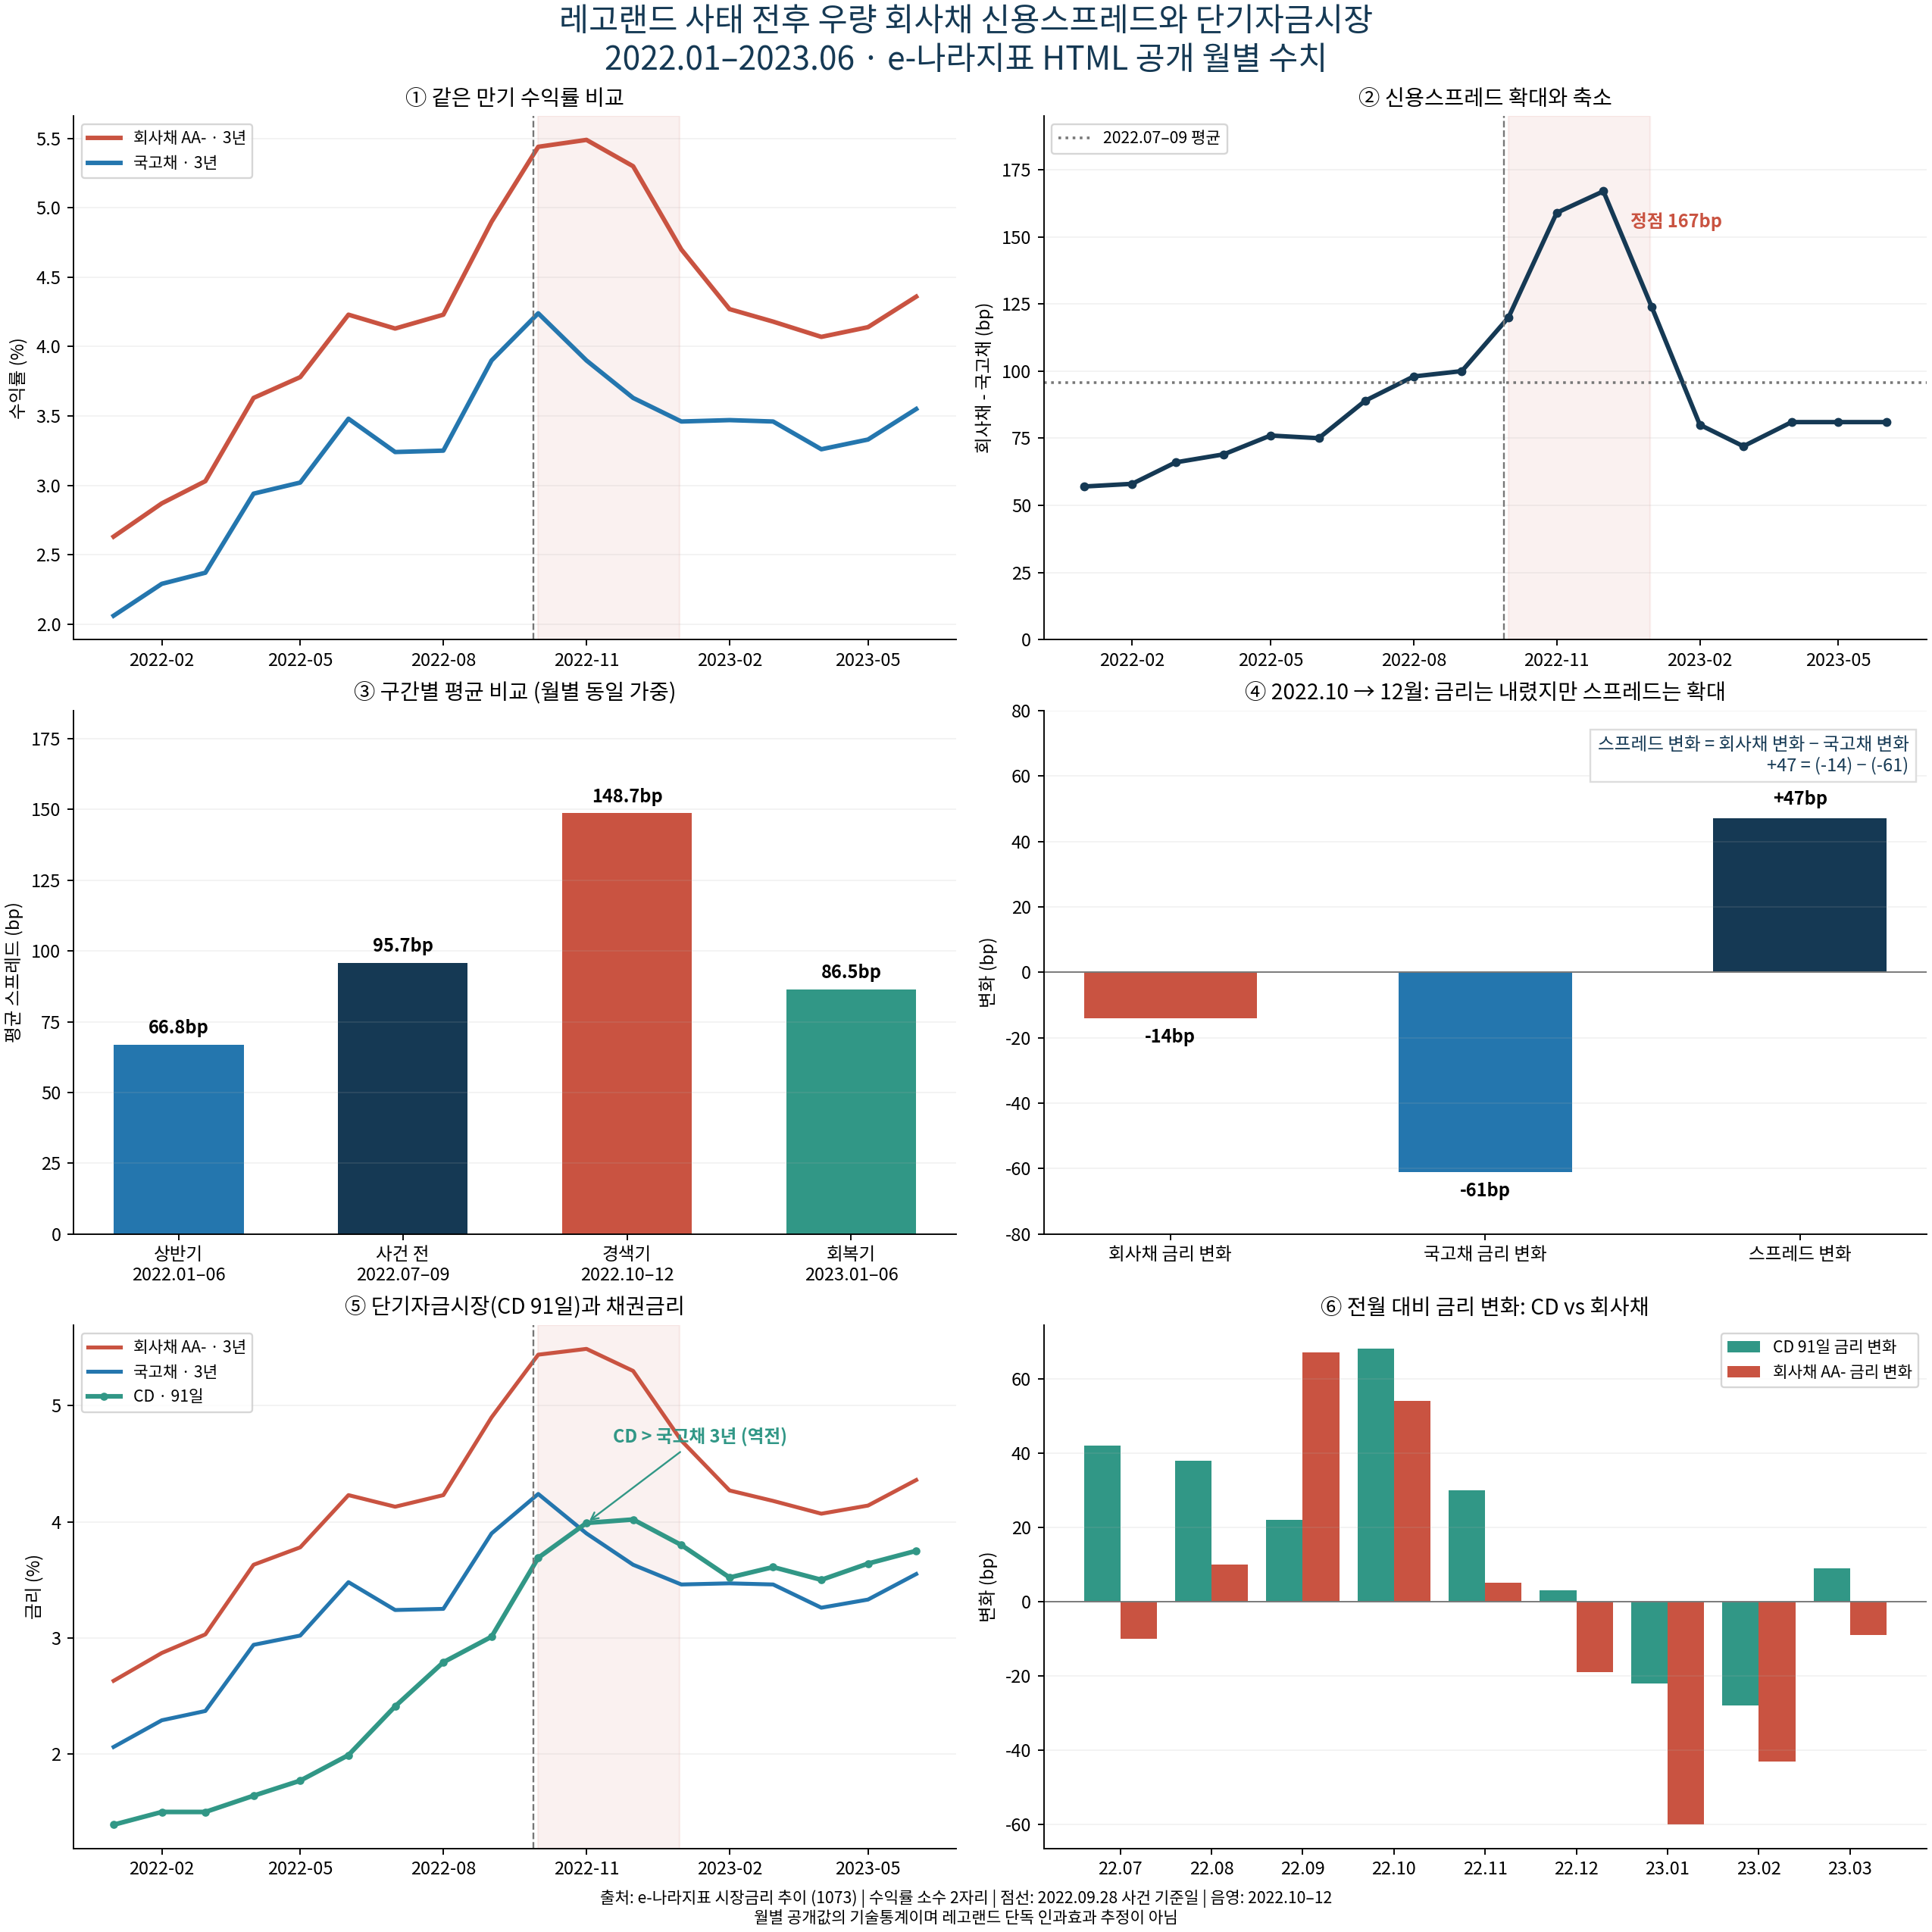

▼ 5년 추이와 계기판 구간(코로나 비교), 매수 시점 구간별 6개월 초과수익 근사


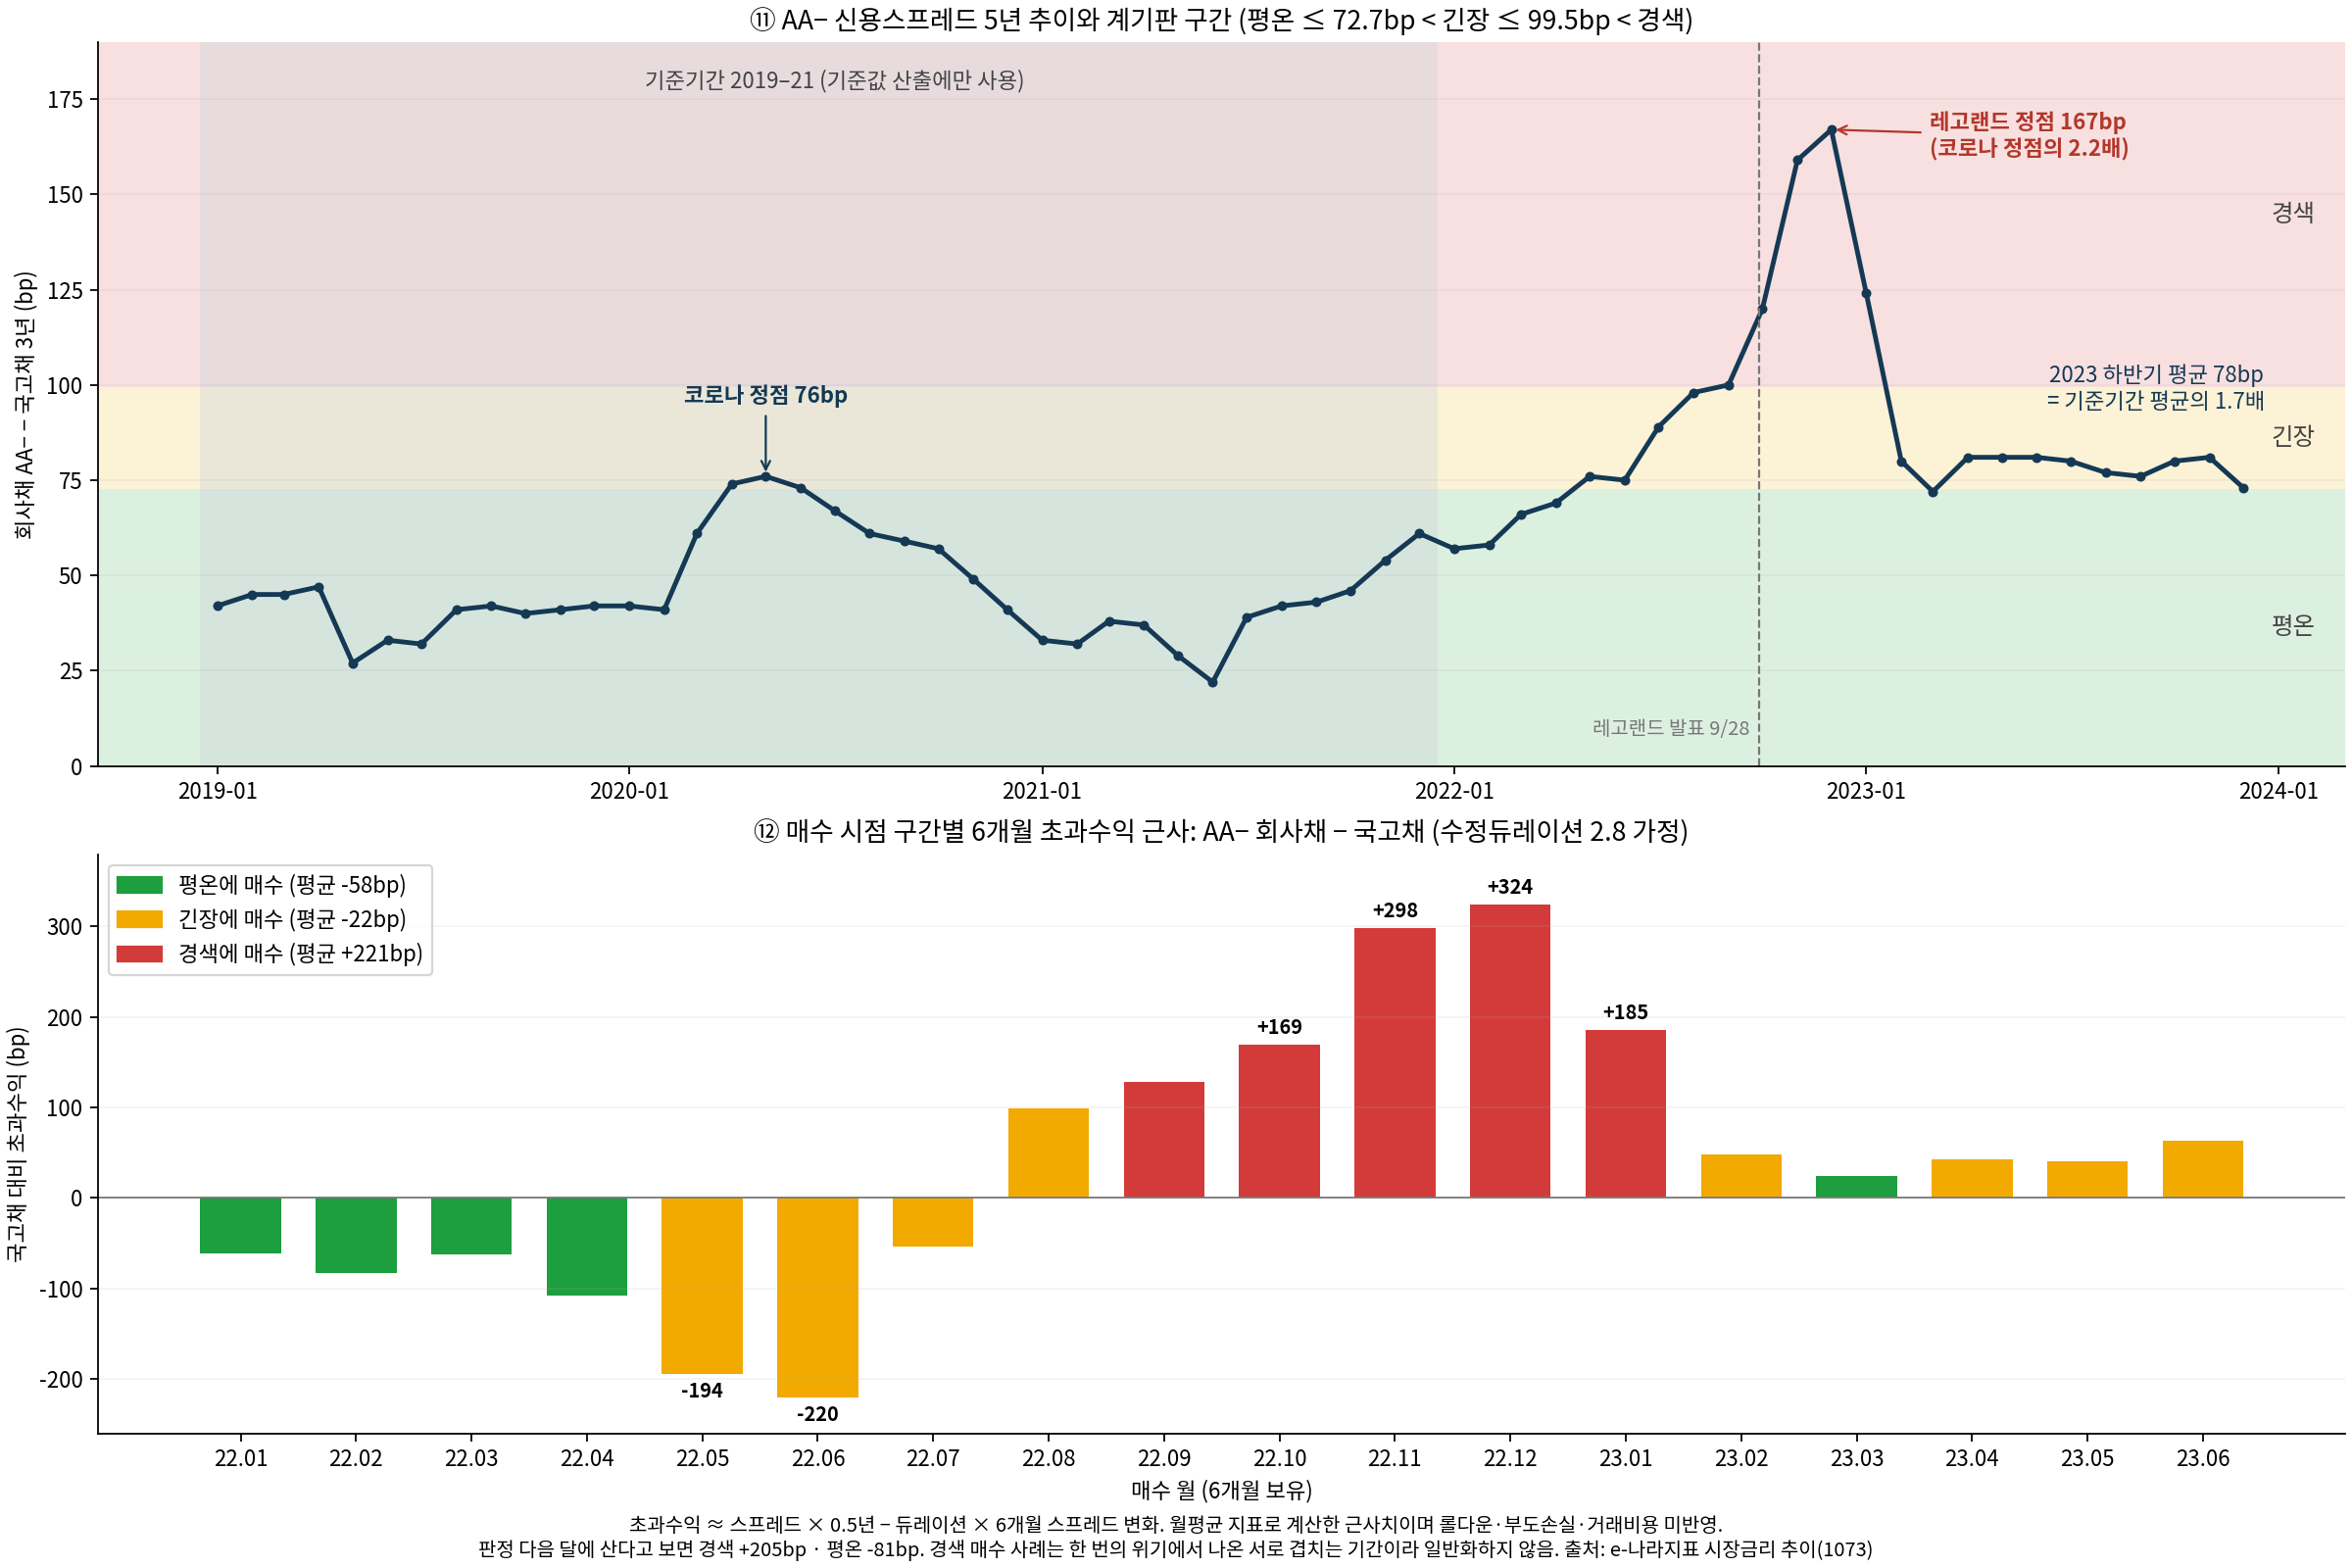

▼ 제안: 스프레드 계기판 — 기준값은 2019–21년(표본 밖) 평균+2σ·+4σ


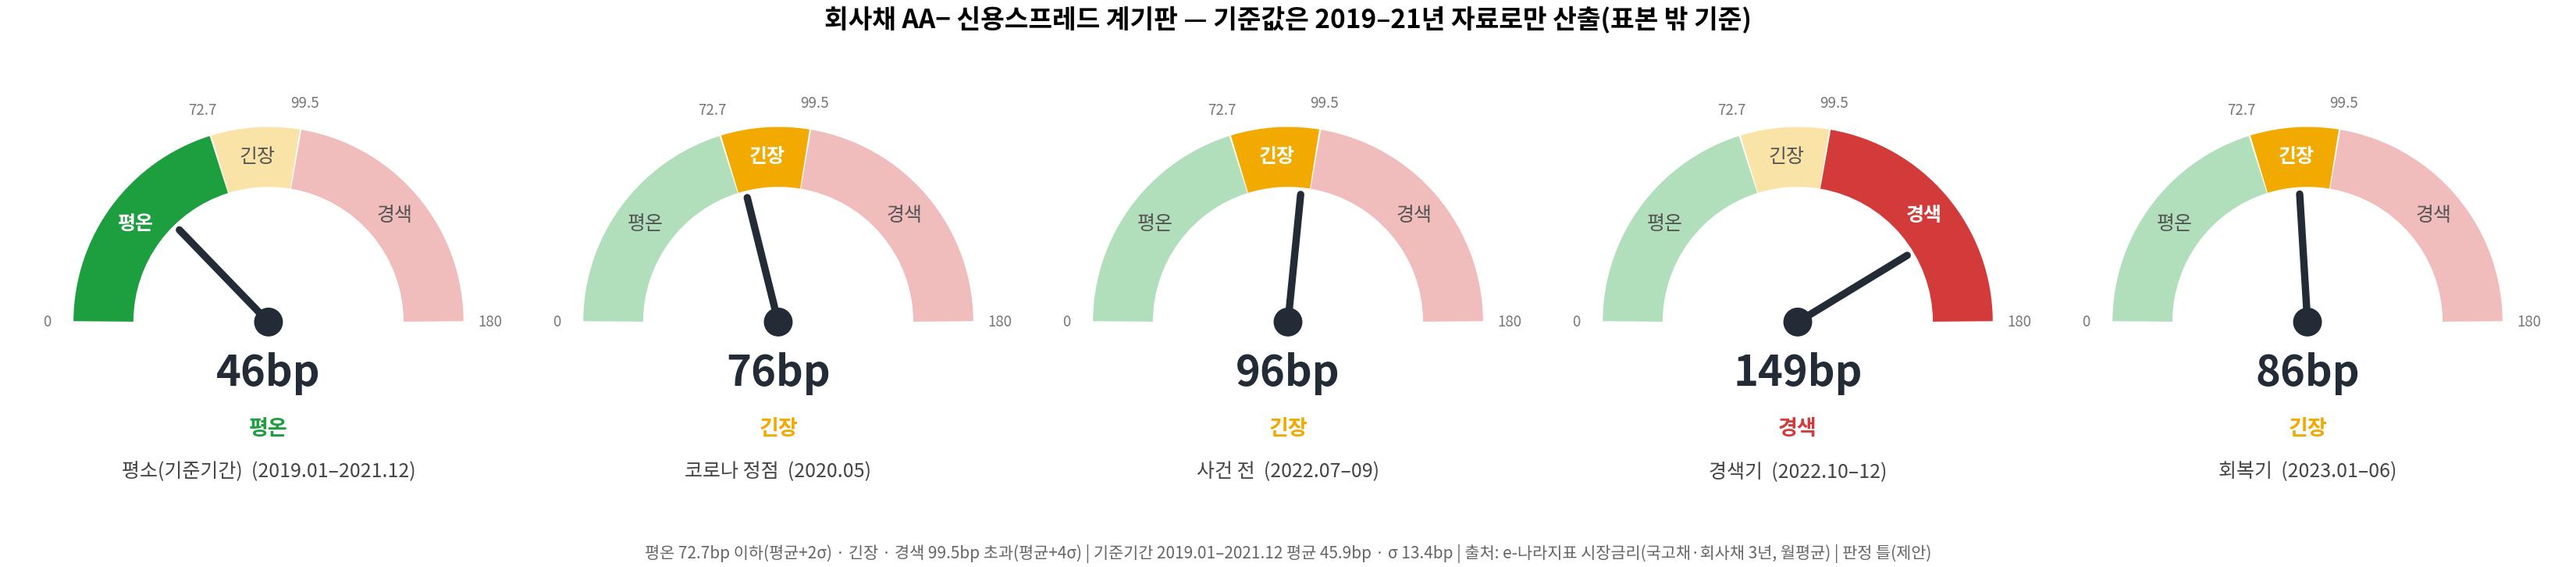

,항목,값,설명
0,기준기간,2019.01–2021.12,36개월. 분석·검증 기간과 겹치지 않는 표본 밖 자료
1,기준기간 평균 / 표준편차,45.9 / 13.4bp,2019–21년 AA− 스프레드
2,평온 상한 (평균 + 2σ),72.7bp,이하 평온. 7-2장 사건 직전 범위와 계산 규칙(평균+2σ)만 같고 기준 기간은 다름
3,경색 하한 (평균 + 4σ),99.5bp,초과 경색. 평온 폭의 두 배 바깥
4,코로나 정점 판정,76bp (2020-05),긴장 (기준기간 안의 값)
5,검증 기간 구간 분포,2022-01~2023-12,평온 5 · 긴장 14 · 경색 5개월
6,경색 구간,2022-09 → 2023-01,5개월 연속
7,평온 복귀,2023-03,경색 시작부터 6개월
8,[일별] 경색 진입 (5영업일 연속),2022-09-27,같은 기준을 ECOS 일별 AA− 스프레드에 적용 — 발표일(09-28) 전에 이미...
9,[일별] 평온 복귀 (5영업일 연속),2023-02-17,진입부터 143일


,stress_k_sigma,stress_threshold_bp,stress_months,stress_first,stress_last,stress_buy_excess_6m_mean_bp,stress_buy_n,stress_buy_next_month_excess_6m_mean_bp
0,3,86.1,7,2022-07,2023-01,164.4,7,179.0
1,4,99.5,5,2022-09,2023-01,221.0,5,205.0
2,5,112.9,4,2022-10,2023-01,244.2,4,214.0


▼ ECOS 일별 확장: 지표별 사건 전 대비 변화, 평소 범위 이탈일·급변일·복귀일


,indicator,name,pre_daily_change_mean_bp,pre_daily_change_std_bp,first_jump_date,first_jump_bp,first_jump_z,pre_mean_bp,pre_std_bp,threshold_bp,stress_mean_bp,change_bp,peak_bp,peak_date,first_breach_date,days_event_to_breach,bizdays_event_to_breach,back_to_normal_date,recovery_mean_bp
0,cp_minus_base_bp,CP − 기준금리,0.3,2.1,2022-10-17,8.0,3.7,60.5,4.5,69.6,185.7,125.2,247.0,2022-11-23,2022-09-28,0,0,2023-02-16,71.8
1,cd_minus_base_bp,CD − 기준금리,0.6,2.3,NaN,NaN,NaN,43.5,8.3,60.1,83.8,40.2,102.0,2022-11-22,2022-09-28,0,0,2023-01-13,15.6
2,spread_aa_bp,회사채 AA− 스프레드,0.3,0.8,2022-09-29,7.1,8.7,95.0,5.2,105.4,148.2,53.2,177.2,2022-12-01,2022-09-29,1,1,2023-01-30,86.3
3,spread_bbb_bp,회사채 BBB− 스프레드,0.3,0.8,2022-09-29,6.5,7.6,680.2,5.4,691.1,733.8,53.6,761.2,2022-12-02,2022-09-29,1,1,NaN,720.0
4,cp_minus_cd_bp,CP − CD,-0.2,1.5,2022-10-21,11.0,7.5,17.0,6.1,29.2,101.9,85.0,159.0,2022-12-01,2022-10-21,23,15,2023-05-24,56.3


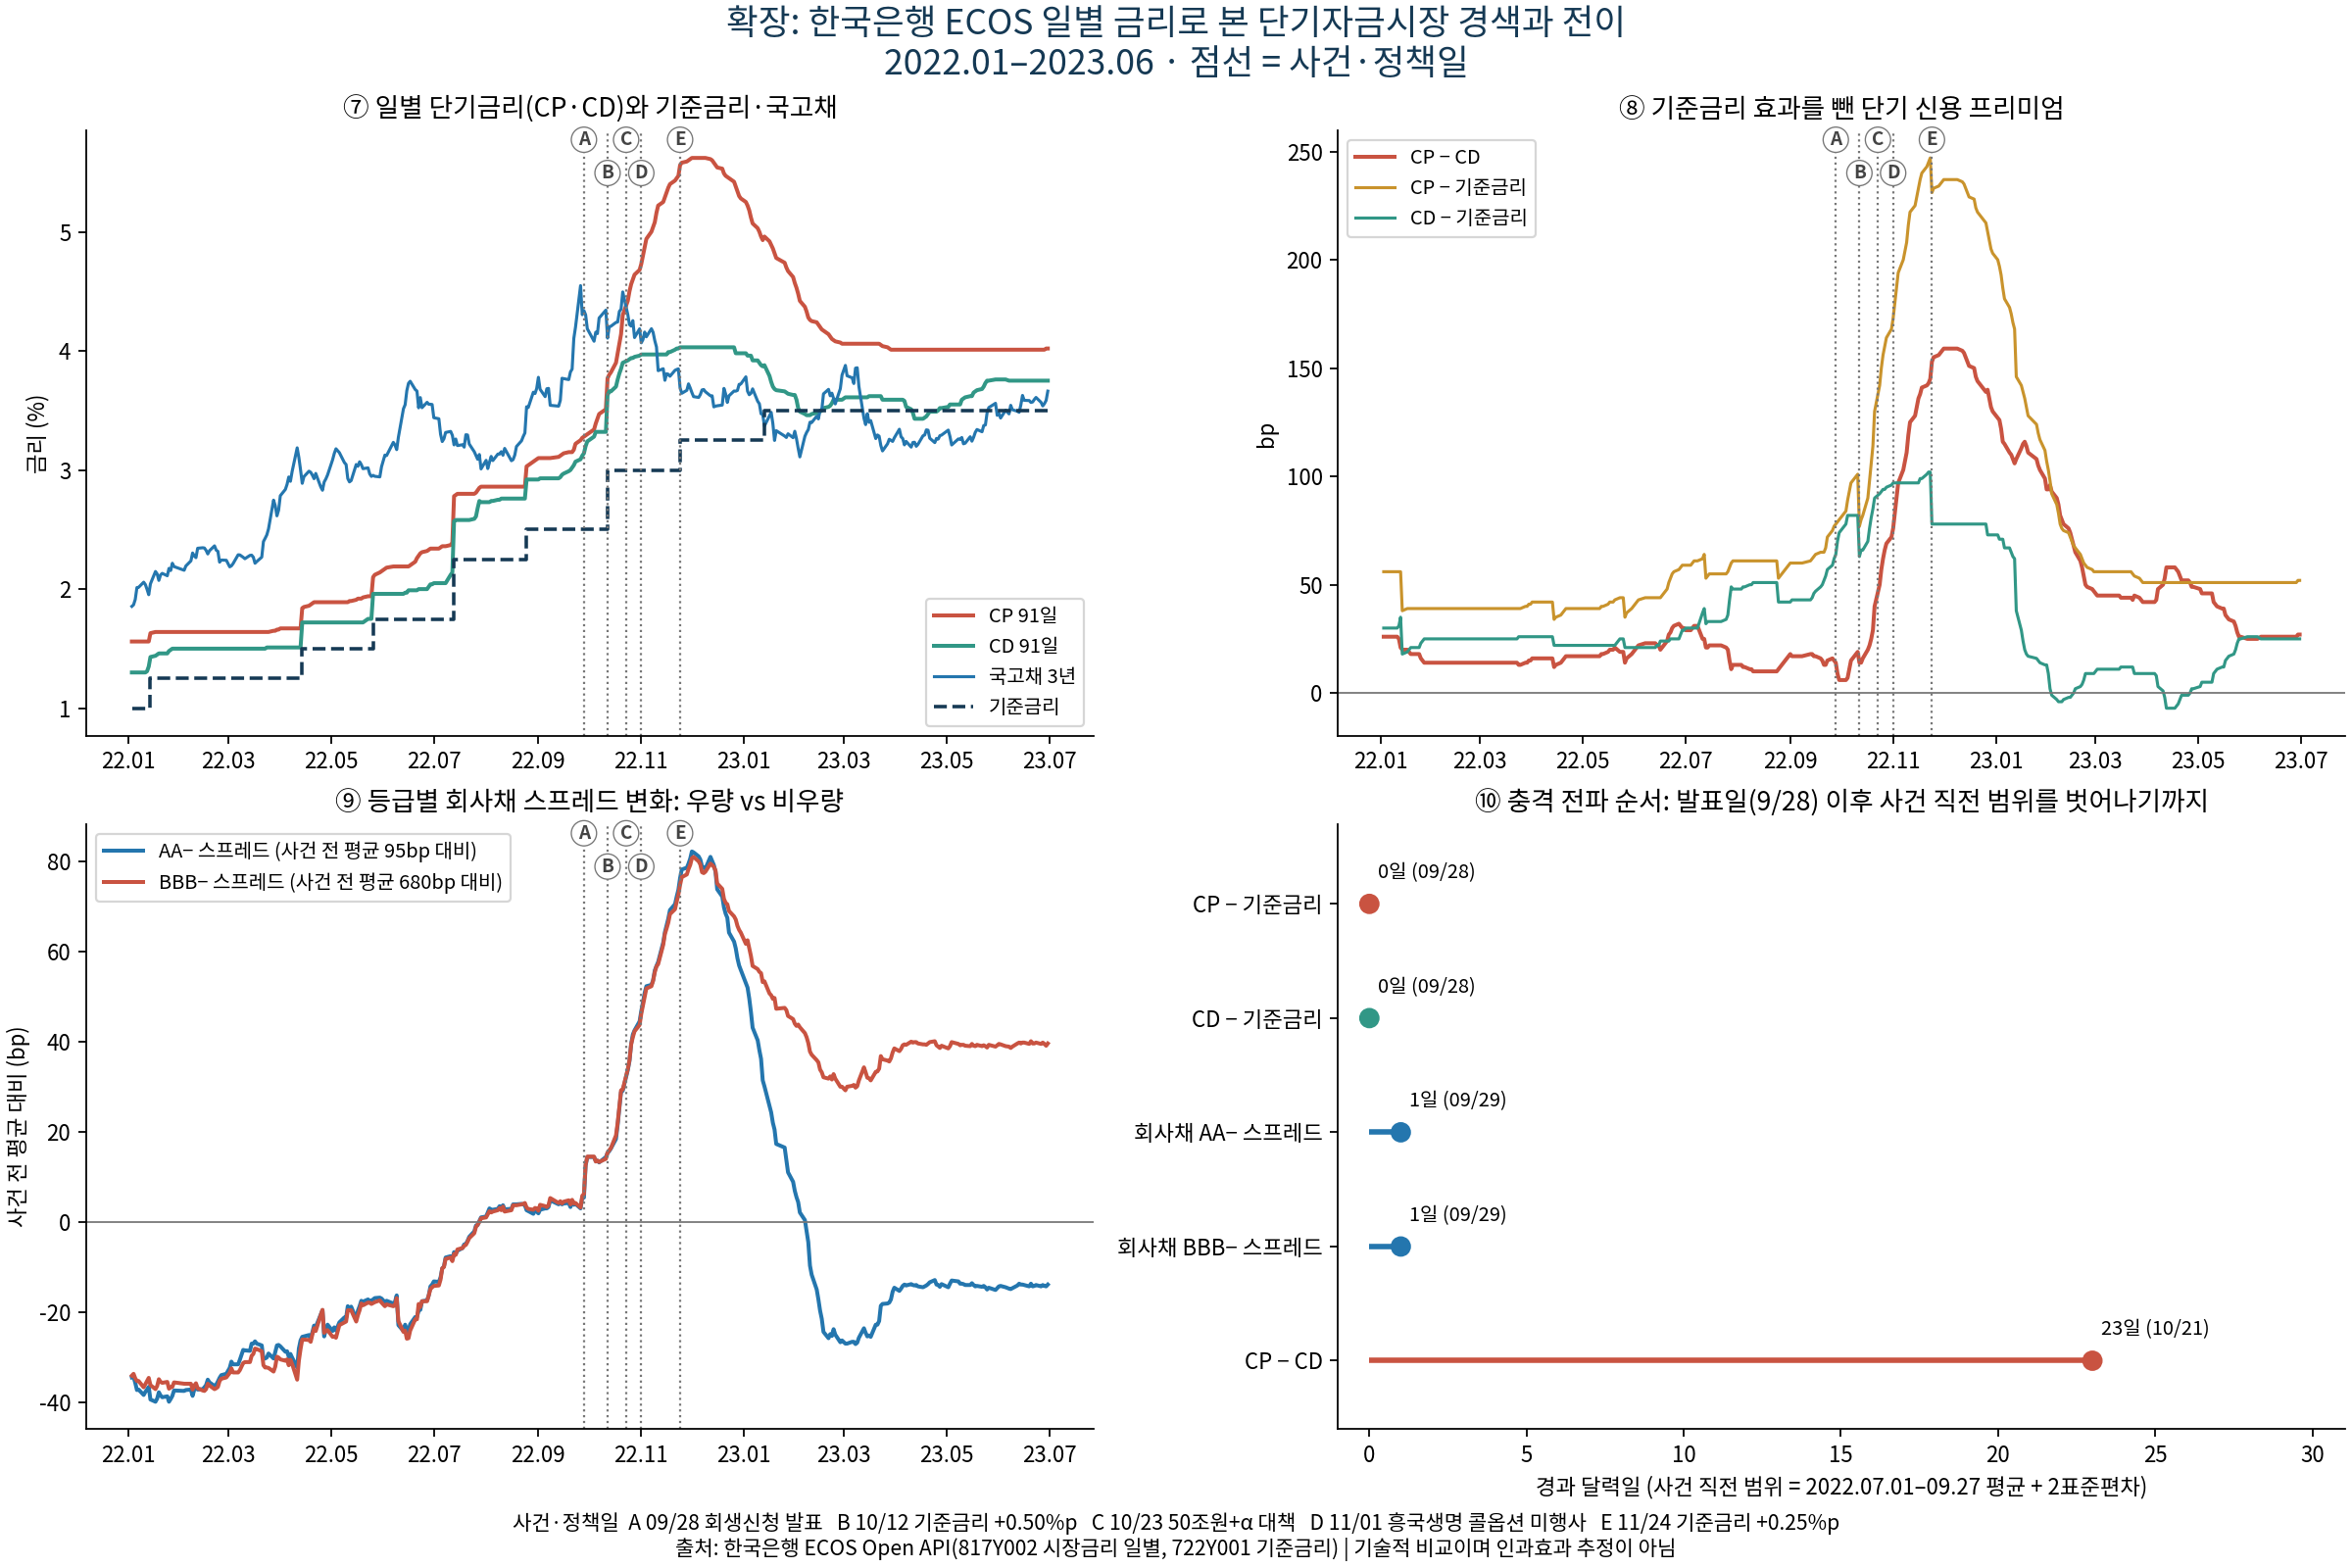

# 레고랜드 사태 전후 우량 회사채 신용스프레드 변화 (v5)

분석 기간 2022.01–2023.06(계기판 검증은 2023.12까지, 장기 비교는 2019.01부터). 월별 수치 수집일(UTC) 2026-09-23. 발표 자료는 presentation 폴더에 별도로 둔다.

## 핵심 결과

AA− 회사채 신용스프레드는 사건 전(2022.07–09) 평균 96bp에서 경색기(2022.10–12) 평균 149bp로 53bp(55%) 커졌고 2022-12에 167bp로 정점을 찍었다. 이는 코로나 충격 때 정점(2020-05, 76bp)의 2.2배다. 같은 기간 회사채 금리 자체는 4.42%에서 5.41%로 99bp(22%) 올랐다. 즉 조달 금리 전체가 1.5배가 된 것이 아니라 그 안의 신용 프리미엄이 1.5배로 커졌다.

2022.10→12월에는 회사채 금리가 14bp 내렸지만 국고채가 61bp로 더 크게 내려 스프레드는 47bp 확대되었다. 단기자금시장(CP − CD)은 회사채보다 3주가량 늦게 벌어졌지만 확대 폭(+85bp)이 더 컸고 회복은 2023-05로 가장 늦었다. 50조원+α 대책 발표 직후 5영업일에도 CP − CD는 오히려 +34bp 더 벌어졌다.

스프레드 계기판의 기준값은 분석 기간과 겹치지 않는 2019–21년 자료로만 정했다(평온 72.7bp 이하 = 평균+2σ, 경색 99.5bp 초과 = 평균+4σ). 이 기준을 2022–23년에 적용하면 경색은 2022-09부터 2023-01까지 5개월이었고 평온 복귀는 2023-03이다. 경색 구간에 AA− 회사채를 사서 6개월 보유했다면 국고채보다 평균 +221bp 더 벌었고(근사, 5회), 평온 구간 매수는 평균 -58bp였다. 판정이 확정되는 다음 달에 산다고 해도 경색 +205bp, 평온 -81bp로 방향은 같다. 한 번의 위기에서 나온 결과라 일반화하지 않으며, 계기판은 투자·조달 판단의 보조지표로 제안한다.

회복기라고 불러도 완전히 돌아온 것은 아니다. 2023년 하반기 평균 스프레드는 78bp로 2019–21년 평균(46bp)의 1.7배에 머물렀다.



## 1. 주제 선정 이유와 분석 질문

주제 선정 이유는 세 가지다. 첫째, 레고랜드 사태는 지자체가 보증한 채무가 흔들리면서 우량 기업의 자금 조달까지 막힌 사건이라 신용 위험이 시장 전체로 번지는 과정을 관찰하기 좋다. 둘째, 국고채·회사채·CD 금리가 공공 웹페이지와 한국은행 공개 API에 있어 수집 과정을 투명하게 재현할 수 있다. 셋째, 신용스프레드는 증권사 WM의 채권 투자 안내와 기업 재무팀의 조달 시점 판단에 바로 쓰이는 지표다.

Q1. 사태 전후 우량 회사채(AA−) 신용스프레드는 얼마나 벌어졌고(평소·코로나 충격과 비교해) 언제 회복되었나? → 6장

Q2. 시장금리가 내려갈 때 신용스프레드도 함께 줄었나? → 6장

Q3. 단기자금시장(CD·CP)은 회사채 시장과 비교해 언제, 얼마나, 얼마나 오래 흔들렸나? → 7장

Q4. 과거(2019–21) 기준으로 스프레드를 평온·긴장·경색으로 나누면 투자·조달 판단의 보조지표로 쓸 수 있나? → 8장

## 2. 데이터와 수집 대상

국고채 3년물과 회사채 3년·AA− 수익률을 같은 월로 맞춰 비교했다. AA−는 이번 프로젝트에서 우량 회사채의 대용지표이며 전체 우량 회사채의 실거래 가중평균이나 AAA 회사채와 같지 않다. 같은 만기로 금리 수준 차이를 줄이고 스프레드에 나타나는 신용·유동성·수급 위험을 관찰한다.

정의: spread_bp = (corp_aa_minus_3y_pct − treasury_3y_pct) × 100. 금리는 4.90 같은 % 단위 숫자로 저장한다. 1%p = 100bp다.

대상: [e-나라지표 시장금리 추이](https://www.index.go.kr/unity/potal/main/EachDtlPageDetail.do?idx_cd=1073). 담당은 금융위원회, 자료 출처는 한국은행 금융시장동향, 공표 주기는 매월이다. 실제 수치는 table이 아니라 div.conBody 안의 span.img_box(지표해석) 텍스트에 있고 br 태그가 연도별 행을 나눈다(페이지의 table 3개는 수치를 담고 있지 않다). BeautifulSoup의 select로 해당 span을 찾고 국고채·회사채·CD 제목을 모두 가진 요소가 정확히 1개인지 확인한 뒤 get_text로 텍스트를 꺼낸다. 제목으로 구간을 나누고 정규식으로 ('22.10월) 4.24 같은 토큰을 추출했다. 세 시계열에서 180개 관측을 수집했고 결합 결과는 60개월(2019-01~2023-12)이다.

e-나라지표 월별 값은 월평균이다. ECOS 일별 값으로 같은 18개월을 계산해 비교하면 월평균과의 차이는 최대 0.01%p(반올림 수준)인 반면 월말값과의 차이는 최대 0.44%p다(check_monthly_basis). 월평균은 한 달 안의 급등락을 평평하게 만들므로 월별 정점(167bp)은 일별 정점보다 낮게, 사건 반응은 한 달 늦게 보일 수 있다. 그래서 날짜 단위 판단(이탈일·급변일·복귀일)은 일별 ECOS 자료로 했다.

## 3. 수집 허용 근거와 요청 방식

원본 수집 이후 별도 점검으로 https://www.index.go.kr/robots.txt 를 확인해 대상 페이지에 대한 허용 여부를 판정했다. 결과: 판단 보류(robots.txt 없음) (HTTP 404, 확인 2026-09-27T04:57:38 UTC, 방법: 외부 웹 조회 도구로 robots.txt 요청(분석 환경의 네트워크 프록시가 index.go.kr 직접 접속을 막아 check_robots() 대신 사용). 인터넷이 되는 PC에서 --offline --check-robots를 실행하면 코드 판정으로 덮어씀). robots.txt가 없다는 것은 수집 금지 표시가 없다는 뜻일 뿐 허용을 뜻하지 않으므로 아래 요청 원칙을 지켰다.

이용 조건: 저장 원본 HTML 전체에서 '공공누리·저작권·이용약관·KOGL' 문구를 코드로 검색한 결과 표시를 찾지 못했다. 이용 조건이 명시되지 않았으므로 출처를 표시하고 비상업 교육 목적으로만 사용한다.

요청 방식: 대상 페이지는 한 번만 요청하고 User-Agent에 교육용 단일 요청임을 밝혔다. 받은 원문 바이트와 SHA256, HTTP 상태, 수집 시각, 패키지 버전을 저장하고 이후 분석은 --offline으로 저장 원본을 재사용해 같은 사이트에 반복 요청하지 않는다. 연결·응답 timeout, raise_for_status(), Content-Type 검사를 적용했고 구조가 바뀌거나 월이 누락되면 임의 값을 넣지 않고 멈춘다. ECOS는 한국은행이 발급한 인증키로 호출하는 공식 Open API이며 지표 6개를 0.5초 간격으로 한 번씩 요청한다. 인증키는 코드·파일·오류 메시지 어디에도 남기지 않는다.

공개 페이지라는 사실만으로 이용이 허용된다고 보지 않는다. 결과물에는 출처를 표시했고 수치는 교육 목적 분석에만 사용한다.

## 4. 정리·전처리 및 품질

pandas로 2자리 연도를 20YY로 바꾸고 월을 datetime(월초 대표 날짜)으로 파싱했다. 월초 날짜는 관측일이 아니라 해당 월의 식별자다. 원자료 CSV(extracted_raw.csv)의 raw_date는 '19.01'처럼 두 자리 월로 저장해 다시 읽어도 1월과 10월이 섞이지 않게 했다. 수익률을 숫자로 바꾸고 날짜·지표 중복을 검사한 뒤 pivot으로 월별 결합하고 스프레드를 계산했다. 숫자 변환 실패·중복·결측·누락 월(수집 전체 2019-01~2023-12과 분석기간 모두)은 오류로 처리한다. 확인 결과 중복 0개, 결측 0개, 누락 월 0개였다.

보간·전방채움·극단값 제거는 하지 않았다. 위기의 급등 자체가 분석 대상이기 때문이다. spread_change_bp 첫 행은 직전 월이 분석 표본에 없어 비워 둔 의도된 결측이다. 원문 수익률이 소수 둘째 자리라 개별 스프레드에는 약 1bp의 반올림 불확실성이 있다. ECOS 일별 자료는 기준금리만 다음 변경 전까지 같은 값을 이어 붙였고 시장금리는 대체하지 않았다.

## 5. 구간 정의 (월별·일별)

월별 자료는 달 단위라 9월 전체를 사건 전에 넣었고 일별 자료는 발표일(2022.09.28)을 경계로 나눴다. 두 자료의 구간 평균은 경계가 다르므로 수치가 조금 다를 수 있다. 9월 포함 여부의 영향은 6장 민감도 표에서 따로 확인했다. 계기판 기준값을 정한 기준기간과 계기판을 적용한 검증기간은 겹치지 않는다.

주의: '사건 전(2022.07–09)'은 평상시가 아니다. 이 시기 AA− 스프레드(월평균 89~100bp)는 2019–21년 기준으로 이미 긴장 구간(9월은 경색)이었다. 급격한 금리 인상으로 시장이 먼저 흔들리고 있었기 때문이다. 따라서 이 보고서의 '사건 전 대비' 수치는 사건 직전과의 비교이고, 평상시와의 비교는 2019–21년 평균(45.9bp)을 기준으로 6장 장기 비교와 8장 계기판에서 따로 했다.

| 구간 | 코드 | 월별 자료(e-나라지표) | 일별 자료(ECOS) | 비고 |
|---|---|---|---|---|
| 기준기간(평소) | - | 2019.01–2021.12 (36개월) | - | 계기판 기준값 산출·장기 비교에만 사용 |
| 2022 상반기 | 2022_H1 | 2022.01–06 (6개월) | 2022.01.01–06.30 |  |
| 사건 전 | pre | 2022.07–09 (3개월, 9월 전체 포함) | 2022.07.01–09.27 | 평상시 아님 — 계기판 기준 긴장(9월 경색) |
| 경색기 | stress | 2022.10–12 (3개월) | 2022.09.28–12.31 (발표일부터) |  |
| 회복기 | recovery | 2023.01–06 (6개월) | 2023.01.01–06.30 |  |
| 계기판 검증기간 | - | 2022.01–2023.12 (24개월) | 2022.01–2023.06 | 기준기간과 겹치지 않음 |

## 6. 분석 결과 — Q1·Q2

| period | months | mean_bp | median_bp | min_bp | max_bp | std_bp |
|---|---|---|---|---|---|---|
| 2022_H1 | 6 | 66.83 | 67.50 | 57.00 | 76.00 | 8.13 |
| pre | 3 | 95.67 | 98.00 | 89.00 | 100.00 | 5.86 |
| stress | 3 | 148.67 | 159.00 | 120.00 | 167.00 | 25.15 |
| recovery | 6 | 86.50 | 81.00 | 72.00 | 124.00 | 18.71 |

std_bp는 구간 안 월별 스프레드 수준의 표본 표준편차이며 투자위험 추정치가 아니다.

Q1 답: 스프레드는 사건 전 96bp에서 경색기 149bp로 53bp 커졌고 2022-12 167bp로 정점을 찍었다. 정점 이후 처음 사건 전 평균 이하로 내려온 달은 2023-02다. 이 확대 폭은 회사채 금리 전체 상승(99bp)의 절반 이상에 해당한다.

장기 비교: 이미 수집한 2019–21년 36개월의 평균 스프레드는 45.9bp(표준편차 13.4bp)였고 코로나 충격 때도 정점은 2020-05 76bp였다. 레고랜드 정점 167bp는 그 2.2배다. 회복기(2023.01–06) 평균 86bp와 2023년 하반기 평균 78bp는 여전히 2019–21년 평균의 1.9배, 1.7배다. 다만 2023년은 국고채 금리 수준 자체가 2019–21년보다 2%p 안팎 높아 같은 신용위험이라도 bp 스프레드가 커질 수 있으므로 '위기 전 수준으로 완전히 돌아오지 않았다'까지만 해석한다.



Q2 답: 아니다. 2022.10→12월 회사채 수익률은 -14bp, 국고채 수익률은 -61bp 변해 스프레드는 -14 − (-61) = +47bp 커졌다. 시장금리가 내려도 기업이 더 내야 하는 위험 프리미엄은 오히려 늘었다.

| baseline | baseline_mean_bp | stress_mean_bp | change_bp |
|---|---|---|---|
| 2022.07–09 (3개월) | 95.67 | 148.67 | 53.00 |
| 2022.06–08 (9월 제외, 3개월) | 87.33 | 148.67 | 61.33 |
| 2022.01–06 (6개월) | 66.83 | 148.67 | 81.83 |

기준기간을 바꾸어도 확대 방향은 같다. 다만 사건 전부터 상승 추세가 있었고 구간마다 금리·수급 환경이 달라 확대 폭 전체를 레고랜드의 효과로 해석하지 않는다. 표본이 작고 시계열 자기상관이 있어 통계적 유의성은 주장하지 않았다.

## 7. 분석 결과 — Q3 단기자금시장

Q3 답: 단기자금시장은 회사채보다 늦게 벌어졌지만 더 크게, 더 오래 흔들렸다. AA− 스프레드는 발표 1일(1영업일) 뒤(2022-09-29) 사건 직전 범위를 벗어났고 CP − CD는 23일(15영업일) 뒤(2022-10-21) 벗어났다. 대신 CP − CD는 사건 전 대비 +85bp 확대되어 AA− 스프레드(+53bp)보다 폭이 컸고 정점 159bp를 찍은 뒤 2023-05-24에야 사건 직전 범위로 돌아왔다(5영업일 연속 기준, AA− 복귀 2023-01-30). CP 91일 금리는 2022-09-22부터 2022-12-01까지 49영업일 연속 상승했다.

추세 점검: 사건 전(2022.07–09) AA− 스프레드는 하루 평균 +0.32bp(표준편차 0.78bp)씩 오르는 추세였다. 그런데 발표 다음 날인 2022-09-29에는 하루에 +7.1bp가 올랐다. 사건 전 일간 변화 분포에서 9표준편차 떨어진 값이고, 기존 추세 속도라면 약 22영업일이 걸릴 폭이다. 따라서 9월 29일의 이탈은 이미 있던 상승 추세만으로는 설명되지 않는 급변이다. CP − CD의 첫 급변일은 2022-10-21(+11bp)로 수준 기준 이탈일과 같다.

발표 당일 먼저 벗어난 CP·CD − 기준금리는 10.12 기준금리 인상 기대가 섞인 지표라서 '단기자금시장이 먼저 흔들렸다'는 근거로 쓰지 않는다. 기준금리 인상이 예상되면 은행(CD)과 기업(CP)의 91일 금리가 함께 미리 오르므로 두 금리의 차이(CP − CD)를 봐야 신용 불안만 남는다.

## 7-1. 월별 CD(91일)

같은 지표해석 본문의 세 번째 시계열인 CD(91일) 금리를 같은 정규식으로 추출했다. CD는 기준금리를 가장 직접적으로 따라가므로 CD 상승분 전체를 신용경색으로 볼 수 없다.

2022.09→10월 CD는 +68bp, 회사채 AA− 금리는 +54bp 변했다. CD − 국고채 3년 차이는 2022.09 -89bp에서 2022.12 +39bp가 되었고 CD가 처음 국고채 3년을 웃돈 달은 2022-11다. 단기 조달금리가 3년 국채보다 높아진 역전은 연말 단기자금 경색과 부합한다.

| date | cd_91d_pct | treasury_3y_pct | corp_aa_minus_3y_pct | spread_bp | cd_change_bp | corp_change_bp | treasury_change_bp | spread_change_bp | cd_minus_treasury_bp |
|---|---|---|---|---|---|---|---|---|---|
| 2022-07 | 2.41 | 3.24 | 4.13 | 89.00 | 42.00 | -10.00 | -24.00 | 14.00 | -83.00 |
| 2022-08 | 2.79 | 3.25 | 4.23 | 98.00 | 38.00 | 10.00 | 1.00 | 9.00 | -46.00 |
| 2022-09 | 3.01 | 3.90 | 4.90 | 100.00 | 22.00 | 67.00 | 65.00 | 2.00 | -89.00 |
| 2022-10 | 3.69 | 4.24 | 5.44 | 120.00 | 68.00 | 54.00 | 34.00 | 20.00 | -55.00 |
| 2022-11 | 3.99 | 3.90 | 5.49 | 159.00 | 30.00 | 5.00 | -34.00 | 39.00 | 9.00 |
| 2022-12 | 4.02 | 3.63 | 5.30 | 167.00 | 3.00 | -19.00 | -27.00 | 8.00 | 39.00 |
| 2023-01 | 3.80 | 3.46 | 4.70 | 124.00 | -22.00 | -60.00 | -17.00 | -43.00 | 34.00 |
| 2023-02 | 3.52 | 3.47 | 4.27 | 80.00 | -28.00 | -43.00 | 1.00 | -44.00 | 5.00 |
| 2023-03 | 3.61 | 3.46 | 4.18 | 72.00 | 9.00 | -9.00 | -1.00 | -8.00 | 15.00 |

선후행 점검: 전체 수집기간 59개월의 전월 대비 변화로 corr(CD 변화_t, 회사채 변화_t+k)를 계산했다(k>0이면 CD가 먼저 움직인 관계). 회사채 금리 변화와는 k=-1(r=0.58), 스프레드 변화와는 k=0(r=0.46)에서 상관이 가장 컸다. 월별 자료로는 CD가 회사채를 앞섰다고 볼 수 없으며 공통 요인(기준금리 인상)이 섞인 방향성 점검으로만 해석한다.

| lag_months_k | meaning | corr_cd_vs_corp_yield_change | corr_cd_vs_spread_change | n_pairs |
|---|---|---|---|---|
| -2 | CD가 2개월 후행 | 0.37 | 0.05 | 57 |
| -1 | CD가 1개월 후행 | 0.58 | 0.22 | 58 |
| 0 | 동월 | 0.52 | 0.46 | 59 |
| 1 | CD가 1개월 선행 | 0.33 | 0.45 | 58 |
| 2 | CD가 2개월 선행 | 0.16 | 0.08 | 57 |

## 7-2. ECOS 일별 금리로 본 전이 경로

한국은행 ECOS Open API(시장금리 일별 817Y002, 기준금리 722Y001)에서 20220101–20230630 일별 CP·CD(91일), 국고채·회사채 AA−/BBB−(3년), 기준금리를 받았다(수집 2026-09-23). 기준금리를 빼면 금리 인상 효과를 걷어낸 '단기 신용 프리미엄'을, CP − CD를 빼면 은행(CD)보다 기업(CP)이 얼마나 더 비싸게 돈을 빌렸는지를 볼 수 있다.



CP 91일 금리는 사건 전(2022.07.01–09.27) 평균 2.88%에서 2022-12-01 5.62%로 정점을 찍었다. 5%를 처음 넘은 날은 2022-11-07, 다시 5% 아래로 내려온 날은 2023-01-11이다. 발표일(2022.09.28) 이후 '사건 직전 범위(2022.07.01–09.27 평균 + 2표준편차)'를 벗어난 순서는 CP − 기준금리(09-28) → CD − 기준금리(09-28) → 회사채 AA− 스프레드(09-29) → 회사채 BBB− 스프레드(09-29) → CP − CD(10-21)이다. 등급별로는 사건 전 대비 경색기 평균 스프레드가 AA− +53bp, BBB− +54bp 변했다. 복귀일은 5영업일 연속 사건 직전 범위 안에 머문 첫날이다. 이 범위는 계기판(2019–21년 기준)의 '평온'과 다르다. 사건 직전 기간이 이미 계기판 기준으로 긴장·경색 경계에 있었으므로, '복귀'는 평소 수준 회복이 아니라 사건 직전 수준으로 돌아왔다는 뜻이다.

| name | pre_mean_bp | stress_mean_bp | change_bp | peak_bp | peak_date | first_breach_date | days_event_to_breach | first_jump_date | first_jump_z | back_to_normal_date |
|---|---|---|---|---|---|---|---|---|---|---|
| CP − 기준금리 | 60.47 | 185.68 | 125.22 | 247.00 | 2022-11-23 | 2022-09-28 | 0 | 2022-10-17 | 3.68 | 2023-02-16 |
| CD − 기준금리 | 43.52 | 83.76 | 40.24 | 102.00 | 2022-11-22 | 2022-09-28 | 0 | - | - | 2023-01-13 |
| 회사채 AA− 스프레드 | 95.00 | 148.22 | 53.22 | 177.20 | 2022-12-01 | 2022-09-29 | 1 | 2022-09-29 | 8.67 | 2023-01-30 |
| 회사채 BBB− 스프레드 | 680.21 | 733.79 | 53.58 | 761.20 | 2022-12-02 | 2022-09-29 | 1 | 2022-09-29 | 7.64 | 미복귀 |
| CP − CD | 16.95 | 101.92 | 84.97 | 159.00 | 2022-12-01 | 2022-10-21 | 23 | 2022-10-21 | 7.54 | 2023-05-24 |

사건·정책일 전후 5영업일 평균 비교(CP − CD, AA− 스프레드):

| event_date | event | indicator | before_5d_mean | after_5d_mean | change |
|---|---|---|---|---|---|
| 2022-09-28 | 회생신청 발표 | CP − CD | 14.40 | 8.40 | -6.00 |
| 2022-09-28 | 회생신청 발표 | 회사채 AA− 스프레드 | 99.16 | 107.04 | 7.88 |
| 2022-10-12 | 기준금리 +0.50%p | CP − CD | 11.60 | 17.20 | 5.60 |
| 2022-10-12 | 기준금리 +0.50%p | 회사채 AA− 스프레드 | 108.82 | 112.46 | 3.64 |
| 2022-10-23 | 50조원+α 대책 | CP − CD | 27.20 | 60.80 | 33.60 |
| 2022-10-23 | 50조원+α 대책 | 회사채 AA− 스프레드 | 119.62 | 133.60 | 13.98 |
| 2022-11-01 | 흥국생명 콜옵션 미행사 | CP − CD | 65.20 | 89.80 | 24.60 |
| 2022-11-01 | 흥국생명 콜옵션 미행사 | 회사채 AA− 스프레드 | 135.76 | 145.26 | 9.50 |
| 2022-11-24 | 기준금리 +0.25%p | CP − CD | 141.80 | 155.80 | 14.00 |
| 2022-11-24 | 기준금리 +0.25%p | 회사채 AA− 스프레드 | 165.58 | 173.64 | 8.06 |

읽는 법: 발표 직후 5영업일 동안 AA− 스프레드는 +7.9bp 올랐지만 CP − CD는 -6.0bp로 오히려 조용했다. 단기 시장의 불안은 50조원+α 대책 발표(10.23) 뒤에 본격화해 직후 5영업일 동안 CP − CD가 +33.6bp 벌어졌고, 흥국생명 콜옵션 미행사 발표(11.1) 뒤에도 +24.6bp 변했다. 대책 발표가 곧바로 단기 조달 시장을 진정시키지 못했다는 뜻이다.

해석 주의: 이탈일 순서는 각 지표가 사건 직전 범위를 언제 벗어났는지 보여주는 기술적 지표이며 인과관계를 증명하지 않는다. CP·CD − 기준금리는 금리 인상 기대가 섞여 있어 신용 불안만 보려면 CP − CD를 본다. 기준 구간(2022.07–09) 변동성이 작은 지표는 작은 변화에도 이탈로 잡힐 수 있어 일간 변화 기준(first_jump)으로도 확인했다. 여러 사건이 몇 주 안에 겹쳐 있어 개별 효과를 분리하지 않았다.

## 8. 제안 — 스프레드 계기판 (Q4)

기준값 산출: 2019–21년 36개월 AA− 스프레드의 평균(45.9bp)과 표준편차(13.4bp)로 평온 상한 = 평균 + 2σ = 72.7bp, 경색 하한 = 평균 + 4σ = 99.5bp로 정했다. 2σ는 7-2장 일별 분석의 '사건 직전 범위'와 계산 규칙만 같다. 사건 직전 범위는 2022.07.01–09.27을, 계기판은 2019–21년을 기준으로 삼으므로 같은 날의 스프레드가 두 기준에서 다르게 판정될 수 있다(예: 사건 직전 평균 95bp는 계기판 기준으로 '긴장'). 4σ는 평온 폭의 두 배 바깥이다. 기준값을 정한 기간(2019–21)과 적용·검증한 기간(2022.01–2023.12)이 겹치지 않으므로 v1의 '같은 18개월로 기준을 정하고 검증했다'는 순환 문제를 없앴다. 이 기준으로 코로나 정점(76bp)은 '긴장'으로 판정된다.



| 항목 | 값 | 설명 |
|---|---|---|
| 기준기간 | 2019.01–2021.12 | 36개월. 분석·검증 기간과 겹치지 않는 표본 밖 자료 |
| 기준기간 평균 / 표준편차 | 45.9 / 13.4bp | 2019–21년 AA− 스프레드 |
| 평온 상한 (평균 + 2σ) | 72.7bp | 이하 평온. 7-2장 사건 직전 범위와 계산 규칙(평균+2σ)만 같고 기준 기간은 다름 |
| 경색 하한 (평균 + 4σ) | 99.5bp | 초과 경색. 평온 폭의 두 배 바깥 |
| 코로나 정점 판정 | 76bp (2020-05) | 긴장 (기준기간 안의 값) |
| 검증 기간 구간 분포 | 2022-01~2023-12 | 평온 5 · 긴장 14 · 경색 5개월 |
| 경색 구간 | 2022-09 → 2023-01 | 5개월 연속 |
| 평온 복귀 | 2023-03 | 경색 시작부터 6개월 |
| [일별] 경색 진입 (5영업일 연속) | 2022-09-27 | 같은 기준을 ECOS 일별 AA− 스프레드에 적용 — 발표일(09-28) 전에 이미 진입: 계기판은 원인을 구분하지 못하는 수준 지표 |
| [일별] 평온 복귀 (5영업일 연속) | 2023-02-17 | 진입부터 143일 |
| 6개월 초과수익 근사: 평온에 매수 | 평균 -58.0bp | 5회, 범위 -108.3~+24.8bp (국고채 대비) |
| 6개월 초과수익 근사: 긴장에 매수 | 평균 -21.7bp | 8회, 범위 -220.1~+99.4bp (국고채 대비) |
| 6개월 초과수익 근사: 경색에 매수 | 평균 +221.0bp | 5회, 범위 +128.4~+324.3bp (국고채 대비) |
| [판정 다음 달 매수] 평온 | 평균 -80.9bp | 5회. 월평균 판정이 월말에 확정되는 점을 반영한 민감도 |
| [판정 다음 달 매수] 긴장 | 평균 +11.8bp | 7회. 월평균 판정이 월말에 확정되는 점을 반영한 민감도 |
| [판정 다음 달 매수] 경색 | 평균 +205.0bp | 5회. 월평균 판정이 월말에 확정되는 점을 반영한 민감도 |

σ 배수 민감도: 경색 하한을 평균+3σ·4σ·5σ로 바꿔도 경색 시기는 2022년 하반기~2023년 1월로 유지되고, 경색 구간 매수의 6개월 초과수익은 모두 양(+)이다.

| 경색 기준(σ 배수) | 경색 하한 bp | 경색 개월 수 | 첫 경색 월 | 마지막 경색 월 | 경색 매수 6개월 초과수익 평균 bp | 매수 횟수 | 판정 다음 달 매수 시 평균 bp |
|---|---|---|---|---|---|---|---|
| 3 | 86.10 | 7 | 2022-07 | 2023-01 | 164.41 | 7 | 178.97 |
| 4 | 99.48 | 5 | 2022-09 | 2023-01 | 221.00 | 5 | 205.00 |
| 5 | 112.87 | 4 | 2022-10 | 2023-01 | 244.15 | 4 | 213.95 |

투자 관점 점검(6개월 초과수익 근사): 매월 AA− 회사채를 사서 6개월 보유했을 때 국고채 대비 초과수익을 '스프레드 × 0.5년 − 수정듀레이션(2.8) × 6개월 스프레드 변화'로 근사했다. 매수 시점 구간별 평균은 경색 +221bp(5회), 긴장 -22bp(8회), 평온 -58bp(5회)였다. 스프레드가 가장 높을 때 사면 이후 스프레드 축소로 가격 이익까지 얻었기 때문이다. 월평균 지수로 계산한 근사치이며 롤다운·볼록성·부도손실·거래비용을 넣지 않았고, 경색 매수 사례는 한 번의 위기에서 나온 서로 겹치는 6개월 구간이다.

미래 정보 점검(v4): 그 달의 월평균 스프레드는 월말에야 확정되므로 같은 달 월평균 값에 샀다고 보는 계산은 판정보다 먼저 사는 셈이다. 판정 다음 달에 산다고 다시 계산하면 경색 +205bp(5회), 긴장 +12bp(7회), 평온 -81bp(5회)로 경색 매수가 가장 높다는 결론은 유지된다(output/gauge_zones_monthly.csv의 excess_next_6m_bp).

Q4 답: 사후 판정 틀로는 쓸 수 있다, 다만 '보조지표'로만. 표본 밖 기준으로도 경색 판정은 레고랜드 전후(2022-09~2023-01)에 모였고 평온 복귀 시점은 2023-03이다. 같은 기준을 ECOS 일별 AA− 스프레드에 5영업일 연속 규칙으로 적용하면 경색 진입 2022-09-27, 평온 복귀 2023-02-17(143일)이다. 일별 경색 진입일은 발표일(2022-09-28) 전이다. 경색 판정 구간의 매수는 사후적으로 국고채보다 높은 초과수익을 냈다. 그러나 경색 판정이 9월(발표 전)에 먼저 켜진 것은 당시 금리 급등 등 다른 요인도 스프레드를 밀어 올렸다는 뜻이므로 계기판은 원인을 구분하지 못한다.

사용 절차: 새 AA− 스프레드 값이 들어오면 72.7bp·99.5bp 기준에 대입해 평온·긴장·경색을 판정한다. 경색이면 (1) 발행사 신용등급·전망 변화가 없는지 먼저 확인하고 (2) 문제가 없으면 우량 회사채를 검토 대상에 올리되 한 번의 위기에서 나온 결과임을 감안해 분할·소액으로 접근하며 (3) 기업은 회사채 발행 시점을 재검토하는 보조 판단 근거로 쓴다. 기준값은 금리 수준과 시장 구조가 바뀌면 최근 3년 자료로 다시 계산한다.

## 9. 금융 비즈니스 관점의 인사이트

1. 기업 재무: 관측된 스프레드 확대 폭을 신규·차환 조달 1,000억원에 단순 적용하면 연간 약 5.3억원의 추가 이자다(1,000억원 × 53/10,000). 무위험금리·만기 등 다른 조건을 고정한 시나리오이며 이미 발행한 고정금리 채권의 이자가 늘어나는 것은 아니다.
2. 차환 관리: 코로나 때보다 2.2배 큰 스프레드 충격이 AA− 우량 등급에서 나왔다. 등급이 높다고 조달이 안전한 것이 아니므로 만기 분산, 선제 조달, 약정 유동성 한도 확보가 필요하다.
3. 채권 투자(WM): 금리만 보면 2022.10–12월을 안정기로 오해할 수 있다. 금리와 스프레드를 함께 봐야 한다. 이번 표본에서는 경색 판정 구간에 산 우량 회사채가 6개월 동안 국고채보다 평균 +221bp(근사) 더 벌었다. 다만 스프레드는 신용위험뿐 아니라 유동성·수급도 반영하므로 이 분석만으로 부도확률이나 적정가격을 계산할 수 없고, 등급 하락 위험을 확인하는 절차가 먼저다.
4. 단기자금 관리: CP − CD는 늦게 벌어졌지만 더 크게, 더 오래 흔들렸다. CP·전자단기사채로 차환하는 기업은 채권 스프레드가 정상화된 뒤에도 단기 조달 비용이 한동안 높게 남을 수 있음을 대비해야 한다.
5. 정책 효과의 시차: 50조원+α 대책 직후 5영업일에도 CP − CD는 +34bp 더 벌어졌고 흥국생명 콜옵션 미행사 발표(11.1) 뒤에도 +25bp 변했다. 대책 직후에도 단기 시장의 확대는 이어졌다(같은 시기 기준금리 인상 등이 겹쳐 대책 효과를 따로 식별하지 않았다). 한국은행은 시장안정 대책과 글로벌 금리 기대 변화가 함께 회복에 작용했다고 평가한다([한국은행 사후 평가](https://www.bok.or.kr/portal/bbs/B0000347/view.do?menuNo=201106&nttId=10075147)). 본 표본의 패턴은 그 설명과 부합하지만 정책 효과를 따로 식별하지는 않았다.
6. 새로운 평소 수준: 2023년 하반기 스프레드는 2019–21년 평균의 1.7배였다. 투자 안내나 조달 계획에서 '평소 스프레드'를 코로나 이전 값으로 두면 비용을 과소평가할 수 있다.

## 10. 한계와 다음 분석

인과관계가 아니다. 같은 시기에 기준금리 인상(10.12, 11.24), 흥국생명 콜옵션 미행사(11.1), 글로벌 긴축이 겹쳐 레고랜드만의 효과를 분리하지 않았다. 월별 자료는 월평균이라 날짜 단위 판단은 일별 자료로 했다. 월별·단일 등급 집계라 업종별·개별 기업별 차이를 보여주지 못한다.

BBB− 금리는 2022년 내내 AA−와의 차이가 평균 585bp(변동 폭 12bp)로 거의 고정되었다가 2023년 2분기 639bp로 계단식으로 올랐다. 거래가 드문 비우량 채권의 평가금리가 AA− 금리에 등급 간 가산폭을 더하고 그 가산폭을 가끔 조정하는 방식으로 매겨지는 것과 부합하는 모양이라, 일별 등급 간 전이(비우량이 먼저·더 크게 흔들렸나)는 분석하지 않았다.

계기판은 한 번의 큰 위기만 포함한 5년 자료로 만들었다. bp 스프레드는 금리 수준이 높을수록 커지는 경향이 있어 금리 환경이 크게 바뀌면 기준값을 다시 계산해야 한다. 6개월 초과수익은 근사식이며 실제 개별 채권 수익률과 다를 수 있다. 다음 단계로 개별 회사채 금리를 수집해 회사별 계기판을 만들고 2024년 이후 자료로 적중 여부를 확인할 수 있다.

## 11. 필수 조건 대응

| 필수 조건 | 구현·증거 |
|---|---|
| 금융·비즈니스 주제 | 레고랜드 사태 전후 AA- 회사채 3년물 신용스프레드와 단기자금시장 |
| 웹페이지 구조 분석 | output/page_structure.json(선택자·table/iframe 수·인코딩·이용조건 문구 검색) 및 data/raw/extracted_section.html |
| 수집 허용 확인 | check_robots(): 온라인 수집 시 robots.txt 판정·기록(data/raw/robots_check.json), 차단 시 수집 중단. 제출 원본의 판정 시점·방법은 3장 기록 참조. 대상 페이지 1회 요청, ECOS 호출 간 0.5초 간격 |
| requests 요청 | collect(): HTTP 상태·Content-Type 검사, timeout 지정, 원본·수집시각·SHA256 저장 |
| BeautifulSoup 수집 | extract(): div.conBody span.img_box에서 국고채·회사채·CD 3개 시계열 추출 |
| pandas 정리·전처리 | prepare(): 날짜·숫자 변환, 중복·결측·전체 60개월 연속성 검사, pivot, 스프레드 계산 / check_monthly_basis(): 월평균 여부 판별 |
| CSV 또는 SQLite 저장 | UTF-8 BOM CSV와 db/legoland.sqlite(표 12개) 모두 저장 |
| 분석 질문(4개) | 1장 Q1~Q4, 각 답은 6·7·8장 |
| 시각화 | dashboard(6개), ecos_dashboard(4개), spread_history(2개), spread_gauge(계기판 5개·GIF) |
| 금융 비즈니스 인사이트 | 9장: 조달비용·차환·투자(6개월 초과수익 근사)·단기자금·정책·보조지표 |

## 12. 관련 사이트

- [e-나라지표 시장금리 추이](https://www.index.go.kr/unity/potal/main/EachDtlPageDetail.do?idx_cd=1073): 월별 수치 수집원(BeautifulSoup).
- [한국은행 ECOS](https://ecos.bok.or.kr/): 일별 확장 분석 수집원(Open API).
- [한국은행 시장 회복 평가](https://www.bok.or.kr/portal/bbs/B0000347/view.do?menuNo=201106&nttId=10075147): 사건과 회복 배경.
- [금융위원회](https://www.fsc.go.kr/): 시장안정 정책 자료.

## 13. 데이터 사전과 저장 구조

- date: 해당 월을 월초로 표기한 식별자(월별, 값은 월평균), 채권시장 영업일(일별).
- raw_date: 원문 표기 'YY.MM'(두 자리 월). raw_value·raw_token: 가공 전 문자열.
- treasury_3y_pct / corp_aa_minus_3y_pct / cd_91d_pct: 국고채 3년 / AA− 회사채 3년 / CD 91일 금리, 단위 %.
- spread_bp: 회사채 AA− − 국고채 3년, 단위 bp. spread_change_bp: 전월 대비 스프레드 변화.
- cd_minus_treasury_bp: CD − 국고채 3년. 양수면 단기금리가 3년 국채보다 높은 역전.
- cd_change_bp / corp_change_bp / treasury_change_bp: 전월 대비 금리 변화, 단위 bp.
- period: 2022_H1 / pre / stress / recovery (5장 정의).
- zone: 계기판 구간(평온·긴장·경색). spread_6m_later_bp: 6개월 뒤 스프레드. excess_6m_bp: 6개월 보유 시 국고채 대비 초과수익 근사(bp). excess_next_6m_bp: 판정 다음 달에 샀을 때의 같은 값. output/gauge_zones_monthly.csv(24개월).
- gauge_sensitivity: 경색 하한 σ 배수(3·4·5)별 결과.
- days_event_to_breach / bizdays_event_to_breach: 발표일부터 사건 직전 범위 이탈까지 달력일 / 영업일.
- first_jump_date / first_jump_z: 사건 전 일간 변화의 평균+3표준편차를 처음 넘은 날과 그 크기(표준편차 단위), output/ecos_indicator_summary.csv.
- data/extracted_raw.csv → data/monthly_all.csv → data/analysis_monthly.csv: 원자료 → 정제 60개월 → 분석 18개월.
- data/ecos_daily_raw.csv → data/ecos_daily.csv: ECOS 원자료 → 정제 일별 370영업일.
- db/legoland.sqlite: 위 데이터와 분석 결과 표 12개.
- data/raw/: 원본 HTML, 추출 부분, 수집 메타데이터, robots 판정 기록(robots_check.json, 점검 실행 시), ECOS 원본 JSON.

## 14. v2 변경 사항 (2026-09-27)

- 계기판 기준값을 표본 밖 자료(2019–21)의 평균+2σ·+4σ로 산출하고 2022–23년 24개월에 적용해 검증(v1: 같은 18개월로 90·135bp를 정하고 검증). σ 배수 민감도 표 추가.
- 투자 관점 점검: 매수 시점 구간별 6개월 초과수익 근사(spread_history.png ⑫).
- 장기 비교: 코로나 정점·2019–21 평균·2023 하반기 수준 비교(spread_history.png ⑪).
- 추세 점검: 사건 전 일간 변화 분포 대비 급변일(first_jump) 추가.
- 복귀일 정의: 하루 → 5영업일 연속 평소 범위 안.
- 사건일 추가: 흥국생명 콜옵션 미행사(11.1), 기준금리 +0.25%p(11.24). 대책 직후 CP − CD 확대 해석 추가.
- 월별 값이 월평균임을 ECOS로 판별(check_monthly_basis).
- raw_date를 두 자리 월로 저장, 수집 전체 60개월 연속성 검사, robots 판정 분리 기록(--check-robots), 이용 조건 문구 검색, ECOS 호출 간격 0.5초.
- 표의 nan을 '-'·'미복귀'로 표기, ecos_dashboard ⑦의 사건일 글자 겹침 해소.

## 15. v3 변경 사항 (최종 제출본)

- robots.txt 판정 기록(data/raw/robots_check.json) 추가, 판정 방법을 기록에 명시.
- 노트북을 실행 결과가 저장된 상태로 교체(저장 원본이 있으면 자동 --offline, Colab 전용 설치·다운로드 셀은 Colab에서만 동작).
- 발표 자료(presentation/미니프로젝트_발표자료.pptx) 추가.

## 16. v4 변경 사항

- 계기판 초과수익에 '판정 다음 달 매수'(excess_next_6m_bp) 민감도 추가: 월평균 판정이 월말에 확정되는 점(미래 정보 사용)을 반영.
- 일별 이탈 기준의 이름을 '평소 범위' → '사건 직전 범위'(2022.07.01–09.27 평균+2σ)로 바꿔 계기판의 2019–21년 기준과 구분.
- 이탈까지 걸린 기간을 달력일과 영업일로 함께 표기(bizdays_event_to_breach).
- 일별 계기판 경색 진입이 발표일 전(09-27)이라는 점을 검증표에 명시.
- SQLite의 date 열을 CSV와 같은 'YYYY-MM-DD' 문자열로 통일.
- 발표 자료·대본의 robots.txt 서술을 기록(원본 수집 후 별도 점검)에 맞게 정정.

## 17. v5 변경 사항

- '사건 전(2022.07–09)'이 평상시가 아니라 이미 긴장 구간(9월은 경색)이었음을 5장 본문과 구간 정의 표 비고에 명시. 수치는 바꾸지 않았다.

원본 SHA256: a30262331da6f469aad0e0e54b40f9f804c2f9869a6d7e9a2ddb1dd7746bfd5e


In [5]:
# 4. 결과 표와 그래프 확인
from IPython.display import display, Image, Markdown
display(pd.read_csv(OUT / 'period_summary.csv').round(2))
display(pd.read_csv(DATA / 'analysis_monthly.csv'))
print('▼ 단기자금시장(CD 91일) 확장: 2022.07–2023.03 월별 변화')
display(pd.read_csv(OUT / 'money_market_window.csv'))
print('▼ CD 변화와 회사채 금리·스프레드 변화의 선후행 상관 (k>0: CD가 먼저 움직임)')
display(pd.read_csv(OUT / 'cd_lead_lag.csv').round(3))
display(Image(filename=str(FIG / 'dashboard.png')))
print('▼ 5년 추이와 계기판 구간(코로나 비교), 매수 시점 구간별 6개월 초과수익 근사')
display(Image(filename=str(OUT / 'spread_history.png')))
print('▼ 제안: 스프레드 계기판 — 기준값은 2019–21년(표본 밖) 평균+2σ·+4σ')
display(Image(filename=str(OUT / 'spread_gauge.png')))
display(pd.read_csv(OUT / 'gauge_validation.csv'))
display(pd.read_csv(OUT / 'gauge_sensitivity.csv').round(1))
if (OUT / 'ecos_indicator_summary.csv').exists():
    print('▼ ECOS 일별 확장: 지표별 사건 전 대비 변화, 평소 범위 이탈일·급변일·복귀일')
    display(pd.read_csv(OUT / 'ecos_indicator_summary.csv').round(1))
    display(Image(filename=str(OUT / 'ecos_dashboard.png')))
# 이미지 상대경로는 위에서 별도 표시했으므로 본문에서 제거합니다.
report_text = (OUT / 'REPORT.md').read_text(encoding='utf-8')
for tag in ['![분석 그래프](dashboard.png)', '![ECOS 일별 확장 그래프](ecos_dashboard.png)',
            '![스프레드 5년 추이와 계기판 구간](spread_history.png)', '![스프레드 계기판](spread_gauge.png)']:
    report_text = report_text.replace(tag, '')
display(Markdown(report_text))


In [6]:
# 5. 결과 다운로드 (Colab 전용 — 브라우저에서 다운로드를 허용하세요)
try:
    from google.colab import files
except ImportError:
    files = None
if files is None:
    print('Colab이 아니므로 다운로드 단계를 건너뜁니다. 결과는 data/ · db/ · output/ 폴더에 저장되어 있습니다.')
else:
    import zipfile
    archive = ROOT / 'legoland_colab_results.zip'
    with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as zf:
        for folder in ['data', 'db', 'output']:
            for p in (ROOT / folder).rglob('*'):
                if p.is_file():
                    zf.write(p, p.relative_to(ROOT))
    files.download(str(archive))
    print('data/(CSV·원본 HTML·ECOS JSON), db/(SQLite), output/(그래프·보고서)가 ZIP에 포함되었습니다. API 키는 어떤 파일에도 저장되지 않습니다.')


Colab이 아니므로 다운로드 단계를 건너뜁니다. 결과는 data/ · db/ · output/ 폴더에 저장되어 있습니다.


## 다시 실행하거나 오류가 날 때
- 실행 셀은 저장 원본(data/raw/index_1073.html)이 있으면 자동으로 `--offline`, 없으면 온라인 수집으로 실행합니다. 노트북만 올린 경우 최초 실행은 온라인 수집이 필요합니다.
- HTTP 오류 또는 timeout: 원본 사이트에 대한 Colab 서버 접속 문제일 수 있습니다. 잠시 후 재실행하세요. 최초 수집에 실패했다면 오프라인 모드로 해결되지 않습니다.
- 지표해석 본문/누락 월 오류: 원본 페이지 구조나 공개 기간이 변경된 것입니다. 값이 정상인 것처럼 계속 실행하지 않습니다.
- 런타임이 초기화되면 설치부터 다시 실행하세요. 생성 파일은 영구 저장되지 않으므로 ZIP을 다운로드하세요.
- 노트북 자체는 Colab의 파일 메뉴에서 `.ipynb`로 저장할 수 있습니다.
- ECOS 오류(인증키 관련 메시지): 🔑 보안 비밀 이름이 정확히 `ECOS_API_KEY`인지, 노트북 액세스가 켜져 있는지, 발급 직후라 아직 활성화 전인지 확인하세요.
- `--offline` 실행은 ECOS도 저장된 JSON(data/raw/ecos/)을 사용하므로 키가 필요 없습니다.

- robots.txt 판정만 다시 기록하려면 실행 셀을 `main(['--check-robots'])`(온라인 수집과 함께) 또는 `main(['--offline', '--check-robots'])`로 바꾸세요. 결과는 data/raw/robots_check.json에 남습니다.